# Variable Star Classification Using TESS Light Curves

**Comprehensive Analysis Notebook (v8)**

# Model Training Notebook

This notebook trains and evaluates the variable-star classification workflow using `${Project_Root}/feature_extraction/TESS_features.parquet`. It includes baseline and Random Forest classification, feature-importance analysis, held-out evaluation, controlled detrending and phase-morphology experiments, and provenance-specific and matched-star comparisons.


## Step 0 — Imports and Configuration

This section loads the required libraries and defines the shared project path, output directory, target column, status column, and random seed used throughout the notebook.


In [1]:
from pathlib import Path
import os
import json

import tess_research_validation as trv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

Project_Root = Path(os.environ.get("Project_Root", "/data/projects/TESS_Research_Publication"))
FeaturePath = Project_Root / "data" / "feature_extraction" / "TESS_features.parquet"
# Optional legacy full-dataset detrending features, if regenerated, are stored under Project_Root / "data" / "detrend_tesscut".
OutputDir = Project_Root / "results" / "controlled_analysis"
if not OutputDir.exists():
    OutputDir.mkdir(parents=True, exist_ok=True)

TargetColumn = "family"
StatusColumn = "FeatureStatus"
RandomState = 42


## Step 1 — Load Feature Table

The extracted feature table is loaded from `TESS_features.parquet`. Its shape and initial rows are displayed to verify the analysis input.


In [2]:
FeatureDf = trv.read_corrected_features(FeaturePath)

print(f"Loaded feature table: {FeatureDf.shape[0]} rows, {FeatureDf.shape[1]} columns")
display(FeatureDf.head())

# Data dictionary: data type and brief explanation for each column available in the feature table.
# This is intentionally generated from column names so the notebook stays useful
# even when the feature extractor adds or removes columns later.
def InferColumnRole(ColumnName):
    LowerName = ColumnName.lower()

    if ColumnName == TargetColumn:
        return "Target label"
    if ColumnName == StatusColumn or "status" in LowerName or "error" in LowerName:
        return "Feature extraction / QC metadata"
    if any(Token in LowerName for Token in ["name", "id", "tic", "vsx", "path", "source", "provenance", "quality"]):
        return "Object / provenance metadata"
    if pd.api.types.is_numeric_dtype(FeatureDf[ColumnName]) or pd.api.types.is_bool_dtype(FeatureDf[ColumnName]):
        return "Candidate model feature"
    return "Metadata / non-model column"

def InferColumnExplanation(ColumnName):
    LowerName = ColumnName.lower()

    ExactExplanations = {
        TargetColumn: "Variable-star family used as the supervised-learning target.",
        StatusColumn: "Feature-extraction status; rows marked ok are used for model training.",
        "FeatureError": "Error message captured when feature extraction failed or produced a warning.",
        "Name": "VSX object name.",
        "VSXId": "Identifier from the AAVSO VSX source catalog.",
        "VSXType": "Original VSX variability type before mapping into broader families.",
        "ticId": "TESS Input Catalog identifier associated with the object, when available.",
        "bestTicId": "Selected TIC match used for light-curve retrieval, when available.",
        "lightCurvePath": "Path to the light-curve file used for feature extraction.",
        "rawLightCurvePath": "Path to the raw light-curve file before standardization or processing.",
        "QualityLabel": "Pipeline quality label summarizing whether the light curve appears usable.",
        "Provenance": "Light-curve source such as SPOC, QLP, or TESSCut.",
    }
    if ColumnName in ExactExplanations:
        return ExactExplanations[ColumnName]

    PatternExplanations = [
        (["period"], "Period-related feature, usually derived from Lomb-Scargle or periodicity analysis."),
        (["freq", "frequency"], "Frequency-related feature corresponding to periodic variability search."),
        (["power"], "Periodogram power or relative strength of a periodic signal."),
        (["fap", "falsealarm"], "False-alarm probability or significance estimate for a periodogram peak."),
        (["amp", "amplitude"], "Brightness/flux variation amplitude measurement."),
        (["flux"], "Flux-distribution statistic computed from the light curve."),
        (["mag", "magnitude"], "Magnitude-related statistic, if magnitude values are present."),
        (["mean", "avg"], "Central-tendency statistic."),
        (["median"], "Robust central-tendency statistic."),
        (["std", "sigma"], "Scatter/noise or variability-width statistic."),
        (["var"], "Variance or variability-strength statistic."),
        (["skew"], "Asymmetry statistic of the flux distribution."),
        (["kurt"], "Tail/heavy-outlier statistic of the flux distribution."),
        (["min", "max", "range"], "Extreme-value or range statistic."),
        (["percentile", "quantile", "p05", "p10", "p25", "p75", "p90", "p95"], "Percentile/quantile statistic describing the light-curve distribution."),
        (["count", "num", "n_", "rows", "cadence"], "Count or cadence-coverage feature."),
        (["trend", "slope", "drift"], "Long-term trend or slope-related diagnostic."),
        (["quality", "mask", "finite", "nan"], "Light-curve quality, missingness, or valid-point diagnostic."),
        (["ra", "dec"], "Sky-coordinate metadata; useful for tracing objects but usually not a physical classifier feature."),
        (["sector"], "TESS sector coverage metadata."),
    ]

    for Keywords, Explanation in PatternExplanations:
        if any(Keyword in LowerName for Keyword in Keywords):
            return Explanation

    if pd.api.types.is_numeric_dtype(FeatureDf[ColumnName]) or pd.api.types.is_bool_dtype(FeatureDf[ColumnName]):
        return "Numeric/bool feature produced by the feature-extraction pipeline; inspect distribution and importance before interpretation."
    return "Metadata column used for tracing, filtering, or joining records rather than direct model training."

FeatureDictionaryDf = pd.DataFrame({
    "Column": FeatureDf.columns,
    "DataType": [str(FeatureDf[Col].dtype) for Col in FeatureDf.columns],
    "Role": [InferColumnRole(Col) for Col in FeatureDf.columns],
    "BriefExplanation": [InferColumnExplanation(Col) for Col in FeatureDf.columns],
})

print("Data dictionary: data type and brief explanation for each column")
display(FeatureDictionaryDf)


Loaded feature table: 7294 rows, 60 columns


,FeatureStatus,FeatureError,family,VSXType,VSXId,lightCurvePath,rawLightCurvePath,QualityLabel,QualityScore,Provenance,ProvenanceScore,OriginalFluxMedian,OriginalFluxStd,OriginalFluxSnr,LowSnr,LowQualityLightCurve,CadenceCount,TimeSpanDays,MedianCadenceDays,FluxStd,FluxMedian,FluxMad,FluxP05,FluxP10,FluxP90,FluxP95,FluxIqr,FluxAmplitude,FluxPercentAmplitude95To5,FluxPercentAmplitude90To10,FluxSkewness,FluxKurtosis,TailUpper,TailLower,TailAsymmetry,TailRatio,EtaVonNeumann,MaxAbsSlope,MedianAbsSuccessiveDiff,FractionBeyond1Std,FractionBeyond2Std,LsBestPeriod,LsMaxPower,LsFalseAlarmProbability,LsPeriod2,LsPeriod3,LsPower2,LsPower3,LsPeakPowerGap12,LsPeakPowerGap23,LsPowerRatio21,LsPowerRatio31,LsPeriodRatio21,LsPeriodRatio31,PhaseCurveStd,PhaseCurveRange,PhaseCurveSmoothness,PhasePeakPhase,PhaseTroughPhase,PhasePeakToTroughPhaseDelta
0,ok,NaN,CEPHEID,DCEPS,Gaia DR3 4685823446113073792,/data/projects/TESS-research/data_pipeline/TES...,/data/projects/TESS-research/data_pipeline/TES...,clean,0.0,TESSCut,2.0,1.0,3.385947,0.295338,True,True,52596.0,2582.233205,0.002315,1.0,0.0,0.003505,-0.006333,-0.004953,0.183913,0.417345,0.014435,45.761783,0.423679,0.188865,23.101282,663.514392,0.417345,0.006333,0.411012,65.896105,0.032469,1252.881135,0.001209,0.014469,0.008480,13.496768,0.048319,0.000000e+00,13.503827,13.489718,0.046657,0.046515,0.001662,0.000142,0.965596,0.962654,1.000523,0.999478,0.108526,0.363780,0.089044,0.625510,0.974632,0.349122
1,ok,NaN,CEPHEID,CWB,ASASSN-V J001916.11-180430.8,/data/projects/TESS-research/data_pipeline/TES...,/data/projects/TESS-research/data_pipeline/TES...,clean,0.0,TESSCut,2.0,1.0,19.096702,0.052365,True,True,12767.0,1119.891284,0.002315,1.0,0.0,0.001206,-0.002245,-0.001788,0.113524,0.296530,0.003519,20.529776,0.298775,0.115311,14.020774,218.303633,0.296530,0.002245,0.294285,132.074286,0.010559,365.507874,0.000134,0.013081,0.009478,14.212014,0.052479,2.841023e-144,14.394691,14.033917,0.052035,0.051907,0.000443,0.000128,0.991554,0.989106,1.012854,0.987469,0.160734,0.640752,0.156908,0.787201,0.077085,0.289884
2,ok,NaN,CEPHEID,CWB,CSS_J014935.9+141132,/data/projects/TESS-research/data_pipeline/TES...,/data/projects/TESS-research/data_pipeline/TES...,clean,0.0,TESSCut,2.0,1.0,2.866330,0.348878,True,True,28154.0,812.271193,0.002315,1.0,0.0,0.008599,-0.017720,-0.014235,0.582287,1.870568,0.016360,24.453650,1.888289,0.596522,8.507117,118.917512,1.870568,0.017720,1.852848,105.560110,0.048921,2701.164441,0.000629,0.068303,0.040136,14.120878,0.074686,0.000000e+00,14.396174,13.855913,0.073810,0.073272,0.000876,0.000537,0.988269,0.981074,1.019496,0.981236,0.346630,1.472735,0.332614,0.026434,0.275024,0.248590
3,ok,NaN,CEPHEID,DCEP,Gaia DR3 461049865760507904,/data/projects/TESS-research/data_pipeline/TES...,/data/projects/TESS-research/data_pipeline/TES...,clean,0.0,QLP,1.0,1.0,0.747987,1.336922,True,True,34615.0,1872.147960,0.002315,1.0,0.0,0.069352,-0.119138,-0.102901,0.113327,0.128391,0.138762,126.555590,0.247528,0.216227,104.972358,11775.637053,0.128391,0.119138,0.009253,1.077663,1.730303,51493.174857,0.012657,0.007107,0.001156,3.926308,0.003738,1.812474e-23,3.925485,3.927132,0.003654,0.003650,0.000084,0.000004,0.977464,0.976398,0.999790,1.000210,0.073633,0.217096,0.025917,0.775062,0.475095,0.299967
4,ok,NaN,CEPHEID,DCEPS,Gaia DR3 4662956971490538880,/data/projects/TESS-research/data_pipeline/TES...,/data/projects/TESS-research/data_pipeline/TES...,clean,0.0,TESSCut,2.0,1.0,1.778965,0.562125,True,True,281759.0,2720.548082,0.002315,1.0,0.0,0.017102,-0.044715,-0.023942,0.652408,1.575629,0.094719,34.542061,1.620344,0.676350,7.198388,85.553137,1.575629,0.044715,1.530915,35.237350,0.023435,623.425288,0.002203,0.060609,0.035875,13.588779,0.032516,0.000000e+00,13.595570,13.581995,0.032217,0.029783,0.000300,0.002434,0.990783,0.915923,1.000500,0.999501,0.034486,0.119370,0.021449,0.675007,0.325098,0.349909


Data dictionary: data type and brief explanation for each column


,Column,DataType,Role,BriefExplanation
0,FeatureStatus,str,Feature extraction / QC metadata,Feature-extraction status; rows marked ok are ...
1,FeatureError,str,Feature extraction / QC metadata,Error message captured when feature extraction...
2,family,str,Target label,Variable-star family used as the supervised-le...
3,VSXType,str,Object / provenance metadata,Original VSX variability type before mapping i...
4,VSXId,str,Object / provenance metadata,Identifier from the AAVSO VSX source catalog.
5,lightCurvePath,str,Object / provenance metadata,Path to the light-curve file used for feature ...
6,rawLightCurvePath,str,Object / provenance metadata,Path to the raw light-curve file before standa...
7,QualityLabel,str,Object / provenance metadata,Pipeline quality label summarizing whether the...
8,QualityScore,float64,Object / provenance metadata,"Light-curve quality, missingness, or valid-poi..."
9,Provenance,str,Object / provenance metadata,"Light-curve source such as SPOC, QLP, or TESSCut."


## Step 2 — Check Feature Extraction Status

The analysis counts `FeatureStatus`, retains rows with `FeatureStatus == "ok"`, and excludes rows without a target label. Only successfully extracted, labeled rows enter model training.


In [3]:
RequiredEligibilityColumns = {StatusColumn, "CadenceCount", TargetColumn, "VSXId"}
MissingEligibilityColumns = sorted(RequiredEligibilityColumns - set(FeatureDf.columns))
if MissingEligibilityColumns:
    raise KeyError(f"Feature table is missing eligibility metadata: {MissingEligibilityColumns}")

display(FeatureDf[StatusColumn].value_counts(dropna=False))
CadenceCounts = pd.to_numeric(FeatureDf["CadenceCount"], errors="coerce")
EligibleRows = (
    FeatureDf[StatusColumn].eq("ok")
    & np.isfinite(CadenceCounts)
    & CadenceCounts.ge(100)
    & FeatureDf[TargetColumn].notna()
    & FeatureDf[TargetColumn].astype(str).str.strip().ne("")
    & FeatureDf["VSXId"].notna()
    & FeatureDf["VSXId"].astype(str).str.strip().ne("")
)
ModelDf = FeatureDf.loc[EligibleRows].copy()
print(f"Excluded ineligible main-table rows: {(~EligibleRows).sum():,}")
print(f"Rows available for modeling: {len(ModelDf):,}")
display(ModelDf[TargetColumn].value_counts())


FeatureStatus
ok                  7281
failed                11
too_few_cadences       2
Name: count, dtype: int64

Excluded ineligible main-table rows: 13
Rows available for modeling: 7,281


family
ELLIPSOIDAL_ROT    982
YSO                970
DSCT_SXPHE         968
CEPHEID            962
LONG_PERIOD        959
ECLIPSING          956
RRLYR              917
CV                 516
XRAY                51
Name: count, dtype: int64

## Step 3 — Candidate feature schema

Identification, extraction-status, and provenance fields are metadata. `ProvenanceScore` and the eight redundant legacy raw statistics are excluded from predictors. The candidate list is inspected below; actual counts are computed from the corrected input rather than assumed from a prior run.

Lomb–Scargle features are produced by notebook 02. In particular, `LsFalseAlarmProbability` must be regenerated using the same minimum frequency, maximum frequency, and sampling density as the period search.


### Official predictor-set policy

The 39 ordered predictors used in notebooks 05–08 are frozen for this scientific correction. `ProvenanceScore` remains metadata only. Keeping the established schema makes the FAP correction and eligibility correction interpretable without an additional feature-selection change.

Spearman correlations are recalculated as a diagnostic below, but do not alter the frozen predictor list. A missing predictor is an error. Numerical findings and interpretations must be updated after the corrected rerun.


In [4]:
# Redundant Feature Extractor outputs removed in the 2026-07-30 schema.
# Keep this explicit exclusion for backward compatibility with older parquet files.
RedundantFeatureColumns = {
    "FluxVariance",  # FluxStd ** 2
    "FluxMean",      # redundant with FluxMedian after standardization
    "FluxP25",       # retained only internally to derive FluxIqr
    "FluxP75",       # retained only internally to derive FluxIqr
    "FluxMin",       # retained only internally to derive FluxAmplitude
    "FluxMax",       # retained only internally to derive FluxAmplitude
    "FluxP01",       # highly correlated with FluxP05
    "FluxP99",       # highly correlated with FluxP95
}

ExcludeColumns = {
    TargetColumn,
    StatusColumn,
    "FeatureError",
    "Name",
    "VSXId",
    "VSXType",
    "ticId",
    "bestTicId",
    "lightCurvePath",
    "rawLightCurvePath",
    "QualityLabel",
    "Provenance",
    "ProvenanceScore",
    *RedundantFeatureColumns,
}

NumericColumns = ModelDf.select_dtypes(include=[np.number, bool]).columns.tolist()

FeatureColumns = [
    Col for Col in NumericColumns
    if Col not in ExcludeColumns
]

PresentRedundantFeatureColumns = sorted(
    RedundantFeatureColumns.intersection(ModelDf.columns)
)
MissingRedundantFeatureColumns = sorted(
    RedundantFeatureColumns.difference(ModelDf.columns)
)

print(f"Selected numeric model features before correlation filtering: {len(FeatureColumns)}")
if PresentRedundantFeatureColumns:
    print(
        "Excluded legacy redundant columns found in the loaded parquet: "
        + ", ".join(PresentRedundantFeatureColumns)
    )
else:
    print("Loaded feature parquet follows the current 60-column extractor schema.")


assert "ProvenanceScore" not in FeatureColumns, (
    "ProvenanceScore must remain metadata and must not enter the predictive feature set."
)
print("ProvenanceScore excluded from predictive model features.")
assert not RedundantFeatureColumns.intersection(FeatureColumns), (
    "Redundant extractor columns unexpectedly entered FeatureColumns."
)

FeatureDescriptionMap = {
    "QualityScore": "Numeric encoding of light-curve quality; lower-quality data may reduce classification reliability.",
    "OriginalFluxMedian": "Median flux before final standardization; captures baseline brightness scale from the extracted light curve.",
    "OriginalFluxStd": "Standard deviation of original flux; measures raw variability/noise amplitude before normalization.",
    "OriginalFluxSnr": "Signal-to-noise style summary from original flux; low values indicate noisier light curves.",
    "LowSnr": "Boolean/indicator flag showing whether the light curve has low signal-to-noise.",
    "LowQualityLightCurve": "Boolean/indicator flag showing whether quality checks marked the light curve as low quality.",
    "CadenceCount": "Number of valid time samples used for feature extraction.",
    "TimeSpanDays": "Total time coverage of the light curve in days.",
    "MedianCadenceDays": "Median spacing between consecutive observations in days.",
    "FluxStd": "Standard deviation of normalized flux; basic variability amplitude metric.",
    "FluxMedian": "Median normalized flux value; robust center of the flux distribution.",
    "FluxMad": "Median absolute deviation of flux; robust variability metric less sensitive to outliers.",
    "FluxP05": "5th percentile of normalized flux; robust lower-tail brightness value.",
    "FluxP10": "10th percentile of normalized flux; lower distribution summary.",
    "FluxP90": "90th percentile of normalized flux; upper distribution summary.",
    "FluxP95": "95th percentile of normalized flux; robust upper-tail brightness value.",
    "FluxIqr": "Interquartile range of flux, P75 - P25; robust variability spread.",
    "FluxAmplitude": "Peak-to-peak flux range, usually FluxMax - FluxMin.",
    "FluxPercentAmplitude95To5": "Robust amplitude based on P95 - P05; reduces sensitivity to extreme outliers.",
    "FluxPercentAmplitude90To10": "Robust amplitude based on P90 - P10; reduces sensitivity to extreme outliers.",
    "FluxSkewness": "Asymmetry of the flux distribution; useful for sharp dips or bursts.",
    "FluxKurtosis": "Tail heaviness/peakedness of the flux distribution; can indicate outliers or sharp events.",
    "TailUpper": "Upper-tail strength of the flux distribution.",
    "TailLower": "Lower-tail strength of the flux distribution.",
    "TailAsymmetry": "Difference between upper and lower tail behavior; useful for eclipse-like dips or flare-like brightenings.",
    "TailRatio": "Ratio of upper-tail to lower-tail behavior; another tail asymmetry measure.",
    "EtaVonNeumann": "Von Neumann eta statistic; measures point-to-point smoothness versus random scatter.",
    "MaxAbsSlope": "Maximum absolute slope between neighboring points; captures rapid changes.",
    "MedianAbsSuccessiveDiff": "Median absolute difference between successive flux points; robust short-timescale variability metric.",
    "FractionBeyond1Std": "Fraction of points more than 1 standard deviation from the mean.",
    "FractionBeyond2Std": "Fraction of points more than 2 standard deviations from the mean; outlier/extreme-variation metric.",
    "LsBestPeriod": "Best period from Lomb-Scargle periodogram.",
    "LsBestFrequency": "Frequency corresponding to the strongest Lomb-Scargle periodogram peak.",
    "LsMaxPower": "Maximum Lomb-Scargle power; strength of the dominant periodic signal.",
    "LsFalseAlarmProbability": "False-alarm probability for the strongest Lomb-Scargle peak; smaller values imply more significant periodicity.",
    "LsPeakPowerGap12": "Difference between the strongest and second-strongest sampled Lomb-Scargle powers (LsMaxPower - LsPower2); measures dominance of the primary sampled peak.",
    "LsPeakPowerGap23": "Difference between the second- and third-strongest sampled Lomb-Scargle powers (LsPower2 - LsPower3); measures separation among secondary sampled peaks.",
    "LsPeriod2": "Period corresponding to the second strongest Lomb-Scargle peak.",
    "LsPeriod3": "Period corresponding to the third strongest Lomb-Scargle peak.",
    "LsPower2": "Lomb-Scargle power of the second strongest peak.",
    "LsPower3": "Lomb-Scargle power of the third strongest peak.",
    "LsPowerRatio21": "Power ratio of second to first Lomb-Scargle peak; describes competing periodic signals or aliases.",
    "LsPowerRatio31": "Power ratio of third to first Lomb-Scargle peak; describes weaker competing periodic signals or aliases.",
    "LsPeriodRatio21": "Period ratio of second to first Lomb-Scargle peak; useful for harmonics and alias structure.",
    "LsPeriodRatio31": "Period ratio of third to first Lomb-Scargle peak; useful for harmonics and alias structure.",
    "PhaseCurveStd": "Standard deviation of the phase-folded light curve; variability after folding by best period.",
    "PhaseCurveRange": "Range of the phase-folded light curve; folded amplitude estimate.",
    "PhaseCurveSmoothness": "Smoothness metric of the phase-folded curve; helps separate smooth pulsators from sharper eclipsing shapes.",
    "PhasePeakPhase": "Phase location of the folded-curve maximum.",
    "PhaseTroughPhase": "Phase location of the folded-curve minimum.",
    "PhasePeakToTroughPhaseDelta": "Phase separation between peak and trough; captures folded light-curve shape symmetry.",
}

def describeFeature(FeatureName):
    if FeatureName in FeatureDescriptionMap:
        return FeatureDescriptionMap[FeatureName]
    if FeatureName.startswith("FluxP"):
        return "Flux percentile feature; summarizes the distribution of normalized flux values."
    if FeatureName.startswith("Flux"):
        return "Flux-distribution feature; summarizes variability, amplitude, or distribution shape."
    if FeatureName.startswith("Ls"):
        return "Lomb-Scargle periodogram feature; summarizes periodicity and period-search structure."
    if FeatureName.startswith("Phase"):
        return "Phase-folded light-curve feature; summarizes shape after folding by the best period."
    if FeatureName.lower().endswith("score"):
        return "Numeric score used by the model; check upstream feature extraction logic for exact definition."
    return "Selected numeric model input feature; add a more specific description if this feature becomes important."

FeatureInfoDf = pd.DataFrame({
    "FeatureColumn": FeatureColumns,
    "DataType": [str(ModelDf[Col].dtype) for Col in FeatureColumns],
    "Description": [describeFeature(Col) for Col in FeatureColumns],
})

print(f"Selected {len(FeatureColumns)} numeric feature columns.")
display(FeatureInfoDf)


Selected numeric model features before correlation filtering: 48
Loaded feature parquet follows the current 60-column extractor schema.
ProvenanceScore excluded from predictive model features.
Selected 48 numeric feature columns.


,FeatureColumn,DataType,Description
0,QualityScore,float64,Numeric encoding of light-curve quality; lower...
1,OriginalFluxMedian,float64,Median flux before final standardization; capt...
2,OriginalFluxStd,float64,Standard deviation of original flux; measures ...
3,OriginalFluxSnr,float64,Signal-to-noise style summary from original fl...
4,CadenceCount,float64,Number of valid time samples used for feature ...
5,TimeSpanDays,float64,Total time coverage of the light curve in days.
6,MedianCadenceDays,float64,Median spacing between consecutive observation...
7,FluxStd,float64,Standard deviation of normalized flux; basic v...
8,FluxMedian,float64,Median normalized flux value; robust center of...
9,FluxMad,float64,Median absolute deviation of flux; robust vari...


## Step 4 — Audit correlations and apply the frozen predictor schema

Absolute Spearman rank correlations are recalculated among the numeric candidates for inspection. The established ordered 39-feature schema is held fixed across the principal, provenance-specific, matched, and intervention analyses. This avoids confounding the scientific corrections with a new data-dependent predictor choice.


In [5]:
CorrelationThreshold = 0.95

# Spearman correlation is appropriate here because it detects strong monotonic
# relationships without assuming that the relationship is linear.
FeatureCorrelationDf = (
    ModelDf[FeatureColumns]
    .corr(method="spearman")
    .abs()
)

# Deterministic, conservative filtering:
# preserve the original Step 3 feature order and retain the first feature in
# each highly correlated group. A later feature is removed only when its
# absolute Spearman correlation with an already-retained feature exceeds the
# threshold.
RetainedFeatureColumns = []
RemovedCorrelatedFeatureRecords = []

for CandidateFeature in FeatureColumns:
    CorrelatedRetainedFeatures = []

    for RetainedFeature in RetainedFeatureColumns:
        CorrelationValue = FeatureCorrelationDf.loc[
            CandidateFeature,
            RetainedFeature,
        ]

        if pd.notna(CorrelationValue) and CorrelationValue > CorrelationThreshold:
            CorrelatedRetainedFeatures.append(
                (RetainedFeature, float(CorrelationValue))
            )

    if CorrelatedRetainedFeatures:
        KeptFeature, AbsoluteSpearmanCorrelation = max(
            CorrelatedRetainedFeatures,
            key=lambda Item: Item[1],
        )

        RemovedCorrelatedFeatureRecords.append({
            "RemovedFeature": CandidateFeature,
            "RetainedFeature": KeptFeature,
            "AbsoluteSpearmanCorrelation": AbsoluteSpearmanCorrelation,
        })
    else:
        RetainedFeatureColumns.append(CandidateFeature)

RemovedCorrelatedFeaturesDf = pd.DataFrame(
    RemovedCorrelatedFeatureRecords,
    columns=[
        "RemovedFeature",
        "RetainedFeature",
        "AbsoluteSpearmanCorrelation",
    ],
)

if not RemovedCorrelatedFeaturesDf.empty:
    RemovedCorrelatedFeaturesDf = RemovedCorrelatedFeaturesDf.sort_values(
        "AbsoluteSpearmanCorrelation",
        ascending=False,
    ).reset_index(drop=True)

OriginalFeatureCount = len(FeatureColumns)
# The correlation screen is diagnostic during this correction. Re-selecting
# predictors after changing FAP would introduce an additional experimental change.
SpearmanDiagnosticRetainedFeatures = list(RetainedFeatureColumns)
CanonicalFeatureColumns = list(trv.FEATURE_COLUMNS)
MissingCanonicalFeatures = sorted(set(CanonicalFeatureColumns) - set(ModelDf.columns))
if MissingCanonicalFeatures:
    raise ValueError(f"Corrected feature table lacks canonical predictors: {MissingCanonicalFeatures}")
FeatureColumns = trv.require_feature_schema(ModelDf)
FeatureSchemaPolicy = "frozen_39_predictors_v1"
FeatureSchemaPath = OutputDir / "canonical_feature_schema.json"
FeatureSchemaPath.write_text(json.dumps({
    "policy": FeatureSchemaPolicy,
    "features": FeatureColumns,
    "excluded_metadata": ["ProvenanceScore"],
    "spearman_threshold_diagnostic_only": CorrelationThreshold,
}, indent=2), encoding="utf-8")

# Keep the Step 3 feature dictionary synchronized with the reduced model inputs.
FeatureInfoDf = FeatureInfoDf[
    FeatureInfoDf["FeatureColumn"].isin(FeatureColumns)
].reset_index(drop=True)

print(f"Correlation threshold: |Spearman rho| > {CorrelationThreshold:.2f}")
print(f"Original feature count: {OriginalFeatureCount}")
print(f"Diagnostic near-duplicate features: {len(RemovedCorrelatedFeaturesDf)}")
print(f"Frozen predictor count: {len(FeatureColumns)} ({FeatureSchemaPolicy})")

if RemovedCorrelatedFeaturesDf.empty:
    print("No near-duplicate feature pairs exceeded the threshold.")
else:
    display(RemovedCorrelatedFeaturesDf)

if SpearmanDiagnosticRetainedFeatures != FeatureColumns:
    print("Diagnostic correlation selection differs from the frozen schema; the established 39 predictors are preserved.")
print("Frozen model features (not reselected by this diagnostic):")
display(FeatureInfoDf)


Correlation threshold: |Spearman rho| > 0.95
Original feature count: 48
Diagnostic near-duplicate features: 9
Frozen predictor count: 39 (frozen_39_predictors_v1)


,RemovedFeature,RetainedFeature,AbsoluteSpearmanCorrelation
0,TailLower,FluxP05,1.000000
1,TailUpper,FluxP95,1.000000
2,LsPower2,LsMaxPower,0.999891
3,LsPower3,LsMaxPower,0.999626
4,PhaseCurveRange,PhaseCurveStd,0.992349
5,FluxP10,FluxP05,0.971015
6,FluxPercentAmplitude90To10,FluxP90,0.968242
7,OriginalFluxSnr,OriginalFluxStd,0.964505
8,PhaseCurveSmoothness,PhaseCurveStd,0.953840


Frozen model features (not reselected by this diagnostic):


,FeatureColumn,DataType,Description
0,QualityScore,float64,Numeric encoding of light-curve quality; lower...
1,OriginalFluxMedian,float64,Median flux before final standardization; capt...
2,OriginalFluxStd,float64,Standard deviation of original flux; measures ...
3,CadenceCount,float64,Number of valid time samples used for feature ...
4,TimeSpanDays,float64,Total time coverage of the light curve in days.
5,MedianCadenceDays,float64,Median spacing between consecutive observation...
6,FluxStd,float64,Standard deviation of normalized flux; basic v...
7,FluxMedian,float64,Median normalized flux value; robust center of...
8,FluxMad,float64,Median absolute deviation of flux; robust vari...
9,FluxP05,float64,5th percentile of normalized flux; robust lowe...


## Step 5 — Inspect Missing Values

This section measures and ranks missing-value rates for the selected predictors. Missing predictor values are subsequently imputed using medians learned from the training data only.


In [6]:
MissingRate = ModelDf[FeatureColumns].isna().mean().sort_values(ascending=False)
display(MissingRate.head(40))


QualityScore                   0.0
OriginalFluxMedian             0.0
OriginalFluxStd                0.0
CadenceCount                   0.0
TimeSpanDays                   0.0
MedianCadenceDays              0.0
FluxStd                        0.0
FluxMedian                     0.0
FluxMad                        0.0
FluxP05                        0.0
FluxP90                        0.0
FluxP95                        0.0
FluxIqr                        0.0
FluxAmplitude                  0.0
FluxPercentAmplitude95To5      0.0
FluxSkewness                   0.0
FluxKurtosis                   0.0
TailAsymmetry                  0.0
TailRatio                      0.0
EtaVonNeumann                  0.0
MaxAbsSlope                    0.0
MedianAbsSuccessiveDiff        0.0
FractionBeyond1Std             0.0
FractionBeyond2Std             0.0
LsBestPeriod                   0.0
LsMaxPower                     0.0
LsFalseAlarmProbability        0.0
LsPeriod2                      0.0
LsPeriod3           

## Step 6 — Persistent train / validation / test membership

Existing split files contribute **star IDs only** when their IDs are unique, disjoint, cover the current eligible cohort, and agree with the current labels. Every feature and metadata value is then rebuilt from the corrected main feature table, so an old FAP value cannot survive through a split cache. If membership is missing or incompatible, the original stratified 70% / 15% / 15% procedure and random state are used and the reason is recorded.


In [7]:
TrainInputPath = OutputDir / "train_input.parquet"
ValInputPath = OutputDir / "validation_input.parquet"
TestInputPath = OutputDir / "test_input.parquet"
SplitPaths = {"train": TrainInputPath, "validation": ValInputPath, "test": TestInputPath}
SplitMembershipPath = OutputDir / "train_validation_test_membership.json"

# Reuse only identities. Never reuse predictor values from old split files.
CurrentModelDf = ModelDf.copy()
CurrentModelDf["VSXId"] = CurrentModelDf["VSXId"].astype(str)
if CurrentModelDf["VSXId"].duplicated().any():
    raise ValueError("Main feature table must have one row per VSXId before star-level splitting.")
CurrentById = CurrentModelDf.set_index("VSXId", drop=False)
RequiredColumns = set(FeatureColumns + [TargetColumn, "VSXId"])
MissingModelColumns = sorted(RequiredColumns - set(CurrentById.columns))
if MissingModelColumns:
    raise ValueError(f"Corrected main table is missing columns: {MissingModelColumns}")


def validateStoredSplitMembership(StoredSplits):
    """Validate identities/labels only; cached feature values are not trusted."""
    AllIds = []
    Membership = {}
    for SplitName, StoredDf in StoredSplits.items():
        if not {"VSXId", TargetColumn}.issubset(StoredDf.columns):
            return None, f"{SplitName} lacks ID or family metadata"
        if StoredDf["VSXId"].isna().any():
            return None, f"{SplitName} has missing IDs"
        Ids = StoredDf["VSXId"].astype(str).tolist()
        if not Ids or len(Ids) != len(set(Ids)):
            return None, f"{SplitName} has empty or duplicate membership"
        if not set(Ids).issubset(CurrentById.index):
            return None, f"{SplitName} includes IDs outside the current eligible cohort"
        StoredLabels = StoredDf[TargetColumn].astype(str).reset_index(drop=True)
        CurrentLabels = CurrentById.loc[Ids, TargetColumn].astype(str).reset_index(drop=True)
        if not StoredLabels.equals(CurrentLabels):
            return None, f"{SplitName} family labels changed"
        Membership[SplitName] = Ids
        AllIds.extend(Ids)
    if len(AllIds) != len(set(AllIds)):
        return None, "stored split memberships overlap"
    if set(AllIds) != set(CurrentById.index):
        return None, "stored splits do not cover the current eligible cohort exactly"
    return Membership, "preserved compatible star membership; refreshed all feature values"


SplitMembership = None
if all(PathObj.exists() for PathObj in SplitPaths.values()):
    StoredSplits = {Name: pd.read_parquet(PathObj) for Name, PathObj in SplitPaths.items()}
    SplitMembership, SplitReason = validateStoredSplitMembership(StoredSplits)
else:
    SplitReason = "one or more persistent split files are absent"

if SplitMembership is None:
    print("Creating stratified split membership:", SplitReason)
    NewTrainDf, TempDf = train_test_split(
        CurrentModelDf, test_size=0.30,
        stratify=CurrentModelDf[TargetColumn], random_state=RandomState,
    )
    NewValDf, NewTestDf = train_test_split(
        TempDf, test_size=0.50,
        stratify=TempDf[TargetColumn], random_state=RandomState,
    )
    SplitMembership = {
        "train": NewTrainDf["VSXId"].tolist(),
        "validation": NewValDf["VSXId"].tolist(),
        "test": NewTestDf["VSXId"].tolist(),
    }
    MembershipReused = False
else:
    print(SplitReason)
    MembershipReused = True

# All three saved tables now receive current, validated feature values.
RefreshedSplits = {}
for SplitName, Ids in SplitMembership.items():
    RefreshedSplits[SplitName] = CurrentById.loc[Ids].copy().reset_index(drop=True)
    RefreshedSplits[SplitName].to_parquet(SplitPaths[SplitName], index=False)
TrainDf, ValDf, TestDf = [RefreshedSplits[Name] for Name in ["train", "validation", "test"]]
SplitMembershipPath.write_text(json.dumps({
    "science_fix_version": trv.SCIENCE_FIX_VERSION,
    "membership_reused": MembershipReused,
    "reason": SplitReason,
    "random_state": RandomState,
    "feature_schema_policy": FeatureSchemaPolicy,
    "feature_columns": FeatureColumns,
    "feature_source_sha256": trv.file_fingerprints([FeaturePath])[str(Path(FeaturePath).resolve())],
    "ids": SplitMembership,
}, indent=2), encoding="utf-8")

trv.write_run_manifest(
    OutputDir / "main_split_refresh.science_fix_run.json",
    inputs=[FeaturePath],
    config={"feature_schema_policy": FeatureSchemaPolicy, "features": FeatureColumns,
            "random_state": RandomState, "ids": SplitMembership},
    outputs=[*SplitPaths.values(), SplitMembershipPath],
)

XTrain, yTrain = TrainDf[FeatureColumns], TrainDf[TargetColumn]
XVal, yVal = ValDf[FeatureColumns], ValDf[TargetColumn]
XTest, yTest = TestDf[FeatureColumns], TestDf[TargetColumn]
print("Train:", XTrain.shape, "Validation:", XVal.shape, "Test:", XTest.shape)
print("Feature values refreshed from:", FeaturePath)
print("Membership record:", SplitMembershipPath)
display(pd.DataFrame({
    "Train": yTrain.value_counts(), "Validation": yVal.value_counts(),
    "Test": yTest.value_counts(),
}).fillna(0).astype(int))


preserved compatible star membership; refreshed all feature values
Train: (5096, 39) Validation: (1092, 39) Test: (1093, 39)
Feature values refreshed from: /data/projects/TESS_Research_Publication/data/feature_extraction/TESS_features.parquet
Membership record: /data/projects/TESS_Research_Publication/results/controlled_analysis/train_validation_test_membership.json


,Train,Validation,Test
family,,,
CEPHEID,673,144,145
CV,361,78,77
DSCT_SXPHE,678,145,145
ECLIPSING,669,143,144
ELLIPSOIDAL_ROT,687,147,148
LONG_PERIOD,671,144,144
RRLYR,642,138,137
XRAY,36,8,7
YSO,679,145,146


## Step 7 — Train Logistic Regression Baseline

The baseline pipeline median-imputes missing predictors, standardizes the features, applies class balancing, trains Logistic Regression on the training set, and evaluates it on the validation set.


In [8]:
LogisticModel = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=RandomState,
        )),
    ]
)

LogisticModel.fit(XTrain, yTrain)
LogisticValPred = LogisticModel.predict(XVal)

LogisticValAccuracy = accuracy_score(yVal, LogisticValPred)
LogisticValBalancedAccuracy = balanced_accuracy_score(yVal, LogisticValPred)

print("Logistic Regression Validation Accuracy:", LogisticValAccuracy)
print("Logistic Regression Validation Balanced Accuracy:", LogisticValBalancedAccuracy)
print()
print(classification_report(yVal, LogisticValPred))


Logistic Regression Validation Accuracy: 0.27106227106227104
Logistic Regression Validation Balanced Accuracy: 0.3219728444624924

                 precision    recall  f1-score   support

        CEPHEID       0.36      0.24      0.29       144
             CV       0.22      0.28      0.25        78
     DSCT_SXPHE       0.26      0.06      0.10       145
      ECLIPSING       0.19      0.14      0.16       143
ELLIPSOIDAL_ROT       0.23      0.18      0.20       147
    LONG_PERIOD       0.46      0.44      0.45       144
          RRLYR       0.22      0.28      0.24       138
           XRAY       0.04      0.75      0.08         8
            YSO       0.41      0.54      0.47       145

       accuracy                           0.27      1092
      macro avg       0.27      0.32      0.25      1092
   weighted avg       0.30      0.27      0.27      1092



## Step 8 — Train Random Forest Model

The Random Forest pipeline median-imputes missing predictors, uses class-balanced subsampling, and trains the nonlinear classifier without feature standardization. Validation accuracy, balanced accuracy, and per-family metrics are reported.


In [9]:
RandomForestModel = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RandomState,
        )),
    ]
)

RandomForestModel.fit(XTrain, yTrain)
RandomForestValPred = RandomForestModel.predict(XVal)

RandomForestValAccuracy = accuracy_score(yVal, RandomForestValPred)
RandomForestValBalancedAccuracy = balanced_accuracy_score(yVal, RandomForestValPred)

print("Random Forest Validation Accuracy:", RandomForestValAccuracy)
print("Random Forest Validation Balanced Accuracy:", RandomForestValBalancedAccuracy)
print()
print(classification_report(yVal, RandomForestValPred))


Random Forest Validation Accuracy: 0.4194139194139194
Random Forest Validation Balanced Accuracy: 0.3940584275648886

                 precision    recall  f1-score   support

        CEPHEID       0.46      0.50      0.48       144
             CV       0.54      0.28      0.37        78
     DSCT_SXPHE       0.40      0.28      0.33       145
      ECLIPSING       0.25      0.29      0.27       143
ELLIPSOIDAL_ROT       0.34      0.36      0.35       147
    LONG_PERIOD       0.59      0.65      0.62       144
          RRLYR       0.24      0.30      0.26       138
           XRAY       0.67      0.25      0.36         8
            YSO       0.69      0.63      0.66       145

       accuracy                           0.42      1092
      macro avg       0.46      0.39      0.41      1092
   weighted avg       0.43      0.42      0.42      1092



## Step 9 — Compare Validation Performance

Logistic Regression and Random Forest are compared on the identical validation set using accuracy and balanced accuracy. Balanced accuracy gives equal weight to each variable-star family.


In [10]:
ComparisonDf = pd.DataFrame(
    [
        {
            "Model": "Logistic Regression",
            "ValidationAccuracy": LogisticValAccuracy,
            "ValidationBalancedAccuracy": LogisticValBalancedAccuracy,
        },
        {
            "Model": "Random Forest",
            "ValidationAccuracy": RandomForestValAccuracy,
            "ValidationBalancedAccuracy": RandomForestValBalancedAccuracy,
        },
    ]
)

display(ComparisonDf)


,Model,ValidationAccuracy,ValidationBalancedAccuracy
0,Logistic Regression,0.271062,0.321973
1,Random Forest,0.419414,0.394058


## Step 10 — Confusion Matrix

The validation confusion matrix reports class-specific Random Forest predictions. Rows are true labels and columns are predicted labels.


,CEPHEID,CV,DSCT_SXPHE,ECLIPSING,ELLIPSOIDAL_ROT,LONG_PERIOD,RRLYR,XRAY,YSO
CEPHEID,72,2,10,12,10,13,17,0,8
CV,12,22,5,11,9,2,15,0,2
DSCT_SXPHE,11,2,40,34,16,10,24,0,8
ECLIPSING,7,3,14,42,30,6,38,0,3
ELLIPSOIDAL_ROT,16,5,11,26,53,12,18,0,6
LONG_PERIOD,12,0,3,9,12,94,7,0,7
RRLYR,18,5,17,26,19,6,41,0,6
XRAY,1,1,0,0,0,1,1,2,2
YSO,9,1,1,7,7,14,13,1,92


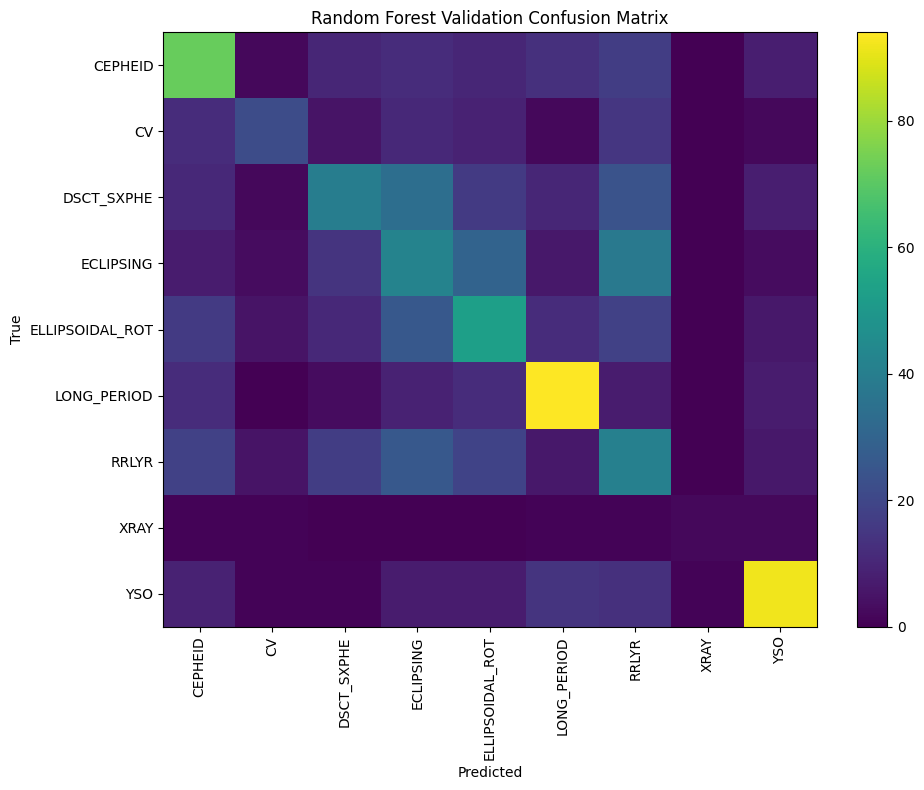

In [11]:
Labels = sorted(yVal.unique())

ConfMat = confusion_matrix(yVal, RandomForestValPred, labels=Labels)
ConfMatDf = pd.DataFrame(ConfMat, index=Labels, columns=Labels)

display(ConfMatDf)

plt.figure(figsize=(10, 8))
plt.imshow(ConfMat, aspect="auto")
plt.xticks(range(len(Labels)), Labels, rotation=90)
plt.yticks(range(len(Labels)), Labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Random Forest Validation Confusion Matrix")
plt.colorbar()
plt.tight_layout()
plt.show()


## Step 11 — Feature Importance

Random Forest impurity-based feature importance is extracted from the trained model, ranked, and plotted.


,Feature,Importance
19,EtaVonNeumann,0.045594
2,OriginalFluxStd,0.041330
28,LsPeriod3,0.038763
21,MedianAbsSuccessiveDiff,0.037994
20,MaxAbsSlope,0.036615
24,LsBestPeriod,0.036490
27,LsPeriod2,0.034865
3,CadenceCount,0.033675
18,TailRatio,0.033338
25,LsMaxPower,0.032448


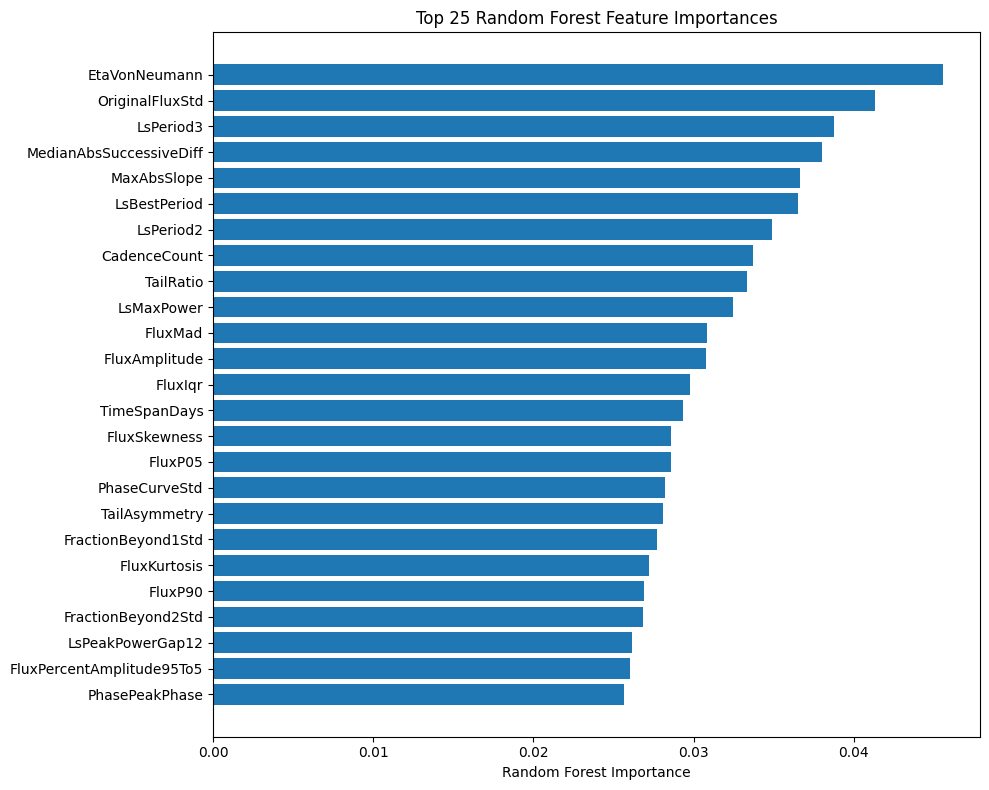

In [12]:
RfClassifier = RandomForestModel.named_steps["model"]

ImportanceDf = pd.DataFrame({
    "Feature": FeatureColumns,
    "Importance": RfClassifier.feature_importances_,
}).sort_values("Importance", ascending=False)

display(ImportanceDf.head(30))

TopN = 25
TopImportance = ImportanceDf.head(TopN).iloc[::-1]

plt.figure(figsize=(10, 8))
plt.barh(TopImportance["Feature"], TopImportance["Importance"])
plt.xlabel("Random Forest Importance")
plt.title(f"Top {TopN} Random Forest Feature Importances")
plt.tight_layout()
plt.show()


## Step 12 — Permutation Importance

Permutation importance provides a held-out complement to impurity-based importance. Each validation predictor is shuffled while the trained model remains fixed, and the resulting performance change measures model dependence on that predictor.


,Feature,PermutationImportanceMean,PermutationImportanceStd
0,MedianAbsSuccessiveDiff,0.038948,0.003697
1,CadenceCount,0.035410,0.005854
2,OriginalFluxStd,0.027764,0.010317
3,FluxPercentAmplitude95To5,0.025164,0.005856
4,FluxKurtosis,0.020947,0.005448
5,LsPeriod3,0.020566,0.001594
6,LsPeriod2,0.020173,0.007307
7,LsBestPeriod,0.019656,0.004776
8,PhaseCurveStd,0.016262,0.006504
9,MaxAbsSlope,0.015301,0.008175


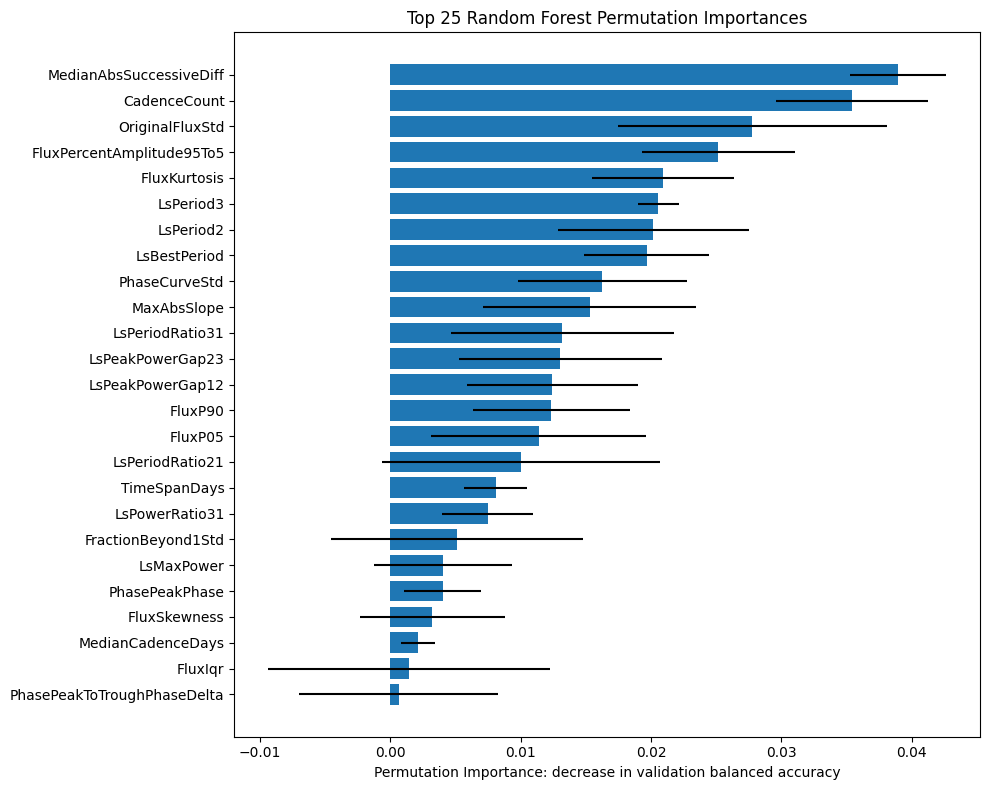

6216

In [13]:
from sklearn.inspection import permutation_importance
import gc

# Remove any large stale permutation result from an earlier run.
for VariableName in [
    "PermutationResult",
    "PermutationImportanceDf",
    "TopPermutationImportance",
]:
    if VariableName in globals():
        del globals()[VariableName]

gc.collect()

# n_jobs=1 avoids duplicating XVal and model data across worker processes.
# Five repeats are normally enough for this diagnostic analysis.
PermutationResult = permutation_importance(
    RandomForestModel,
    XVal,
    yVal,
    n_repeats=5,
    random_state=RandomState,
    scoring="balanced_accuracy",
    n_jobs=2,
)

# Copy only the compact summary arrays that are needed later.
PermutationImportanceDf = pd.DataFrame({
    "Feature": FeatureColumns,
    "PermutationImportanceMean":
        PermutationResult.importances_mean.copy(),
    "PermutationImportanceStd":
        PermutationResult.importances_std.copy(),
}).sort_values(
    "PermutationImportanceMean",
    ascending=False,
).reset_index(drop=True)

# The full result also contains an
# n_features × n_repeats importance matrix.
# It is no longer needed after extracting mean and standard deviation.
del PermutationResult
gc.collect()

display(PermutationImportanceDf.head(30))

TopN = 25
TopPermutationImportance = (
    PermutationImportanceDf
    .head(TopN)
    .iloc[::-1]
    .copy()
)

plt.figure(figsize=(10, 8))
plt.barh(
    TopPermutationImportance["Feature"],
    TopPermutationImportance["PermutationImportanceMean"],
    xerr=TopPermutationImportance["PermutationImportanceStd"],
)
plt.xlabel(
    "Permutation Importance: decrease in validation balanced accuracy"
)
plt.title(f"Top {TopN} Random Forest Permutation Importances")
plt.tight_layout()
plt.show()
plt.close()

del TopPermutationImportance
gc.collect()

## Step 13 — Final Test Evaluation

The selected Random Forest is evaluated on the held-out test set using accuracy, balanced accuracy, and per-family classification metrics.


In [14]:
RandomForestTestPred = RandomForestModel.predict(XTest)

RandomForestTestAccuracy = accuracy_score(yTest, RandomForestTestPred)
RandomForestTestBalancedAccuracy = balanced_accuracy_score(yTest, RandomForestTestPred)

print("Random Forest Test Accuracy:", RandomForestTestAccuracy)
print("Random Forest Test Balanced Accuracy:", RandomForestTestBalancedAccuracy)
print()
print(classification_report(yTest, RandomForestTestPred))


Random Forest Test Accuracy: 0.3970722781335773
Random Forest Test Balanced Accuracy: 0.34497167039774845

                 precision    recall  f1-score   support

        CEPHEID       0.47      0.52      0.49       145
             CV       0.47      0.22      0.30        77
     DSCT_SXPHE       0.29      0.23      0.26       145
      ECLIPSING       0.25      0.28      0.26       144
ELLIPSOIDAL_ROT       0.33      0.32      0.32       148
    LONG_PERIOD       0.67      0.64      0.65       144
          RRLYR       0.16      0.23      0.19       137
           XRAY       0.00      0.00      0.00         7
            YSO       0.73      0.66      0.69       146

       accuracy                           0.40      1093
      macro avg       0.37      0.34      0.35      1093
   weighted avg       0.42      0.40      0.40      1093



/home/jamesliang/.local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/jamesliang/.local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/jamesliang/.local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0]

## Step 14 — Error Analysis: Correct vs Incorrect and Accuracy by Data Source

This section uses row-level predictions to diagnose *why* the model is making mistakes, not just how often it is wrong.

Two quick, high-value checks are included:

1. Compare correctly classified vs incorrectly classified samples using key period/amplitude/power features.
2. Compare accuracy by data provenance/source, such as SPOC, QLP, and TESSCut when the provenance column is available.

In [15]:
def firstExistingColumn(Df, CandidateColumns):
    for Col in CandidateColumns:
        if Col in Df.columns:
            return Col
    return None


def buildErrorAnalysisDf(SourceDf, X, y, SplitName):
    Df = SourceDf.copy()
    Df["split"] = SplitName
    Df["label"] = y.values
    Df["prediction"] = RandomForestModel.predict(X)
    Df["correct"] = Df["prediction"] == Df["label"]
    return Df


TrainErrorDf = buildErrorAnalysisDf(TrainDf, XTrain, yTrain, "train")
ValErrorDf = buildErrorAnalysisDf(ValDf, XVal, yVal, "validation")
TestErrorDf = buildErrorAnalysisDf(TestDf, XTest, yTest, "test")

ErrorAnalysisDf = pd.concat(
    [TrainErrorDf, ValErrorDf, TestErrorDf],
    ignore_index=True,
)

print("Random Forest accuracy by split:")
display(
    ErrorAnalysisDf
    .groupby("split")["correct"]
    .agg(accuracy="mean", sample_count="size")
    .reset_index()
)

# Pick the most useful available columns for the quick correct-vs-incorrect comparison.
BestPeriodColumn = firstExistingColumn(
    ErrorAnalysisDf,
    [
        "BestPeriod",
        "LombScargleBestPeriod",
        "LsBestPeriod",
        "Period",
        "period",
        "best_period",
        "Period1",
        "LsPeak1Period",
    ],
)

AmplitudeColumn = firstExistingColumn(
    ErrorAnalysisDf,
    [
        "FluxAmplitude",
        "FluxPercentAmplitude95To5",
        "FluxPercentAmplitude90To10",
        "Amplitude",
        "amplitude",
    ],
)

PowerColumn = firstExistingColumn(
    ErrorAnalysisDf,
    [
        "BestPower",
        "LombScargleBestPower",
        "LsBestPower",
        "LsPeak1Power",
        "Power1",
        "power",
    ],
)

DiagnosticColumns = [
    Col for Col in [BestPeriodColumn, AmplitudeColumn, PowerColumn]
    if Col is not None and Col in ErrorAnalysisDf.columns
]

print("Columns used for correct-vs-incorrect comparison:", DiagnosticColumns)

if DiagnosticColumns:
    CorrectVsIncorrectDf = (
        ErrorAnalysisDf
        .groupby("correct")[DiagnosticColumns]
        .agg(["mean", "median", "std", "count"])
    )
    display(CorrectVsIncorrectDf)
else:
    print("No matching period/amplitude/power diagnostic columns were found.")

# Accuracy by data source/provenance. This is important because SPOC, QLP, and TESSCut can have different noise and preprocessing behavior.
ProvenanceColumn = firstExistingColumn(
    ErrorAnalysisDf,
    ["Provenance", "provenance", "Source", "source", "LightCurveSource", "DataSource"],
)

if ProvenanceColumn is not None:
    print(f"Accuracy by data source using column: {ProvenanceColumn}")
    AccuracyBySourceDf = (
        ErrorAnalysisDf
        .groupby(["split", ProvenanceColumn])["correct"]
        .agg(accuracy="mean", sample_count="size")
        .reset_index()
        .sort_values(["split", "accuracy"], ascending=[True, False])
    )
    display(AccuracyBySourceDf)
else:
    print("No provenance/source column found. Accuracy-by-source analysis was skipped.")

# Top validation/test confusion pairs are often easier to interpret than the full confusion matrix.
TopConfusionPairsDf = (
    ErrorAnalysisDf
    .query("split in ['validation', 'test'] and correct == False")
    .groupby(["label", "prediction"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
    .head(15)
)

print("Top validation/test confusion pairs:")
display(TopConfusionPairsDf)


Random Forest accuracy by split:


,split,accuracy,sample_count
0,test,0.397072,1093
1,train,1.000000,5096
2,validation,0.419414,1092


Columns used for correct-vs-incorrect comparison: ['LsBestPeriod', 'FluxAmplitude']


LsBestPeriod                             FluxAmplitude                            
                mean     median        std count          mean     median        std count
correct                                                                                   
False      17.442924  14.398578  15.233131  1293     31.655373  23.523925  28.503602  1293
True       16.618259  14.347948  15.943959  5988     30.263930  21.801732  29.448123  5988

Accuracy by data source using column: Provenance


,split,Provenance,accuracy,sample_count
1,test,SPOC,0.777778,72
0,test,QLP,0.684492,187
2,test,TESSCut,0.299760,834
3,train,QLP,1.000000,988
4,train,SPOC,1.000000,353
5,train,TESSCut,1.000000,3755
7,validation,SPOC,0.785714,84
6,validation,QLP,0.691011,178
8,validation,TESSCut,0.324096,830


Top validation/test confusion pairs:


,label,prediction,count
26,ECLIPSING,RRLYR,74
19,DSCT_SXPHE,RRLYR,63
16,DSCT_SXPHE,ECLIPSING,62
31,ELLIPSOIDAL_ROT,ECLIPSING,56
45,RRLYR,ECLIPSING,52
33,ELLIPSOIDAL_ROT,RRLYR,50
5,CEPHEID,RRLYR,49
24,ECLIPSING,ELLIPSOIDAL_ROT,49
44,RRLYR,DSCT_SXPHE,44
42,RRLYR,CEPHEID,41


## Step 15 — Save Useful Outputs

The model-comparison table, feature-importance table, and validation confusion matrix are saved under `OutputDir` for reporting and manuscript traceability.


In [16]:
# Save summary artifacts
ComparisonPath = OutputDir / "model_comparison_validation.csv"
ImportancePath = OutputDir / "random_forest_feature_importance.csv"
PermutationImportancePath = OutputDir / "random_forest_permutation_importance.csv"
ConfusionPath = OutputDir / "random_forest_validation_confusion_matrix.csv"
ErrorAnalysisPath = OutputDir / "random_forest_error_analysis.parquet"
AccuracyBySourcePath = OutputDir / "random_forest_accuracy_by_source.csv"
TopConfusionPairsPath = OutputDir / "random_forest_top_confusion_pairs.csv"

ComparisonDf.to_csv(ComparisonPath, index=False)
ImportanceDf.to_csv(ImportancePath, index=False)
if "PermutationImportanceDf" in globals():
    PermutationImportanceDf.to_csv(PermutationImportancePath, index=False)
ConfMatDf.to_csv(ConfusionPath)
if "ErrorAnalysisDf" in globals():
    ErrorAnalysisDf.to_parquet(ErrorAnalysisPath, index=False)
if "AccuracyBySourceDf" in globals():
    AccuracyBySourceDf.to_csv(AccuracyBySourcePath, index=False)
if "TopConfusionPairsDf" in globals():
    TopConfusionPairsDf.to_csv(TopConfusionPairsPath, index=False)

# Save row-level train / validation / test predictions.
# These files keep the original metadata/features and append prediction columns,
# which makes later error analysis much easier.
def BuildPredictionOutputDf(SourceDf, X, y, SplitName):
    OutputDf = SourceDf.copy()

    LogisticPred = LogisticModel.predict(X)
    RandomForestPred = RandomForestModel.predict(X)

    OutputDf["Split"] = SplitName
    OutputDf["ActualFamily"] = y.values
    OutputDf["LogisticRegressionPrediction"] = LogisticPred
    OutputDf["RandomForestPrediction"] = RandomForestPred
    OutputDf["LogisticRegressionCorrect"] = OutputDf["ActualFamily"] == OutputDf["LogisticRegressionPrediction"]
    OutputDf["RandomForestCorrect"] = OutputDf["ActualFamily"] == OutputDf["RandomForestPrediction"]

    return OutputDf

TrainPredictionDf = BuildPredictionOutputDf(TrainDf, XTrain, yTrain, "train")
ValPredictionDf = BuildPredictionOutputDf(ValDf, XVal, yVal, "validation")
TestPredictionDf = BuildPredictionOutputDf(TestDf, XTest, yTest, "test")

TrainPredictionPath = OutputDir / "train_predictions.parquet"
ValPredictionPath = OutputDir / "validation_predictions.parquet"
TestPredictionPath = OutputDir / "test_predictions.parquet"

TrainPredictionDf.to_parquet(TrainPredictionPath, index=False)
ValPredictionDf.to_parquet(ValPredictionPath, index=False)
TestPredictionDf.to_parquet(TestPredictionPath, index=False)

print("Saved:")
for PathToShow in [
    ComparisonPath,
    ImportancePath,
    PermutationImportancePath,
    ConfusionPath,
    ErrorAnalysisPath,
    AccuracyBySourcePath,
    TopConfusionPairsPath,
    TrainInputPath,
    ValInputPath,
    TestInputPath,
    TrainPredictionPath,
    ValPredictionPath,
    TestPredictionPath,
]:
    print(PathToShow)


Saved:
/data/projects/TESS_Research_Publication/results/controlled_analysis/model_comparison_validation.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/random_forest_feature_importance.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/random_forest_permutation_importance.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/random_forest_validation_confusion_matrix.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/random_forest_error_analysis.parquet
/data/projects/TESS_Research_Publication/results/controlled_analysis/random_forest_accuracy_by_source.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/random_forest_top_confusion_pairs.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/train_input.parquet
/data/projects/TESS_Research_Publication/results/controlled_analysis/validation_input.parquet
/data/projects/TESS_Research_Publication/results/controlled

## Step 16 — Findings, Diagnosis, Key Insights, Bottlenecks, and Next Steps

This section is generated from the actual Python objects created in the preceding steps. No model metrics, sample counts, provenance results, or confusion counts are hardcoded.


In [17]:
from IPython.display import Markdown, display


def _formatMetric(Value, Digits=3):
    if pd.isna(Value):
        return "N/A"
    return f"{float(Value):.{Digits}f}"


def _displayTable(Df, FloatDigits=3):
    """Display a DataFrame without requiring the optional tabulate package."""
    DisplayDf = Df.copy()
    FloatColumns = [
        ColumnName
        for ColumnName in DisplayDf.columns
        if pd.api.types.is_float_dtype(DisplayDf[ColumnName])
    ]
    FormatMap = {
        ColumnName: f"{{:.{FloatDigits}f}}"
        for ColumnName in FloatColumns
    }
    display(
        DisplayDf.style
        .format(FormatMap, na_rep="N/A")
        .hide(axis="index")
    )


# 1. Model comparison and split-level Random Forest performance
RequiredComparisonColumns = {
    "Model",
    "ValidationAccuracy",
    "ValidationBalancedAccuracy",
}
MissingComparisonColumns = sorted(
    RequiredComparisonColumns - set(ComparisonDf.columns)
)
if MissingComparisonColumns:
    raise ValueError(
        "ComparisonDf is missing required columns: "
        + str(MissingComparisonColumns)
    )

ModelSummaryDf = ComparisonDf[
    [
        "Model",
        "ValidationAccuracy",
        "ValidationBalancedAccuracy",
    ]
].copy()
ModelSummaryDf = ModelSummaryDf.rename(
    columns={
        "ValidationAccuracy": "Validation accuracy",
        "ValidationBalancedAccuracy": "Validation balanced accuracy",
    }
)

SplitSummaryDf = (
    ErrorAnalysisDf
    .groupby("split", as_index=False)["correct"]
    .agg(Accuracy="mean", **{"Sample count": "size"})
)
PreferredSplitOrder = pd.CategoricalDtype(
    ["train", "validation", "test"], ordered=True
)
SplitSummaryDf["split"] = SplitSummaryDf["split"].astype(
    PreferredSplitOrder
)
SplitSummaryDf = (
    SplitSummaryDf
    .sort_values("split")
    .rename(columns={"split": "Split"})
)
SplitSummaryDf["Split"] = (
    SplitSummaryDf["Split"].astype(str).str.title()
)

LogisticRow = ComparisonDf[
    ComparisonDf["Model"].astype(str).str.contains(
        "Logistic", case=False, na=False
    )
]
RandomForestRow = ComparisonDf[
    ComparisonDf["Model"].astype(str).str.contains(
        "Random Forest", case=False, na=False
    )
]

if len(LogisticRow) and len(RandomForestRow):
    LogisticAccuracy = float(
        LogisticRow.iloc[0]["ValidationAccuracy"]
    )
    RandomForestAccuracy = float(
        RandomForestRow.iloc[0]["ValidationAccuracy"]
    )
    AccuracyImprovement = RandomForestAccuracy - LogisticAccuracy

    LogisticBalancedAccuracy = float(
        LogisticRow.iloc[0]["ValidationBalancedAccuracy"]
    )
    RandomForestBalancedAccuracy = float(
        RandomForestRow.iloc[0]["ValidationBalancedAccuracy"]
    )
    BalancedAccuracyImprovement = (
        RandomForestBalancedAccuracy - LogisticBalancedAccuracy
    )
else:
    AccuracyImprovement = np.nan
    BalancedAccuracyImprovement = np.nan

SplitAccuracyLookup = {
    str(Row["Split"]).lower(): float(Row["Accuracy"])
    for _, Row in SplitSummaryDf.iterrows()
}
TrainAccuracy = SplitAccuracyLookup.get("train", np.nan)
ValidationAccuracy = SplitAccuracyLookup.get("validation", np.nan)
TestAccuracy = SplitAccuracyLookup.get("test", np.nan)

GeneralizationGap = (
    TrainAccuracy - TestAccuracy
    if np.isfinite(TrainAccuracy) and np.isfinite(TestAccuracy)
    else np.nan
)
ValidationTestDifference = (
    abs(ValidationAccuracy - TestAccuracy)
    if np.isfinite(ValidationAccuracy) and np.isfinite(TestAccuracy)
    else np.nan
)

if np.isfinite(GeneralizationGap):
    if GeneralizationGap >= 0.20:
        OverfittingText = (
            "The large train-to-test gap indicates substantial overfitting."
        )
    elif GeneralizationGap >= 0.10:
        OverfittingText = (
            "The train-to-test gap indicates moderate overfitting."
        )
    else:
        OverfittingText = "The train-to-test gap is relatively small."
else:
    OverfittingText = (
        "The train-to-test generalization gap could not be calculated."
    )

if np.isfinite(ValidationTestDifference):
    if ValidationTestDifference <= 0.03:
        StabilityText = (
            "Validation and test accuracy are close, suggesting that "
            "the held-out evaluation is reasonably stable."
        )
    else:
        StabilityText = (
            "Validation and test accuracy differ noticeably, so split "
            "sensitivity should be considered."
        )
else:
    StabilityText = "Validation/test stability could not be evaluated."

if np.isfinite(AccuracyImprovement):
    ImprovementSentence = (
        f"Random Forest improves validation accuracy by "
        f"**{_formatMetric(AccuracyImprovement)}** and validation "
        f"balanced accuracy by "
        f"**{_formatMetric(BalancedAccuracyImprovement)}** relative "
        f"to Logistic Regression."
    )
else:
    ImprovementSentence = (
        "The Random Forest-versus-Logistic Regression improvement "
        "could not be calculated."
    )


display(Markdown("### 1. Random Forest improvement over Logistic Regression"))
_displayTable(ModelSummaryDf, FloatDigits=3)
display(Markdown("**Observed Random Forest performance by split**"))
_displayTable(SplitSummaryDf, FloatDigits=3)
display(Markdown(
    "**Interpretation**\n\n"
    f"- {ImprovementSentence}\n"
    f"- {OverfittingText}\n"
    f"- {StabilityText}\n"
    f"- Train-to-test accuracy gap: **{_formatMetric(GeneralizationGap)}**.\n"
    f"- Absolute validation-to-test accuracy difference: "
    f"**{_formatMetric(ValidationTestDifference)}**."
))


# 2. Correct-versus-incorrect diagnostic feature comparison
display(Markdown("### 2. Correct-versus-incorrect diagnostic comparison"))

DiagnosticInterpretation = (
    "The simple correct-versus-incorrect diagnostic could not be evaluated."
)
DiagnosticDisplayDf = None

if "DiagnosticColumns" in globals() and DiagnosticColumns:
    ExistingDiagnosticColumns = [
        ColumnName
        for ColumnName in DiagnosticColumns
        if ColumnName in ErrorAnalysisDf.columns
    ]

    if ExistingDiagnosticColumns:
        DiagnosticRows = []
        for CorrectValue, GroupDf in ErrorAnalysisDf.groupby("correct"):
            Row = {
                "Correct?": bool(CorrectValue),
                "Count": int(len(GroupDf)),
            }
            for ColumnName in ExistingDiagnosticColumns:
                NumericValues = pd.to_numeric(
                    GroupDf[ColumnName], errors="coerce"
                )
                Row[f"Mean {ColumnName}"] = NumericValues.mean()
                Row[f"Median {ColumnName}"] = NumericValues.median()
            DiagnosticRows.append(Row)

        DiagnosticDisplayDf = (
            pd.DataFrame(DiagnosticRows)
            .sort_values("Correct?")
            .reset_index(drop=True)
        )

        DifferenceStatements = []
        for ColumnName in ExistingDiagnosticColumns:
            IncorrectValues = pd.to_numeric(
                ErrorAnalysisDf.loc[
                    ErrorAnalysisDf["correct"] == False,
                    ColumnName,
                ],
                errors="coerce",
            )
            CorrectValues = pd.to_numeric(
                ErrorAnalysisDf.loc[
                    ErrorAnalysisDf["correct"] == True,
                    ColumnName,
                ],
                errors="coerce",
            )
            IncorrectMedian = IncorrectValues.median()
            CorrectMedian = CorrectValues.median()

            if np.isfinite(IncorrectMedian) and np.isfinite(CorrectMedian):
                Scale = max(
                    abs(IncorrectMedian), abs(CorrectMedian), 1e-12
                )
                RelativeDifference = (
                    abs(IncorrectMedian - CorrectMedian) / Scale
                )
                if RelativeDifference < 0.10:
                    DifferenceText = "very similar"
                elif RelativeDifference < 0.25:
                    DifferenceText = "moderately different"
                else:
                    DifferenceText = "substantially different"

                DifferenceStatements.append(
                    f"- Median `{ColumnName}` values are "
                    f"{DifferenceText} between correct and incorrect "
                    f"samples ({_formatMetric(CorrectMedian)} versus "
                    f"{_formatMetric(IncorrectMedian)})."
                )

        if DifferenceStatements:
            DiagnosticInterpretation = "\n".join(DifferenceStatements)

DiagnosticColumnText = (
    ", ".join(DiagnosticColumns)
    if "DiagnosticColumns" in globals() and DiagnosticColumns
    else "none"
)
display(Markdown(f"Columns used: `{DiagnosticColumnText}`"))
if DiagnosticDisplayDf is not None:
    _displayTable(DiagnosticDisplayDf, FloatDigits=3)
else:
    display(Markdown("No period, amplitude, or power diagnostic columns were available."))

display(Markdown(
    "**Interpretation**\n\n"
    f"{DiagnosticInterpretation}\n\n"
    "These simple diagnostics should be treated as descriptive evidence. "
    "Similar medians do not prove that a feature is unimportant, because "
    "nonlinear interactions and distribution tails may still contribute "
    "to classification."
))


# 3. Accuracy by light-curve provenance
display(Markdown("### 3. Accuracy by light-curve provenance"))
SourceInterpretation = "Accuracy by provenance could not be evaluated."
SourceDisplayDf = None

if (
    "AccuracyBySourceDf" in globals()
    and isinstance(AccuracyBySourceDf, pd.DataFrame)
    and len(AccuracyBySourceDf)
):
    SourceDisplayDf = AccuracyBySourceDf.copy().rename(
        columns={
            "split": "Split",
            "accuracy": "Accuracy",
            "sample_count": "Sample count",
        }
    )
    ProvenanceDisplayColumn = next(
        (
            ColumnName
            for ColumnName in SourceDisplayDf.columns
            if ColumnName not in {"Split", "Accuracy", "Sample count"}
        ),
        None,
    )

    if ProvenanceDisplayColumn is not None:
        SourceDisplayDf = SourceDisplayDf.rename(
            columns={ProvenanceDisplayColumn: "Provenance"}
        )
        SourceDisplayDf["Split"] = (
            SourceDisplayDf["Split"].astype(str).str.title()
        )
        SourceDisplayDf = SourceDisplayDf[
            ["Split", "Provenance", "Accuracy", "Sample count"]
        ]

        HeldOutSourceDf = SourceDisplayDf[
            SourceDisplayDf["Split"].isin(["Validation", "Test"])
        ].copy()

        if len(HeldOutSourceDf):
            SourceAggregateRows = []
            for ProvenanceValue, GroupDf in HeldOutSourceDf.groupby(
                "Provenance"
            ):
                SourceAggregateRows.append({
                    "Provenance": ProvenanceValue,
                    "WeightedAccuracy": np.average(
                        GroupDf["Accuracy"],
                        weights=GroupDf["Sample count"],
                    ),
                    "SampleCount": GroupDf["Sample count"].sum(),
                })
            SourceAggregateDf = (
                pd.DataFrame(SourceAggregateRows)
                .sort_values("WeightedAccuracy", ascending=False)
                .reset_index(drop=True)
            )
            BestSourceRow = SourceAggregateDf.iloc[0]
            WorstSourceRow = SourceAggregateDf.iloc[-1]
            ProvenanceGap = (
                BestSourceRow["WeightedAccuracy"]
                - WorstSourceRow["WeightedAccuracy"]
            )
            SourceInterpretation = (
                f"- Best held-out provenance: "
                f"**{BestSourceRow['Provenance']}** "
                f"({_formatMetric(BestSourceRow['WeightedAccuracy'])}).\n"
                f"- Lowest held-out provenance: "
                f"**{WorstSourceRow['Provenance']}** "
                f"({_formatMetric(WorstSourceRow['WeightedAccuracy'])}).\n"
                f"- Held-out accuracy gap: "
                f"**{_formatMetric(ProvenanceGap)}**.\n"
                f"- This observed gap shows that model performance varies "
                f"with light-curve provenance in the current dataset. It "
                f"should be interpreted as an association, not by itself "
                f"as proof that provenance is the sole cause."
            )

if SourceDisplayDf is not None:
    _displayTable(SourceDisplayDf, FloatDigits=3)
else:
    display(Markdown("No provenance/source column was available."))
display(Markdown(f"**Interpretation**\n\n{SourceInterpretation}"))


# 4. Top held-out confusion pairs
display(Markdown("### 4. Top validation/test confusion pairs"))
ConfusionInterpretation = (
    "The dominant class confusions could not be summarized."
)
ConfusionDisplayDf = None

if (
    "TopConfusionPairsDf" in globals()
    and isinstance(TopConfusionPairsDf, pd.DataFrame)
    and len(TopConfusionPairsDf)
):
    ConfusionDisplayDf = TopConfusionPairsDf.copy().rename(
        columns={
            "label": "True label",
            "prediction": "Predicted label",
            "count": "Count",
        }
    )
    TopPair = ConfusionDisplayDf.iloc[0]
    ConfusionInterpretation = (
        f"The most frequent held-out error is "
        f"**{TopPair['True label']} → {TopPair['Predicted label']}** "
        f"with **{int(TopPair['Count'])}** cases. The full table "
        f"identifies which physical families remain most difficult "
        f"to separate."
    )

if ConfusionDisplayDf is not None:
    _displayTable(ConfusionDisplayDf, FloatDigits=0)
else:
    display(Markdown("No held-out confusion-pair table was available."))
display(Markdown(f"**Interpretation**\n\n{ConfusionInterpretation}"))


# 5. Current diagnosis and next steps
display(Markdown(
    """### 5. Current diagnosis

The results above support the following data-driven diagnosis:

1. The Random Forest captures nonlinear information beyond the Logistic Regression baseline.
2. Any train-to-test gap shown above quantifies overfitting directly rather than relying on an old saved result.
3. Provenance-specific performance differences are measured from the current notebook run and should be considered when interpreting overall accuracy.
4. The confusion table identifies the family pairs that are currently the dominant classification bottlenecks.
5. The correct-versus-incorrect feature summary tests whether simple signal descriptors alone distinguish easy and difficult cases.

### 6. Recommended next steps

1. Evaluate the single mixed-provenance Random Forest separately on held-out SPOC, QLP, and TESSCut predictions.
2. Report family-by-provenance performance with sample counts, so small groups are not overinterpreted.
3. Use bootstrap confidence intervals for provenance-specific accuracy and balanced accuracy.
4. Investigate the largest confusion pairs using phase-folded light-curve morphology and representative examples.
5. Compare permutation importance across provenance only after controlling for family composition and sample size.
"""
))


### 1. Random Forest improvement over Logistic Regression

Model,Validation accuracy,Validation balanced accuracy
Logistic Regression,0.271,0.322
Random Forest,0.419,0.394


**Observed Random Forest performance by split**

Split,Accuracy,Sample count
Train,1.000,5096
Validation,0.419,1092
Test,0.397,1093


**Interpretation**

- Random Forest improves validation accuracy by **0.148** and validation balanced accuracy by **0.072** relative to Logistic Regression.
- The large train-to-test gap indicates substantial overfitting.
- Validation and test accuracy are close, suggesting that the held-out evaluation is reasonably stable.
- Train-to-test accuracy gap: **0.603**.
- Absolute validation-to-test accuracy difference: **0.022**.

### 2. Correct-versus-incorrect diagnostic comparison

... (6 outputs left out)

### 4. Top validation/test confusion pairs

True label,Predicted label,Count
ECLIPSING,RRLYR,74
DSCT_SXPHE,RRLYR,63
DSCT_SXPHE,ECLIPSING,62
ELLIPSOIDAL_ROT,ECLIPSING,56
RRLYR,ECLIPSING,52
ELLIPSOIDAL_ROT,RRLYR,50
CEPHEID,RRLYR,49
ECLIPSING,ELLIPSOIDAL_ROT,49
RRLYR,DSCT_SXPHE,44
RRLYR,CEPHEID,41


**Interpretation**

The most frequent held-out error is **ECLIPSING → RRLYR** with **74** cases. The full table identifies which physical families remain most difficult to separate.

### 5. Current diagnosis

The results above support the following data-driven diagnosis:

1. The Random Forest captures nonlinear information beyond the Logistic Regression baseline.
2. Any train-to-test gap shown above quantifies overfitting directly rather than relying on an old saved result.
3. Provenance-specific performance differences are measured from the current notebook run and should be considered when interpreting overall accuracy.
4. The confusion table identifies the family pairs that are currently the dominant classification bottlenecks.
5. The correct-versus-incorrect feature summary tests whether simple signal descriptors alone distinguish easy and difficult cases.

### 6. Recommended next steps

1. Evaluate the single mixed-provenance Random Forest separately on held-out SPOC, QLP, and TESSCut predictions.
2. Report family-by-provenance performance with sample counts, so small groups are not overinterpreted.
3. Use bootstrap confidence intervals for provenance-specific accuracy and balanced accuracy.
4. Investigate the largest confusion pairs using phase-folded light-curve morphology and representative examples.
5. Compare permutation importance across provenance only after controlling for family composition and sample size.


## Step 17 — Controlled Conditional Detrending Experiment

### Goal

This experiment tests whether conditional detrending of eligible TESSCut light curves improves classification while holding the downstream modeling setup fixed.

The conditional-detrended feature table preserves the full mixed-provenance modeling sample. SPOC and QLP rows remain unchanged, while eligible TESSCut rows use features extracted from the conditionally detrended light curves.

For a controlled comparison, this step now reuses:

- the canonical train/validation/test star assignments;
- the common 39-feature predictor set;
- the canonical median-imputation pipeline;
- the canonical 500-tree Random Forest configuration with `class_weight="balanced_subsample"`;
- the canonical random state.

The analysis reports both overall held-out performance and performance restricted to the TESSCut stars within the canonical held-out test set. Therefore, the principal experimental change is the conditional detrending applied upstream to eligible TESSCut light curves.

This legacy full-dataset diagnostic is optional. If its metadata or corrected feature file is absent, the entire block is skipped and the main matched comparisons continue. An existing unversioned or stale feature file stops with a rerun instruction; regenerate it with notebook 02 before using this experiment. The controlled detrending experiment in notebook 05 is a separate analysis.


In [18]:
# Optional legacy full-dataset conditional-detrending experiment.
# Missing inputs skip only this block; an existing stale feature file is an error.
TessCutConditionalMetadataPath = Project_Root / "data" / "detrend_tesscut" / "output" / "TESSAugmented_QC_tesscut_conditional_detrended.parquet"
TessCutConditionalFeaturePath = Project_Root / "data" / "feature_extraction" / "TESS_conditional_detrended_features.parquet"
ConditionalExperimentCompleted = False
ConditionalExperimentAvailable = False
ConditionalExperimentSkipReason = None
ConditionalExperimentMissingInputs = [
    PathObj for PathObj in [TessCutConditionalMetadataPath, TessCutConditionalFeaturePath]
    if not PathObj.is_file()
]

# Never hide an existing pre-correction feature table behind the optional skip.
# Validation still runs when the metadata input is absent.
if TessCutConditionalFeaturePath.is_file():
    trv.read_corrected_features(TessCutConditionalFeaturePath)

ConditionalExperimentAvailable = not ConditionalExperimentMissingInputs
ConditionalExperimentSkipReason = (
    "Skipping optional full-dataset conditional-detrending experiment: missing "
    + ", ".join(str(PathObj) for PathObj in ConditionalExperimentMissingInputs)
    + ". Main and matched analyses will continue."
    if ConditionalExperimentMissingInputs else None
)
if not ConditionalExperimentAvailable:
    print(ConditionalExperimentSkipReason)
else:
    TessCutMetaDf = pd.read_parquet(TessCutConditionalMetadataPath)

    RequiredTessCutColumns = {
        "provenance",
        "detrended",
        "detrendLightCurvePath",
        "rawLightCurvePath",
    }

    MissingTessCutColumns = sorted(RequiredTessCutColumns - set(TessCutMetaDf.columns))
    if MissingTessCutColumns:
        raise ValueError(f"Missing required columns in metadata parquet: {MissingTessCutColumns}")

    # Keep only TESSCut rows.
    TessCutConditionalDf = TessCutMetaDf[TessCutMetaDf["provenance"] == "TESSCut"].copy()

    # Robustly convert detrended flag to boolean.
    # This handles True/False, 1/0, and common string values such as "true"/"false".
    DetrendedFlag = (
        TessCutConditionalDf["detrended"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes", "y"])
    )

    # Use detrended FITS where available; otherwise use raw FITS.
    TessCutConditionalDf["selectedLightCurvePath"] = np.where(
        DetrendedFlag,
        TessCutConditionalDf["detrendLightCurvePath"],
        TessCutConditionalDf["rawLightCurvePath"],
    )

    TessCutConditionalDf["selectedLightCurveSource"] = np.where(
        DetrendedFlag,
        "detrended",
        "raw_fallback",
    )

    # Preserve original columns but also overwrite lightCurvePath for downstream feature extraction.
    # This makes the selected path easy to consume by existing feature extraction code.
    TessCutConditionalDf["originalRawLightCurvePath"] = TessCutConditionalDf["rawLightCurvePath"]
    TessCutConditionalDf["originalDetrendLightCurvePath"] = TessCutConditionalDf["detrendLightCurvePath"]

    TessCutConditionalDf["lightCurvePath"] = TessCutConditionalDf["selectedLightCurvePath"]
    TessCutConditionalDf["rawLightCurvePath"] = TessCutConditionalDf["selectedLightCurvePath"]

    # Basic path sanity checks.
    TessCutConditionalDf["hasSelectedLightCurvePath"] = (
        TessCutConditionalDf["selectedLightCurvePath"].notna()
        & (TessCutConditionalDf["selectedLightCurvePath"].astype(str).str.len() > 0)
    )

    TessCutConditionalInputPath = OutputDir / "tesscut_conditional_detrended_metadata.parquet"
    TessCutConditionalDf.to_parquet(TessCutConditionalInputPath, index=False)

    print(f"Loaded metadata: {TessCutConditionalMetadataPath}")
    print(f"TESSCut rows: {len(TessCutConditionalDf)}")
    print(f"Saved conditional TESSCut metadata to: {TessCutConditionalInputPath}")

    display(
        TessCutConditionalDf["selectedLightCurveSource"]
        .value_counts()
        .rename_axis("selected source")
        .reset_index(name="count")
    )

    display(
        TessCutConditionalDf[[
            "provenance",
            "detrended",
            "selectedLightCurveSource",
            "selectedLightCurvePath",
            "hasSelectedLightCurvePath",
        ]].head(10)
    )


Loaded metadata: /data/projects/TESS_Research_Publication/data/detrend_tesscut/output/TESSAugmented_QC_tesscut_conditional_detrended.parquet
TESSCut rows: 5419
Saved conditional TESSCut metadata to: /data/projects/TESS_Research_Publication/results/controlled_analysis/tesscut_conditional_detrended_metadata.parquet


,selected source,count
0,detrended,3523
1,raw_fallback,1896


,provenance,detrended,selectedLightCurveSource,selectedLightCurvePath,hasSelectedLightCurvePath
0,TESSCut,False,raw_fallback,/data/projects/TESS-research/data_pipeline/TES...,True
1,TESSCut,True,detrended,/data/projects/TESS-research/detrend_tesscut/o...,True
2,TESSCut,True,detrended,/data/projects/TESS-research/detrend_tesscut/o...,True
4,TESSCut,True,detrended,/data/projects/TESS-research/detrend_tesscut/o...,True
5,TESSCut,True,detrended,/data/projects/TESS-research/detrend_tesscut/o...,True
6,TESSCut,False,raw_fallback,/data/projects/TESS-research/data_pipeline/TES...,True
8,TESSCut,False,raw_fallback,/data/projects/TESS-research/data_pipeline/TES...,True
9,TESSCut,False,raw_fallback,/data/projects/TESS-research/data_pipeline/TES...,True
10,TESSCut,True,detrended,/data/projects/TESS-research/detrend_tesscut/o...,True
11,TESSCut,True,detrended,/data/projects/TESS-research/detrend_tesscut/o...,True


### Optional conditional-detrending metadata

When both optional inputs are available, `tesscut_conditional_detrended_metadata.parquet` contains the TESSCut rows prepared here. The selected path uses the detrended FITS file when `detrended == True` and the raw FITS file otherwise. The controlled experiment below reads the corrected `TESS_conditional_detrended_features.parquet` produced by notebook 02.

When an input is absent, the availability flag disables this block and the main matched analyses continue.


In [19]:
# Availability is computed by the preceding optional-input preparation cell.
ConditionalExperimentCompleted = False
if not globals().get("ConditionalExperimentAvailable", False):
    print(globals().get("ConditionalExperimentSkipReason") or
          "Skipping optional conditional-detrending experiment: run its input-availability cell first.")
else:
    # ============================================================
    # Step 17 — Controlled conditional-detrending experiment
    # ============================================================
    # Purpose:
    # Compare the canonical mixed-provenance Random Forest with an otherwise
    # identical model whose eligible TESSCut light curves have been conditionally
    # detrended. The star identities, 39-feature schema, train/validation/test
    # assignments, and RF configuration are held fixed.

    TessCutConditionalFeaturePath = Project_Root / "data" / "feature_extraction" / "TESS_conditional_detrended_features.parquet"

    TessCutConditionalFeatureDf = trv.read_corrected_features(
        TessCutConditionalFeaturePath
    ).copy()

    TessCutConditionalFeatureDf = trv.eligible_rows(TessCutConditionalFeatureDf)
    TessCutConditionalFeatureDf = TessCutConditionalFeatureDf.dropna(
        subset=["VSXId", TargetColumn]
    ).copy()

    # ------------------------------------------------------------
    # 1. Verify schema and align to the canonical split by VSXId
    # ------------------------------------------------------------
    if "VSXId" not in TessCutConditionalFeatureDf.columns:
        raise KeyError(
            "Conditional-detrended feature table must contain VSXId so the "
            "canonical train/validation/test assignments can be reused."
        )

    MissingConditionalFeatureColumns = sorted(
        set(FeatureColumns) - set(TessCutConditionalFeatureDf.columns)
    )
    if MissingConditionalFeatureColumns:
        raise ValueError(
            "Conditional-detrended feature table is missing required model "
            f"features: {MissingConditionalFeatureColumns}"
        )

    if TargetColumn not in TessCutConditionalFeatureDf.columns:
        raise KeyError(
            f"Conditional-detrended feature table is missing {TargetColumn}."
        )

    for SplitName, SplitDf in [
        ("train", TrainDf),
        ("validation", ValDf),
        ("test", TestDf),
    ]:
        if "VSXId" not in SplitDf.columns:
            raise KeyError(
                f"Canonical {SplitName} split does not contain VSXId."
            )

    if TessCutConditionalFeatureDf["VSXId"].astype(str).duplicated().any():
        DuplicateCount = int(
            TessCutConditionalFeatureDf["VSXId"]
            .astype(str)
            .duplicated()
            .sum()
        )
        raise ValueError(
            "Conditional-detrended feature table contains duplicate VSXId "
            f"values ({DuplicateCount} duplicates)."
        )

    TessCutConditionalById = (
        TessCutConditionalFeatureDf
        .assign(VSXId=TessCutConditionalFeatureDf["VSXId"].astype(str))
        .set_index("VSXId", drop=False)
    )

    def buildConditionalSplit(CanonicalSplitDf, SplitName):
        CanonicalIds = CanonicalSplitDf["VSXId"].astype(str).tolist()

        MissingIds = [
            VSXId for VSXId in CanonicalIds
            if VSXId not in TessCutConditionalById.index
        ]
        if MissingIds:
            raise ValueError(
                f"Conditional-detrended table is missing {len(MissingIds)} "
                f"{SplitName} VSXIds; examples: {MissingIds[:10]}"
            )

        ConditionalSplitDf = (
            TessCutConditionalById
            .loc[CanonicalIds]
            .copy()
            .reset_index(drop=True)
        )

        CanonicalLabels = (
            CanonicalSplitDf[TargetColumn]
            .astype(str)
            .reset_index(drop=True)
        )
        ConditionalLabels = (
            ConditionalSplitDf[TargetColumn]
            .astype(str)
            .reset_index(drop=True)
        )

        if not CanonicalLabels.equals(ConditionalLabels):
            MismatchCount = int(
                (CanonicalLabels != ConditionalLabels).sum()
            )
            raise ValueError(
                f"{SplitName} label mismatch between canonical and "
                f"conditional-detrended tables for {MismatchCount} rows."
            )

        return ConditionalSplitDf


    TessCutConditionalTrainDf = buildConditionalSplit(TrainDf, "train")
    TessCutConditionalValDf = buildConditionalSplit(ValDf, "validation")
    TessCutConditionalTestDf = buildConditionalSplit(TestDf, "test")

    print("Canonical split alignment passed.")
    print(
        "Conditional train/validation/test:",
        len(TessCutConditionalTrainDf),
        len(TessCutConditionalValDf),
        len(TessCutConditionalTestDf),
    )
    print("Predictor count:", len(FeatureColumns))

    # ------------------------------------------------------------
    # 2. Use the exact canonical 39-feature model configuration
    # ------------------------------------------------------------
    XTessCutConditionalTrain = TessCutConditionalTrainDf[FeatureColumns]
    YTessCutConditionalTrain = TessCutConditionalTrainDf[TargetColumn]

    XTessCutConditionalVal = TessCutConditionalValDf[FeatureColumns]
    YTessCutConditionalVal = TessCutConditionalValDf[TargetColumn]

    XTessCutConditionalTest = TessCutConditionalTestDf[FeatureColumns]
    YTessCutConditionalTest = TessCutConditionalTestDf[TargetColumn]

    TessCutConditionalRfModel = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=500,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RandomState,
            )),
        ]
    )

    TessCutConditionalRfModel.fit(
        XTessCutConditionalTrain,
        YTessCutConditionalTrain,
    )

    TessCutConditionalTrainPred = TessCutConditionalRfModel.predict(
        XTessCutConditionalTrain
    )
    TessCutConditionalValPred = TessCutConditionalRfModel.predict(
        XTessCutConditionalVal
    )
    TessCutConditionalTestPred = TessCutConditionalRfModel.predict(
        XTessCutConditionalTest
    )

    # ------------------------------------------------------------
    # 3. Direct canonical-vs-detrended comparison on identical splits
    # ------------------------------------------------------------
    ControlledDetrendPerformanceDf = pd.DataFrame([
        {
            "Model": "Canonical mixed-provenance RF",
            "Split": "validation",
            "Accuracy": accuracy_score(yVal, RandomForestValPred),
            "BalancedAccuracy": balanced_accuracy_score(
                yVal, RandomForestValPred
            ),
            "SampleCount": len(yVal),
        },
        {
            "Model": "Conditional-detrended mixed-provenance RF",
            "Split": "validation",
            "Accuracy": accuracy_score(
                YTessCutConditionalVal,
                TessCutConditionalValPred,
            ),
            "BalancedAccuracy": balanced_accuracy_score(
                YTessCutConditionalVal,
                TessCutConditionalValPred,
            ),
            "SampleCount": len(YTessCutConditionalVal),
        },
        {
            "Model": "Canonical mixed-provenance RF",
            "Split": "test",
            "Accuracy": accuracy_score(yTest, RandomForestTestPred),
            "BalancedAccuracy": balanced_accuracy_score(
                yTest, RandomForestTestPred
            ),
            "SampleCount": len(yTest),
        },
        {
            "Model": "Conditional-detrended mixed-provenance RF",
            "Split": "test",
            "Accuracy": accuracy_score(
                YTessCutConditionalTest,
                TessCutConditionalTestPred,
            ),
            "BalancedAccuracy": balanced_accuracy_score(
                YTessCutConditionalTest,
                TessCutConditionalTestPred,
            ),
            "SampleCount": len(YTessCutConditionalTest),
        },
    ])

    print("Controlled conditional-detrending comparison:")
    display(ControlledDetrendPerformanceDf)

    # ------------------------------------------------------------
    # 4. TESSCut-only evaluation within the identical canonical test stars
    # ------------------------------------------------------------
    def resolveProvenanceColumn(Df):
        for ColumnName in [
            "Provenance",
            "provenance",
            "Source",
            "source",
            "LightCurveSource",
            "DataSource",
        ]:
            if ColumnName in Df.columns:
                return ColumnName
        raise KeyError("No provenance/source column found.")


    def normalizeConditionalProvenanceLabel(Value):
        """Normalize provenance labels locally for Step 17."""
        if pd.isna(Value):
            return Value

        Text = str(Value).strip()
        Upper = Text.upper()

        if "SPOC" in Upper:
            return "SPOC"
        if "QLP" in Upper:
            return "QLP"
        if "TESSCUT" in Upper or "TESS CUT" in Upper:
            return "TESSCut"

        return Text


    CanonicalProvenanceColumn = resolveProvenanceColumn(TestDf)
    ConditionalProvenanceColumn = resolveProvenanceColumn(
        TessCutConditionalTestDf
    )

    CanonicalTestProvenance = (
        TestDf[CanonicalProvenanceColumn]
        .map(normalizeConditionalProvenanceLabel)
        .reset_index(drop=True)
    )
    ConditionalTestProvenance = (
        TessCutConditionalTestDf[ConditionalProvenanceColumn]
        .map(normalizeConditionalProvenanceLabel)
        .reset_index(drop=True)
    )

    if not CanonicalTestProvenance.equals(ConditionalTestProvenance):
        raise ValueError(
            "Provenance labels differ between canonical and "
            "conditional-detrended test rows."
        )

    TessCutTestMask = CanonicalTestProvenance.eq("TESSCut").to_numpy()

    ControlledDetrendTessCutOnlyDf = pd.DataFrame([
        {
            "Model": "Canonical mixed-provenance RF",
            "EvaluationSubset": "TESSCut test stars",
            "Accuracy": accuracy_score(
                yTest.reset_index(drop=True)[TessCutTestMask],
                pd.Series(RandomForestTestPred)[TessCutTestMask],
            ),
            "BalancedAccuracy": balanced_accuracy_score(
                yTest.reset_index(drop=True)[TessCutTestMask],
                pd.Series(RandomForestTestPred)[TessCutTestMask],
            ),
            "SampleCount": int(TessCutTestMask.sum()),
        },
        {
            "Model": "Conditional-detrended mixed-provenance RF",
            "EvaluationSubset": "TESSCut test stars",
            "Accuracy": accuracy_score(
                YTessCutConditionalTest
                .reset_index(drop=True)[TessCutTestMask],
                pd.Series(TessCutConditionalTestPred)[TessCutTestMask],
            ),
            "BalancedAccuracy": balanced_accuracy_score(
                YTessCutConditionalTest
                .reset_index(drop=True)[TessCutTestMask],
                pd.Series(TessCutConditionalTestPred)[TessCutTestMask],
            ),
            "SampleCount": int(TessCutTestMask.sum()),
        },
    ])

    print("Controlled evaluation restricted to canonical TESSCut test stars:")
    display(ControlledDetrendTessCutOnlyDf)

    # ------------------------------------------------------------
    # 5. Explicit deltas: detrended minus canonical
    # ------------------------------------------------------------
    CanonicalTestRow = ControlledDetrendPerformanceDf[
        (ControlledDetrendPerformanceDf["Model"]
         == "Canonical mixed-provenance RF")
        & (ControlledDetrendPerformanceDf["Split"] == "test")
    ].iloc[0]

    DetrendedTestRow = ControlledDetrendPerformanceDf[
        (ControlledDetrendPerformanceDf["Model"]
         == "Conditional-detrended mixed-provenance RF")
        & (ControlledDetrendPerformanceDf["Split"] == "test")
    ].iloc[0]

    CanonicalTessCutRow = ControlledDetrendTessCutOnlyDf[
        ControlledDetrendTessCutOnlyDf["Model"]
        == "Canonical mixed-provenance RF"
    ].iloc[0]

    DetrendedTessCutRow = ControlledDetrendTessCutOnlyDf[
        ControlledDetrendTessCutOnlyDf["Model"]
        == "Conditional-detrended mixed-provenance RF"
    ].iloc[0]

    ControlledDetrendDeltaDf = pd.DataFrame([
        {
            "Evaluation": "Overall held-out test set",
            "AccuracyDelta":
                DetrendedTestRow["Accuracy"]
                - CanonicalTestRow["Accuracy"],
            "BalancedAccuracyDelta":
                DetrendedTestRow["BalancedAccuracy"]
                - CanonicalTestRow["BalancedAccuracy"],
        },
        {
            "Evaluation": "TESSCut stars within held-out test set",
            "AccuracyDelta":
                DetrendedTessCutRow["Accuracy"]
                - CanonicalTessCutRow["Accuracy"],
            "BalancedAccuracyDelta":
                DetrendedTessCutRow["BalancedAccuracy"]
                - CanonicalTessCutRow["BalancedAccuracy"],
        },
    ])

    print("Conditional detrending minus canonical performance:")
    display(ControlledDetrendDeltaDf)

    # Save compact Section-8-ready results.
    ControlledDetrendPerformancePath = (
        OutputDir / "controlled_conditional_detrending_performance.csv"
    )
    ControlledDetrendTessCutOnlyPath = (
        OutputDir / "controlled_conditional_detrending_tesscut_test.csv"
    )
    ControlledDetrendDeltaPath = (
        OutputDir / "controlled_conditional_detrending_deltas.csv"
    )

    ControlledDetrendPerformanceDf.to_csv(
        ControlledDetrendPerformancePath,
        index=False,
    )
    ControlledDetrendTessCutOnlyDf.to_csv(
        ControlledDetrendTessCutOnlyPath,
        index=False,
    )
    ControlledDetrendDeltaDf.to_csv(
        ControlledDetrendDeltaPath,
        index=False,
    )

    print("Saved:")
    print(ControlledDetrendPerformancePath)
    print(ControlledDetrendTessCutOnlyPath)
    print(ControlledDetrendDeltaPath)

    print()
    print("Conditional-detrended held-out test classification report:")
    print(
        classification_report(
            YTessCutConditionalTest,
            TessCutConditionalTestPred,
            zero_division=0,
        )
    )

    ConditionalExperimentCompleted = True


Canonical split alignment passed.
Conditional train/validation/test: 5096 1092 1093
Predictor count: 39
Controlled conditional-detrending comparison:


,Model,Split,Accuracy,BalancedAccuracy,SampleCount
0,Canonical mixed-provenance RF,validation,0.419414,0.394058,1092
1,Conditional-detrended mixed-provenance RF,validation,0.422161,0.396410,1092
2,Canonical mixed-provenance RF,test,0.397072,0.344972,1093
3,Conditional-detrended mixed-provenance RF,test,0.412626,0.359743,1093


Controlled evaluation restricted to canonical TESSCut test stars:


,Model,EvaluationSubset,Accuracy,BalancedAccuracy,SampleCount
0,Canonical mixed-provenance RF,TESSCut test stars,0.299760,0.251820,834
1,Conditional-detrended mixed-provenance RF,TESSCut test stars,0.315348,0.265265,834


Conditional detrending minus canonical performance:


,Evaluation,AccuracyDelta,BalancedAccuracyDelta
0,Overall held-out test set,0.015554,0.014771
1,TESSCut stars within held-out test set,0.015588,0.013445


Saved:
/data/projects/TESS_Research_Publication/results/controlled_analysis/controlled_conditional_detrending_performance.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/controlled_conditional_detrending_tesscut_test.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/controlled_conditional_detrending_deltas.csv

Conditional-detrended held-out test classification report:
                 precision    recall  f1-score   support

        CEPHEID       0.50      0.50      0.50       145
             CV       0.58      0.25      0.35        77
     DSCT_SXPHE       0.37      0.32      0.34       145
      ECLIPSING       0.28      0.28      0.28       144
ELLIPSOIDAL_ROT       0.26      0.28      0.27       148
    LONG_PERIOD       0.65      0.65      0.65       144
          RRLYR       0.19      0.28      0.23       137
           XRAY       0.00      0.00      0.00         7
            YSO       0.74      0.67      0.71       146

       a

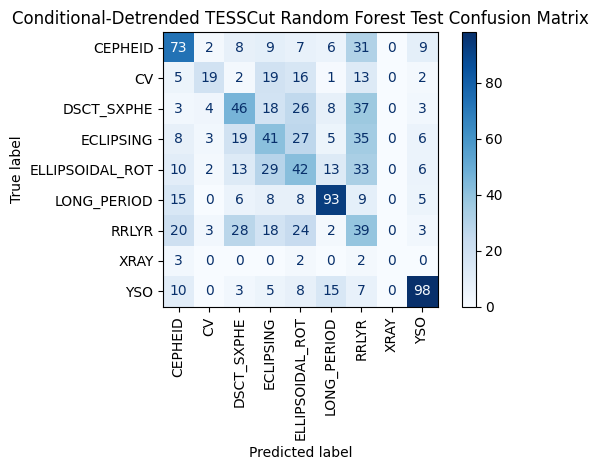

In [20]:

# ============================================================
# Conditional-detrended TESSCut confusion matrix
# ============================================================

if not globals().get("ConditionalExperimentCompleted", False):
    print(globals().get("ConditionalExperimentSkipReason") or
          "Skipping optional conditional-detrending confusion matrix: the experiment has not completed.")
else:
    from sklearn.metrics import ConfusionMatrixDisplay

    TessCutConditionalLabels = sorted(YTessCutConditionalTest.unique())

    ConfusionMatrixDisplay.from_predictions(
        YTessCutConditionalTest,
        TessCutConditionalTestPred,
        labels=TessCutConditionalLabels,
        xticks_rotation=90,
        cmap="Blues",
    )

    plt.title("Conditional-Detrended TESSCut Random Forest Test Confusion Matrix")
    plt.tight_layout()
    plt.show()


### Controlled conditional-detrending results — rerun required

The original results have been removed because the FAP feature must be refreshed for both baseline and conditionally detrended inputs. Keep the same eligible stars, canonical split membership, predictors, and model configuration. Use the newly generated comparison table to update numerical claims and interpret whether overall and TESSCut-only held-out performance improve.

If the optional inputs were absent, this block produces no new result. Its previous numerical claims must remain omitted until the optional diagnostic is regenerated and run.


## Step 18 — Phase-Folded Morphology Analysis

This experiment tests whether hand-engineered phase-folded shape descriptors add predictive information beyond the existing period, amplitude, and global-variability features. The descriptors quantify binned phase-curve amplitude, local differences, extrema sharpness, skewness, kurtosis, and low-order Fourier structure.

Phase folding uses the estimated Lomb–Scargle best period, so period errors and aliases propagate into the morphology descriptors. The experiment compares matched Random Forest configurations with and without the phase-morphology feature set.


In [21]:

# ============================================================
# Phase-folded morphology feature extraction helpers
# ============================================================

from pathlib import Path
import warnings

try:
    from astropy.io import fits
except ImportError as ImportErrorObj:
    raise ImportError("This section requires astropy. Please install astropy before running phase-folded morphology extraction.") from ImportErrorObj


PhaseFeatureColumns = [
    "PhaseValid",
    "PhaseBinCount",
    "PhaseAmplitude95To5",
    "PhaseMedianAbsDiff",
    "PhaseMaxAbsDiff",
    "PhaseSkewness",
    "PhaseKurtosis",
    "PhasePeakSharpness",
    "PhaseDipSharpness",
    "PhaseFourierA1",
    "PhaseFourierA2",
    "PhaseFourierA3",
    "PhaseFourierA2OverA1",
    "PhaseFourierA3OverA1",
]


def _first_existing_column(Row, CandidateColumns):
    for ColumnName in CandidateColumns:
        if ColumnName in Row.index:
            Value = Row[ColumnName]
            if pd.notna(Value) and str(Value).strip() != "":
                return str(Value)
    return None


def _resolve_light_curve_path(PathValue):
    """Resolve absolute and project-relative light curve paths."""
    if PathValue is None:
        return None

    PathStr = str(PathValue).strip()
    if PathStr == "":
        return None

    Candidate = Path(PathStr)
    if Candidate.exists():
        return Candidate

    ProjectRoots = [
        Project_Root,
        Project_Root / "data" / "raw",
    ]

    for Root in ProjectRoots:
        Candidate = Root / PathStr.lstrip("/")
        if Candidate.exists():
            return Candidate

    return Path(PathStr)


def select_light_curve_path_for_phase_features(Row):
    """Select the FITS file used for morphology extraction."""
    ProvenanceColumn = "Provenance" if "Provenance" in Row.index else "provenance" if "provenance" in Row.index else None
    ProvenanceValue = str(Row[ProvenanceColumn]).strip() if ProvenanceColumn is not None and pd.notna(Row[ProvenanceColumn]) else ""

    HasDetrendedFlag = "detrended" in Row.index
    IsDetrended = False
    if HasDetrendedFlag and pd.notna(Row["detrended"]):
        IsDetrended = str(Row["detrended"]).strip().lower() in ["true", "1", "yes", "y"]

    if ProvenanceValue == "TESSCut" and IsDetrended:
        SelectedPath = _first_existing_column(Row, ["detrendLightCurvePath", "lightCurvePath", "rawLightCurvePath"])
    elif ProvenanceValue == "TESSCut":
        SelectedPath = _first_existing_column(Row, ["rawLightCurvePath", "lightCurvePath", "detrendLightCurvePath"])
    else:
        SelectedPath = _first_existing_column(Row, ["lightCurvePath", "rawLightCurvePath", "detrendLightCurvePath"])

    return _resolve_light_curve_path(SelectedPath)


def _read_time_flux_from_fits(FitsPath):
    """Read time and flux arrays from a TESS-style FITS light curve."""
    if FitsPath is None or not Path(FitsPath).exists():
        return None, None

    FluxColumnPriority = [
        "PDCSAP_FLUX",
        "SAP_FLUX",
        "KSPSAP_FLUX",
        "FLUX",
        "flux",
    ]

    TimeColumnPriority = [
        "TIME",
        "time",
    ]

    try:
        with fits.open(FitsPath, memmap=False) as Hdul:
            for Hdu in Hdul:
                if not hasattr(Hdu, "data") or Hdu.data is None:
                    continue
                Data = Hdu.data
                if not hasattr(Data, "columns"):
                    continue

                ColumnNames = list(Data.columns.names)

                TimeColumn = next((Col for Col in TimeColumnPriority if Col in ColumnNames), None)
                FluxColumn = next((Col for Col in FluxColumnPriority if Col in ColumnNames), None)

                if TimeColumn is None or FluxColumn is None:
                    continue

                Time = np.asarray(Data[TimeColumn], dtype=float)
                Flux = np.asarray(Data[FluxColumn], dtype=float)

                Mask = np.isfinite(Time) & np.isfinite(Flux)
                Time = Time[Mask]
                Flux = Flux[Mask]

                if len(Time) < 30:
                    return None, None

                return Time, Flux

    except Exception:
        return None, None

    return None, None


def _robust_normalize_flux(Flux):
    Median = np.nanmedian(Flux)
    Mad = np.nanmedian(np.abs(Flux - Median))
    if not np.isfinite(Mad) or Mad <= 0:
        Std = np.nanstd(Flux)
        Scale = Std if np.isfinite(Std) and Std > 0 else 1.0
    else:
        Scale = 1.4826 * Mad

    return (Flux - Median) / Scale


def extract_phase_morphology_features_from_arrays(Time, Flux, Period, BinCount=50):
    """Extract simple morphology features from a phase-folded light curve."""
    Empty = {ColumnName: np.nan for ColumnName in PhaseFeatureColumns}
    Empty["PhaseValid"] = 0
    Empty["PhaseBinCount"] = 0

    if Time is None or Flux is None:
        return Empty

    if Period is None or not np.isfinite(Period) or Period <= 0:
        return Empty

    Mask = np.isfinite(Time) & np.isfinite(Flux)
    Time = Time[Mask]
    Flux = Flux[Mask]

    if len(Time) < 30:
        return Empty

    FluxNorm = _robust_normalize_flux(Flux)
    Phase = np.mod(Time, Period) / Period

    BinEdges = np.linspace(0, 1, BinCount + 1)
    BinIds = np.digitize(Phase, BinEdges) - 1

    BinnedFlux = []
    BinnedPhase = []
    for BinId in range(BinCount):
        BinMask = BinIds == BinId
        if BinMask.sum() >= 3:
            BinnedFlux.append(np.nanmedian(FluxNorm[BinMask]))
            BinnedPhase.append((BinEdges[BinId] + BinEdges[BinId + 1]) / 2)

    BinnedFlux = np.asarray(BinnedFlux, dtype=float)
    BinnedPhase = np.asarray(BinnedPhase, dtype=float)

    ValidMask = np.isfinite(BinnedFlux) & np.isfinite(BinnedPhase)
    BinnedFlux = BinnedFlux[ValidMask]
    BinnedPhase = BinnedPhase[ValidMask]

    if len(BinnedFlux) < 10:
        return Empty

    SortIndex = np.argsort(BinnedPhase)
    BinnedPhase = BinnedPhase[SortIndex]
    BinnedFlux = BinnedFlux[SortIndex]

    ClosedFlux = np.r_[BinnedFlux, BinnedFlux[0]]
    AdjacentDiff = np.diff(ClosedFlux)

    P05, P25, P50, P75, P95 = np.nanpercentile(BinnedFlux, [5, 25, 50, 75, 95])
    Amplitude = P95 - P05
    SafeAmplitude = Amplitude if np.isfinite(Amplitude) and Amplitude > 1e-12 else np.nan

    CenteredFlux = BinnedFlux - np.nanmean(BinnedFlux)
    FluxStd = np.nanstd(CenteredFlux)
    if np.isfinite(FluxStd) and FluxStd > 0:
        Skewness = np.nanmean((CenteredFlux / FluxStd) ** 3)
        Kurtosis = np.nanmean((CenteredFlux / FluxStd) ** 4)
    else:
        Skewness = np.nan
        Kurtosis = np.nan

    FourierAmplitudes = []
    for Harmonic in [1, 2, 3]:
        CosCoeff = np.nanmean(CenteredFlux * np.cos(2 * np.pi * Harmonic * BinnedPhase))
        SinCoeff = np.nanmean(CenteredFlux * np.sin(2 * np.pi * Harmonic * BinnedPhase))
        FourierAmplitudes.append(np.sqrt(CosCoeff ** 2 + SinCoeff ** 2))

    A1, A2, A3 = FourierAmplitudes
    SafeA1 = A1 if np.isfinite(A1) and A1 > 1e-12 else np.nan

    FeatureDict = {
        "PhaseValid": 1,
        "PhaseBinCount": len(BinnedFlux),
        "PhaseAmplitude95To5": Amplitude,
        "PhaseMedianAbsDiff": np.nanmedian(np.abs(AdjacentDiff)),
        "PhaseMaxAbsDiff": np.nanmax(np.abs(AdjacentDiff)),
        "PhaseSkewness": Skewness,
        "PhaseKurtosis": Kurtosis,
        "PhasePeakSharpness": (P95 - P75) / SafeAmplitude,
        "PhaseDipSharpness": (P25 - P05) / SafeAmplitude,
        "PhaseFourierA1": A1,
        "PhaseFourierA2": A2,
        "PhaseFourierA3": A3,
        "PhaseFourierA2OverA1": A2 / SafeA1,
        "PhaseFourierA3OverA1": A3 / SafeA1,
    }

    return FeatureDict


def extract_phase_morphology_features_for_row(Row, PeriodColumn="LsBestPeriod"):
    Period = Row[PeriodColumn] if PeriodColumn in Row.index else np.nan
    FitsPath = select_light_curve_path_for_phase_features(Row)
    Time, Flux = _read_time_flux_from_fits(FitsPath)
    return extract_phase_morphology_features_from_arrays(Time, Flux, Period)


In [22]:

# ============================================================
# Compute or load phase-folded morphology features for each split
# ============================================================

ReusePhaseFeatureCache = False  # Opt in only after a corrected run has produced manifests.

PhaseFeatureCachePaths = {
    "train": OutputDir / "phase_morphology_train.parquet",
    "validation": OutputDir / "phase_morphology_validation.parquet",
    "test": OutputDir / "phase_morphology_test.parquet",
}


def compute_phase_features_for_split(SplitDf, SplitName):
    CachePath = PhaseFeatureCachePaths[SplitName]

    ManifestPath = Path(str(CachePath) + ".science_fix_run.json")
    PhaseInputConfig = {
        "analysis": "phase_morphology",
        "ids_in_order": SplitDf["VSXId"].astype(str).tolist(),
        "periods_in_order": [
            float(Value) if pd.notna(Value) and np.isfinite(float(Value)) else None
            for Value in SplitDf["LsBestPeriod"]
        ],
        "paths_in_order": [
            str(select_light_curve_path_for_phase_features(Row))
            for _, Row in SplitDf.iterrows()
        ],
        "features": list(PhaseFeatureColumns),
    }
    if ReusePhaseFeatureCache and trv.run_cache_is_current(
        ManifestPath, inputs=[FeaturePath], config=PhaseInputConfig, outputs=[CachePath]
    ):
        CachedDf = pd.read_parquet(CachePath)
        if len(CachedDf) != len(SplitDf) or not set(PhaseFeatureColumns).issubset(CachedDf.columns):
            raise ValueError(f"Validated phase cache has an incompatible schema: {CachePath}")
        print(f"Loaded validated phase features for {SplitName}: {CachePath}")
        return CachedDf[PhaseFeatureColumns].copy()

    FeatureRows = []
    for _, Row in SplitDf.iterrows():
        FeatureRows.append(extract_phase_morphology_features_for_row(Row))

    PhaseDf = pd.DataFrame(FeatureRows)
    PhaseDf = PhaseDf.reindex(columns=PhaseFeatureColumns)

    PhaseDf.to_parquet(CachePath, index=False)
    trv.write_run_manifest(
        ManifestPath, inputs=[FeaturePath], config=PhaseInputConfig, outputs=[CachePath]
    )
    print(f"Saved phase morphology features for {SplitName}: {CachePath}")

    return PhaseDf


PhaseTrainDf = compute_phase_features_for_split(TrainDf, "train")
PhaseValDf = compute_phase_features_for_split(ValDf, "validation")
PhaseTestDf = compute_phase_features_for_split(TestDf, "test")

print("Phase feature validity rates:")
display(pd.DataFrame({
    "split": ["train", "validation", "test"],
    "valid_rate": [
        PhaseTrainDf["PhaseValid"].mean(),
        PhaseValDf["PhaseValid"].mean(),
        PhaseTestDf["PhaseValid"].mean(),
    ],
    "row_count": [
        len(PhaseTrainDf),
        len(PhaseValDf),
        len(PhaseTestDf),
    ],
}))


Saved phase morphology features for train: /data/projects/TESS_Research_Publication/results/controlled_analysis/phase_morphology_train.parquet
Saved phase morphology features for validation: /data/projects/TESS_Research_Publication/results/controlled_analysis/phase_morphology_validation.parquet
Saved phase morphology features for test: /data/projects/TESS_Research_Publication/results/controlled_analysis/phase_morphology_test.parquet
Phase feature validity rates:


,split,valid_rate,row_count
0,train,1.0,5096
1,validation,1.0,1092
2,test,1.0,1093


In [23]:

# ============================================================
# Random Forest with phase-folded morphology features
# ============================================================

TrainWithPhaseDf = pd.concat(
    [TrainDf.reset_index(drop=True), PhaseTrainDf.reset_index(drop=True)],
    axis=1,
)

ValWithPhaseDf = pd.concat(
    [ValDf.reset_index(drop=True), PhaseValDf.reset_index(drop=True)],
    axis=1,
)

TestWithPhaseDf = pd.concat(
    [TestDf.reset_index(drop=True), PhaseTestDf.reset_index(drop=True)],
    axis=1,
)

UsablePhaseFeatureColumns = [
    ColumnName for ColumnName in PhaseFeatureColumns
    if ColumnName in TrainWithPhaseDf.columns
    and ColumnName != "PhaseValid"
]

FeatureColumnsWithPhase = FeatureColumns + UsablePhaseFeatureColumns

XTrainPhase = TrainWithPhaseDf[FeatureColumnsWithPhase]
yTrainPhase = TrainWithPhaseDf[TargetColumn]

XValPhase = ValWithPhaseDf[FeatureColumnsWithPhase]
yValPhase = ValWithPhaseDf[TargetColumn]

XTestPhase = TestWithPhaseDf[FeatureColumnsWithPhase]
yTestPhase = TestWithPhaseDf[TargetColumn]

RandomForestWithPhaseModel = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=500,
        random_state=RandomState,
        n_jobs=-1,
        class_weight="balanced",
    )),
])

RandomForestWithPhaseModel.fit(XTrainPhase, yTrainPhase)

RandomForestWithPhaseTrainPred = RandomForestWithPhaseModel.predict(XTrainPhase)
RandomForestWithPhaseValPred = RandomForestWithPhaseModel.predict(XValPhase)
RandomForestWithPhaseTestPred = RandomForestWithPhaseModel.predict(XTestPhase)

PhaseModelComparisonDf = pd.DataFrame({
    "model": [
        "RF without phase morphology",
        "RF with phase morphology",
    ],
    "validation_accuracy": [
        accuracy_score(yVal, RandomForestValPred),
        accuracy_score(yValPhase, RandomForestWithPhaseValPred),
    ],
    "validation_balanced_accuracy": [
        balanced_accuracy_score(yVal, RandomForestValPred),
        balanced_accuracy_score(yValPhase, RandomForestWithPhaseValPred),
    ],
    "test_accuracy": [
        accuracy_score(yTest, RandomForestTestPred),
        accuracy_score(yTestPhase, RandomForestWithPhaseTestPred),
    ],
    "test_balanced_accuracy": [
        balanced_accuracy_score(yTest, RandomForestTestPred),
        balanced_accuracy_score(yTestPhase, RandomForestWithPhaseTestPred),
    ],
})

print("Random Forest comparison with and without phase-folded morphology features:")
display(PhaseModelComparisonDf)


Random Forest comparison with and without phase-folded morphology features:


,model,validation_accuracy,validation_balanced_accuracy,test_accuracy,test_balanced_accuracy
0,RF without phase morphology,0.419414,0.394058,0.397072,0.344972
1,RF with phase morphology,0.406593,0.383828,0.400732,0.348985


Random Forest with phase-folded morphology — test classification report:
                 precision    recall  f1-score   support

        CEPHEID       0.46      0.52      0.49       145
             CV       0.49      0.23      0.32        77
     DSCT_SXPHE       0.32      0.26      0.28       145
      ECLIPSING       0.22      0.26      0.24       144
ELLIPSOIDAL_ROT       0.27      0.27      0.27       148
    LONG_PERIOD       0.69      0.65      0.67       144
          RRLYR       0.19      0.26      0.22       137
           XRAY       0.00      0.00      0.00         7
            YSO       0.75      0.68      0.71       146

       accuracy                           0.40      1093
      macro avg       0.38      0.35      0.36      1093
   weighted avg       0.42      0.40      0.40      1093



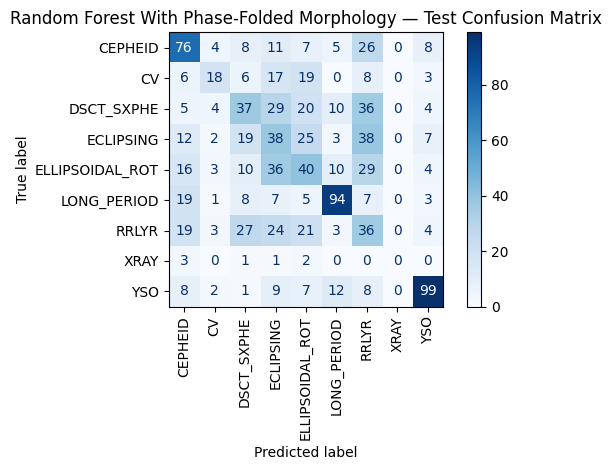

In [24]:

# ============================================================
# Phase-folded morphology model diagnostics
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

print("Random Forest with phase-folded morphology — test classification report:")
print(classification_report(yTestPhase, RandomForestWithPhaseTestPred, zero_division=0))

PhaseLabels = sorted(yTestPhase.unique())

ConfusionMatrixDisplay.from_predictions(
    yTestPhase,
    RandomForestWithPhaseTestPred,
    labels=PhaseLabels,
    xticks_rotation=90,
    cmap="Blues",
)

plt.title("Random Forest With Phase-Folded Morphology — Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [25]:

# ============================================================
# Feature importance for phase-folded morphology model
# ============================================================

RfWithPhaseClassifier = RandomForestWithPhaseModel.named_steps["model"]

PhaseImportanceDf = pd.DataFrame({
    "Feature": FeatureColumnsWithPhase,
    "Importance": RfWithPhaseClassifier.feature_importances_,
}).sort_values("Importance", ascending=False)

print("Top 30 Random Forest feature importances with phase morphology features:")
display(PhaseImportanceDf.head(30))

print("Phase morphology features only:")
display(
    PhaseImportanceDf[PhaseImportanceDf["Feature"].isin(UsablePhaseFeatureColumns)]
    .sort_values("Importance", ascending=False)
)


Top 30 Random Forest feature importances with phase morphology features:


,Feature,Importance
19,EtaVonNeumann,0.036236
2,OriginalFluxStd,0.031865
28,LsPeriod3,0.029933
24,LsBestPeriod,0.029200
20,MaxAbsSlope,0.029053
21,MedianAbsSuccessiveDiff,0.027994
27,LsPeriod2,0.027472
46,PhaseDipSharpness,0.026483
41,PhaseMedianAbsDiff,0.024739
13,FluxAmplitude,0.024650


Phase morphology features only:


,Feature,Importance
46,PhaseDipSharpness,0.026483
41,PhaseMedianAbsDiff,0.024739
40,PhaseAmplitude95To5,0.022925
42,PhaseMaxAbsDiff,0.021944
47,PhaseFourierA1,0.021553
45,PhasePeakSharpness,0.020112
43,PhaseSkewness,0.019714
44,PhaseKurtosis,0.019263
49,PhaseFourierA3,0.018671
48,PhaseFourierA2,0.018318


### Phase-folded morphology results — rerun required

The baseline predictor values are now corrected and split membership is revalidated. Recompute the morphology comparison and its extraction-success rate. Assess validation and test accuracy together with balanced accuracy before retaining the previous interpretation.


## Phase-folded morphology interpretation

Use the corrected held-out comparison to assess whether the tested descriptors add information across families. Period errors and aliases still propagate into morphology features. Conclusions about additional predictive benefit remain pending this rerun.


## Step 19 — Provenance-Specific Feature Importance Comparison

This section trains separate SPOC-only, QLP-only, and TESSCut-only Random Forest models and compares impurity-based and permutation feature importance. The analysis measures provenance-associated differences in model dependence.

Because the provenance subsets differ in sample size and family composition, these unmatched models do not isolate pipeline causality. The matched-star experiments later in the notebook provide the controlled provenance comparison.


### Provenance Distribution and Family Composition

The executed dataset contains **509 SPOC**, **1,353 QLP**, and **5,419 TESSCut** objects, for **7,281** total rows. Family composition differs across provenance sources, motivating the matched-star controls later in the notebook.


In [26]:
# ============================================================
# Provenance distribution and family-by-provenance composition
# ============================================================

PossibleProvenanceColumnsForDistribution = ["Provenance", "provenance", "Source", "source"]

ProvenanceDistributionColumn = None
for CandidateColumn in PossibleProvenanceColumnsForDistribution:
    if CandidateColumn in ModelDf.columns:
        ProvenanceDistributionColumn = CandidateColumn
        break

if ProvenanceDistributionColumn is None:
    raise KeyError(
        "Could not find a provenance/source column for the distribution analysis. "
        f"Tried: {PossibleProvenanceColumnsForDistribution}"
    )

# Normalize only display labels so equivalent capitalization is grouped together.
def normalize_provenance_label(value):
    if pd.isna(value):
        return "Missing"

    text = str(value).strip()
    upper = text.upper()

    if upper == "SPOC":
        return "SPOC"
    if upper == "QLP":
        return "QLP"
    if upper in {"TESSCUT", "TESS CUT"}:
        return "TESSCut"

    return text

ProvenanceDistributionDf = ModelDf.copy()
ProvenanceDistributionDf["ProvenanceNormalized"] = (
    ProvenanceDistributionDf[ProvenanceDistributionColumn]
    .map(normalize_provenance_label)
)

ProvenanceCountDf = (
    ProvenanceDistributionDf["ProvenanceNormalized"]
    .value_counts(dropna=False)
    .rename_axis("Provenance")
    .reset_index(name="ObjectCount")
)
ProvenanceCountDf["Percentage"] = (
    100.0 * ProvenanceCountDf["ObjectCount"] / ProvenanceCountDf["ObjectCount"].sum()
)

print("Overall provenance distribution:")
display(
    ProvenanceCountDf.style.format({
        "ObjectCount": "{:,}",
        "Percentage": "{:.2f}%",
    })
)

FamilyByProvenanceCountDf = pd.crosstab(
    ProvenanceDistributionDf[TargetColumn],
    ProvenanceDistributionDf["ProvenanceNormalized"],
    margins=True,
    margins_name="All",
)

print("Family-by-provenance object counts:")
display(FamilyByProvenanceCountDf)

FamilyWithinProvenancePercentDf = pd.crosstab(
    ProvenanceDistributionDf[TargetColumn],
    ProvenanceDistributionDf["ProvenanceNormalized"],
    normalize="columns",
) * 100.0

print("Family distribution within each provenance source:")
display(FamilyWithinProvenancePercentDf.style.format("{:.2f}%"))

ProvenanceCountDf.to_csv(
    OutputDir / "provenance_distribution.csv",
    index=False,
)
FamilyByProvenanceCountDf.to_csv(
    OutputDir / "family_by_provenance_counts.csv",
)
FamilyWithinProvenancePercentDf.to_csv(
    OutputDir / "family_within_provenance_percent.csv",
)


Overall provenance distribution:


,Provenance,ObjectCount,Percentage
0,TESSCut,"5,419",74.43%
1,QLP,"1,353",18.58%
2,SPOC,509,6.99%


Family-by-provenance object counts:


ProvenanceNormalized,QLP,SPOC,TESSCut,All
family,,,,
CEPHEID,233,64,665,962
CV,2,114,400,516
DSCT_SXPHE,211,51,706,968
ECLIPSING,110,14,832,956
ELLIPSOIDAL_ROT,151,29,802,982
LONG_PERIOD,487,118,354,959
RRLYR,17,5,895,917
XRAY,10,20,21,51
YSO,132,94,744,970


Family distribution within each provenance source:


ProvenanceNormalized,QLP,SPOC,TESSCut
family,,,
CEPHEID,17.22%,12.57%,12.27%
CV,0.15%,22.40%,7.38%
DSCT_SXPHE,15.59%,10.02%,13.03%
ECLIPSING,8.13%,2.75%,15.35%
ELLIPSOIDAL_ROT,11.16%,5.70%,14.80%
LONG_PERIOD,35.99%,23.18%,6.53%
RRLYR,1.26%,0.98%,16.52%
XRAY,0.74%,3.93%,0.39%
YSO,9.76%,18.47%,13.73%


### Predictor-set consistency for provenance-specific models

The phase-folded morphology augmentation is a separate diagnostic. Provenance-specific Random Forest models use the same frozen 39 predictors (`FeatureColumns`) as the principal and matched-star experiments. This keeps feature spaces consistent across the corrected analyses.


In [27]:

# ============================================================
# Provenance-specific Random Forest models + feature importance comparison
# ============================================================

from sklearn.inspection import permutation_importance

# ------------------------------------------------------------
# 1. Use the same final predictor set as the principal and matched analyses
# ------------------------------------------------------------
# Phase-morphology augmentation is a separate diagnostic. Provenance-specific
# comparisons use the same frozen FeatureColumns set as the main Random Forest
# and matched-star experiments.
# This keeps the provenance comparisons controlled and directly comparable.
ProvenanceComparisonDfForTraining = ModelDf.copy()
ProvenanceComparisonFeatureColumns = list(FeatureColumns)

print(
    "Using the same filtered predictor set as the principal and matched analyses: "
    f"{len(ProvenanceComparisonFeatureColumns)} features."
)

assert ProvenanceComparisonFeatureColumns == list(FeatureColumns), (
    "Provenance-specific models must use the same FeatureColumns as the "
    "principal and matched-star analyses."
)


# ------------------------------------------------------------
# 2. Identify provenance column
# ------------------------------------------------------------
PossibleProvenanceColumns = ["Provenance", "provenance", "Source", "source"]

ProvenanceColumn = None
for CandidateColumn in PossibleProvenanceColumns:
    if CandidateColumn in ProvenanceComparisonDfForTraining.columns:
        ProvenanceColumn = CandidateColumn
        break

if ProvenanceColumn is None:
    raise KeyError(
        "Could not find a provenance/source column. "
        f"Tried: {PossibleProvenanceColumns}"
    )

print(f"Using provenance column: {ProvenanceColumn}")


# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------

def train_provenance_rf_model(
    InputDf,
    ProvenanceName,
    FeatureColumnsForModel,
    TargetColumnName,
    ProvenanceColumnName,
    random_state=42,
    test_size=0.30,
):
    """Train a provenance-specific RF model and return model/split/results."""

    SourceDf = InputDf[InputDf[ProvenanceColumnName] == ProvenanceName].copy()

    if SourceDf.empty:
        raise ValueError(f"No rows found for provenance: {ProvenanceName}")

    ClassCounts = SourceDf[TargetColumnName].value_counts().sort_index()

    # Stratified splitting requires at least two examples per class.
    KeepClasses = ClassCounts[ClassCounts >= 2].index
    DroppedClasses = ClassCounts[ClassCounts < 2]

    if len(DroppedClasses) > 0:
        print(f"\n{ProvenanceName}: dropping classes with fewer than 2 samples before stratified split:")
        display(DroppedClasses)

    SourceDf = SourceDf[SourceDf[TargetColumnName].isin(KeepClasses)].copy()

    if SourceDf[TargetColumnName].nunique() < 2:
        raise ValueError(
            f"{ProvenanceName}: fewer than two classes remain after filtering; "
            "cannot train classifier."
        )

    X = SourceDf[FeatureColumnsForModel]
    y = SourceDf[TargetColumnName]

    XTrainProv, XTestProv, yTrainProv, yTestProv = train_test_split(
        X,
        y,
        test_size=test_size,
        stratify=y,
        random_state=random_state,
    )

    Model = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=500,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=random_state,
            )),
        ]
    )

    Model.fit(XTrainProv, yTrainProv)

    TrainPred = Model.predict(XTrainProv)
    TestPred = Model.predict(XTestProv)

    AccuracyDf = pd.DataFrame([
        {
            "Provenance": ProvenanceName,
            "split": "train",
            "accuracy": accuracy_score(yTrainProv, TrainPred),
            "balanced_accuracy": balanced_accuracy_score(yTrainProv, TrainPred),
            "sample_count": len(yTrainProv),
        },
        {
            "Provenance": ProvenanceName,
            "split": "test",
            "accuracy": accuracy_score(yTestProv, TestPred),
            "balanced_accuracy": balanced_accuracy_score(yTestProv, TestPred),
            "sample_count": len(yTestProv),
        },
    ])

    return {
        "model": Model,
        "x_train": XTrainProv,
        "x_test": XTestProv,
        "y_train": yTrainProv,
        "y_test": yTestProv,
        "test_pred": TestPred,
        "accuracy_df": AccuracyDf,
        "class_counts": ClassCounts,
    }


def build_rf_feature_importance_df(model, feature_columns, provenance_name):
    """Return Random Forest built-in feature importance for one provenance-specific model."""
    RfEstimator = model.named_steps["model"] if hasattr(model, "named_steps") else model

    return (
        pd.DataFrame({
            "Provenance": provenance_name,
            "Feature": list(feature_columns),
            "RFImportance": RfEstimator.feature_importances_
        })
        .sort_values("RFImportance", ascending=False)
        .reset_index(drop=True)
    )


def build_permutation_importance_df(
    model,
    x_test,
    y_test,
    feature_columns,
    provenance_name,
    scoring="balanced_accuracy",
    n_repeats=50,
    random_state=42
):
    """Return permutation importance for one provenance-specific model."""
    print(f"Permutation importance repeats: {n_repeats}")
    perm_result = permutation_importance(
        model,
        x_test,
        y_test,
        scoring=scoring,
        n_repeats=n_repeats,
        random_state=random_state,
        n_jobs=-1
    )

    return (
        pd.DataFrame({
            "Provenance": provenance_name,
            "Feature": list(feature_columns),
            "PermutationImportanceMean": perm_result.importances_mean,
            "PermutationImportanceStd": perm_result.importances_std
        })
        .sort_values("PermutationImportanceMean", ascending=False)
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# 4. Train provenance-specific RF models
# ------------------------------------------------------------

SpocResults = train_provenance_rf_model(
    ProvenanceComparisonDfForTraining,
    "SPOC",
    ProvenanceComparisonFeatureColumns,
    TargetColumn,
    ProvenanceColumn,
    random_state=RandomState,
)

QlpResults = train_provenance_rf_model(
    ProvenanceComparisonDfForTraining,
    "QLP",
    ProvenanceComparisonFeatureColumns,
    TargetColumn,
    ProvenanceColumn,
    random_state=RandomState,
)

TessCutResults = train_provenance_rf_model(
    ProvenanceComparisonDfForTraining,
    "TESSCut",
    ProvenanceComparisonFeatureColumns,
    TargetColumn,
    ProvenanceColumn,
    random_state=RandomState,
)

# Expose variables using names expected by the later comparison logic.
SpocRfModel = SpocResults["model"]
QlpRfModel = QlpResults["model"]
TessCutRfModel = TessCutResults["model"]

XSpocTest = SpocResults["x_test"]
YSpocTest = SpocResults["y_test"]

XQlpTest = QlpResults["x_test"]
YQlpTest = QlpResults["y_test"]

XTessCutTest = TessCutResults["x_test"]
YTessCutTest = TessCutResults["y_test"]

ProvenanceSpecificAccuracyDf = pd.concat(
    [
        SpocResults["accuracy_df"],
        QlpResults["accuracy_df"],
        TessCutResults["accuracy_df"],
    ],
    ignore_index=True,
)

print("Provenance-specific Random Forest performance:")
display(ProvenanceSpecificAccuracyDf)


# ------------------------------------------------------------
# 5. RF built-in feature importance
# ------------------------------------------------------------

SpocFeatureImportanceDf = build_rf_feature_importance_df(
    SpocRfModel,
    ProvenanceComparisonFeatureColumns,
    "SPOC"
)

QlpFeatureImportanceDf = build_rf_feature_importance_df(
    QlpRfModel,
    ProvenanceComparisonFeatureColumns,
    "QLP"
)

TessCutFeatureImportanceDf = build_rf_feature_importance_df(
    TessCutRfModel,
    ProvenanceComparisonFeatureColumns,
    "TESSCut"
)

ProvenanceFeatureImportanceDf = pd.concat(
    [SpocFeatureImportanceDf, QlpFeatureImportanceDf, TessCutFeatureImportanceDf],
    ignore_index=True
)

print("Top RF built-in feature importances by provenance:")
display(
    ProvenanceFeatureImportanceDf
    .groupby("Provenance", group_keys=False)
    .head(10)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Permutation importance
# ------------------------------------------------------------

SpocPermutationImportanceDf = build_permutation_importance_df(
    SpocRfModel,
    XSpocTest,
    YSpocTest,
    ProvenanceComparisonFeatureColumns,
    "SPOC",
    random_state=RandomState,
)

QlpPermutationImportanceDf = build_permutation_importance_df(
    QlpRfModel,
    XQlpTest,
    YQlpTest,
    ProvenanceComparisonFeatureColumns,
    "QLP",
    random_state=RandomState,
)

TessCutPermutationImportanceDf = build_permutation_importance_df(
    TessCutRfModel,
    XTessCutTest,
    YTessCutTest,
    ProvenanceComparisonFeatureColumns,
    "TESSCut",
    random_state=RandomState,
)

ProvenancePermutationImportanceDf = pd.concat(
    [SpocPermutationImportanceDf, QlpPermutationImportanceDf, TessCutPermutationImportanceDf],
    ignore_index=True
)

print("Top permutation importances by provenance:")
display(
    ProvenancePermutationImportanceDf
    .groupby("Provenance", group_keys=False)
    .head(10)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Side-by-side summaries
# ------------------------------------------------------------

TopN = 10

TopRfImportanceSummaryDf = (
    ProvenanceFeatureImportanceDf
    .groupby("Provenance", group_keys=False)
    .head(TopN)
    .assign(Rank=lambda df: df.groupby("Provenance").cumcount() + 1)
    .pivot(index="Rank", columns="Provenance", values="Feature")
)

TopPermutationImportanceSummaryDf = (
    ProvenancePermutationImportanceDf
    .groupby("Provenance", group_keys=False)
    .head(TopN)
    .assign(Rank=lambda df: df.groupby("Provenance").cumcount() + 1)
    .pivot(index="Rank", columns="Provenance", values="Feature")
)

print("Top RF built-in feature importance comparison:")
display(TopRfImportanceSummaryDf)

print("Top permutation importance comparison:")
display(TopPermutationImportanceSummaryDf)


Using the same filtered predictor set as the principal and matched analyses: 39 features.
Using provenance column: Provenance
Provenance-specific Random Forest performance:


,Provenance,split,accuracy,balanced_accuracy,sample_count
0,SPOC,train,1.000000,1.000000,356
1,SPOC,test,0.732026,0.553974,153
2,QLP,train,1.000000,1.000000,947
3,QLP,test,0.682266,0.443652,406
4,TESSCut,train,0.999736,0.999823,3793
5,TESSCut,test,0.303198,0.255617,1626


Top RF built-in feature importances by provenance:


,Provenance,Feature,RFImportance
0,SPOC,OriginalFluxStd,0.080548
1,SPOC,LsBestPeriod,0.067290
2,SPOC,LsPeriod2,0.063920
3,SPOC,LsPeriod3,0.058608
4,SPOC,MedianAbsSuccessiveDiff,0.043330
5,SPOC,EtaVonNeumann,0.041388
6,SPOC,FluxMad,0.038028
7,SPOC,FluxP95,0.036469
8,SPOC,FluxIqr,0.035859
9,SPOC,MaxAbsSlope,0.034950


Permutation importance repeats: 50
Permutation importance repeats: 50
Permutation importance repeats: 50
Top permutation importances by provenance:


,Provenance,Feature,PermutationImportanceMean,PermutationImportanceStd
0,SPOC,OriginalFluxStd,0.044069,0.023647
1,SPOC,MaxAbsSlope,0.017261,0.005497
2,SPOC,FluxIqr,0.016827,0.008020
3,SPOC,FractionBeyond1Std,0.008988,0.006697
4,SPOC,LsPeakPowerGap12,0.004802,0.008642
5,SPOC,PhasePeakPhase,0.004574,0.003818
6,SPOC,FluxP90,0.004561,0.003239
7,SPOC,EtaVonNeumann,0.004520,0.010227
8,SPOC,CadenceCount,0.004502,0.009995
9,SPOC,FluxKurtosis,0.004298,0.003787


Top RF built-in feature importance comparison:


Provenance,QLP,SPOC,TESSCut
Rank,,,
1,LsBestPeriod,OriginalFluxStd,EtaVonNeumann
2,LsPeriod2,LsBestPeriod,FluxAmplitude
3,LsPeriod3,LsPeriod2,MaxAbsSlope
4,TailAsymmetry,LsPeriod3,TimeSpanDays
5,TailRatio,MedianAbsSuccessiveDiff,FractionBeyond1Std
6,OriginalFluxStd,EtaVonNeumann,CadenceCount
7,FluxP05,FluxMad,OriginalFluxStd
8,LsMaxPower,FluxP95,TailRatio
9,FluxSkewness,FluxIqr,FractionBeyond2Std


Top permutation importance comparison:


Provenance,QLP,SPOC,TESSCut
Rank,,,
1,MedianAbsSuccessiveDiff,OriginalFluxStd,FluxP90
2,EtaVonNeumann,MaxAbsSlope,OriginalFluxStd
3,FluxP90,FluxIqr,EtaVonNeumann
4,TailAsymmetry,FractionBeyond1Std,FluxAmplitude
5,LsPeriod3,LsPeakPowerGap12,CadenceCount
6,OriginalFluxStd,PhasePeakPhase,QualityScore
7,TailRatio,FluxP90,TimeSpanDays
8,FluxIqr,EtaVonNeumann,FluxIqr
9,LsBestPeriod,CadenceCount,FluxMad


### Provenance-Specific Confusion Matrices

The following confusion matrices use the held-out test predictions from the separately trained SPOC-only, QLP-only, and TESSCut-only Random Forest models.

They show which variable-star families are confused within each provenance source and complement the overall accuracy and balanced-accuracy measurements.

SPOC-only Random Forest — test classification report:
                 precision    recall  f1-score   support

        CEPHEID       0.88      0.74      0.80        19
             CV       0.72      0.82      0.77        34
     DSCT_SXPHE       0.78      0.93      0.85        15
      ECLIPSING       1.00      0.25      0.40         4
ELLIPSOIDAL_ROT       1.00      0.11      0.20         9
    LONG_PERIOD       0.75      0.92      0.82        36
          RRLYR       0.50      0.50      0.50         2
           XRAY       0.00      0.00      0.00         6
            YSO       0.65      0.71      0.68        28

       accuracy                           0.73       153
      macro avg       0.70      0.55      0.56       153
   weighted avg       0.73      0.73      0.70       153



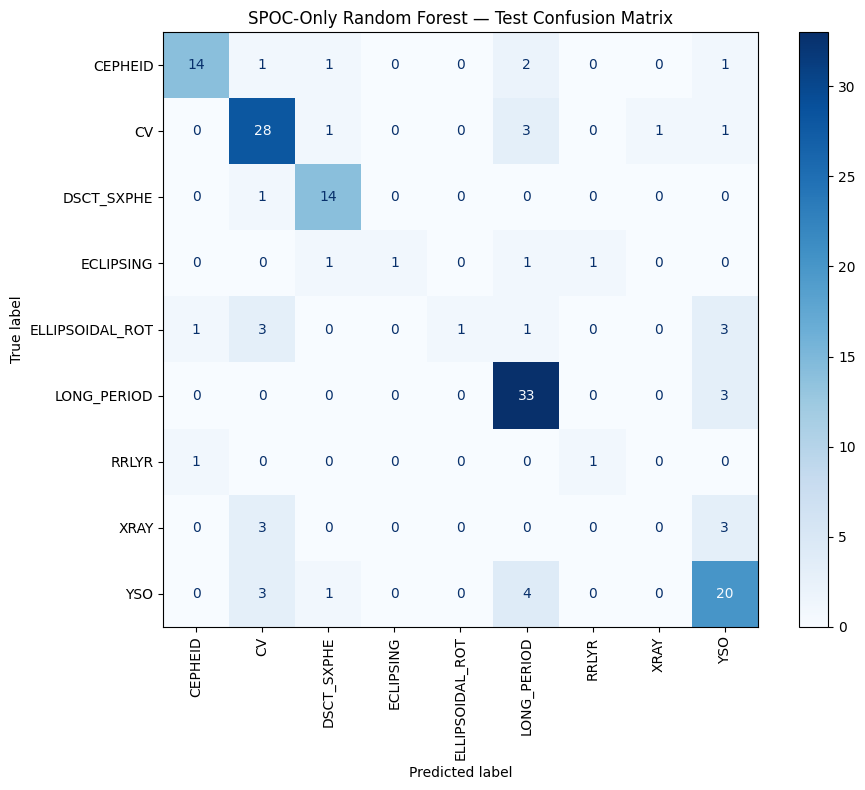

QLP-only Random Forest — test classification report:
                 precision    recall  f1-score   support

        CEPHEID       0.80      0.74      0.77        70
             CV       0.00      0.00      0.00         1
     DSCT_SXPHE       0.74      0.67      0.70        63
      ECLIPSING       0.81      0.52      0.63        33
ELLIPSOIDAL_ROT       0.51      0.58      0.54        45
    LONG_PERIOD       0.65      0.89      0.75       146
          RRLYR       1.00      0.40      0.57         5
           XRAY       0.00      0.00      0.00         3
            YSO       0.73      0.20      0.31        40

       accuracy                           0.68       406
      macro avg       0.58      0.44      0.48       406
   weighted avg       0.69      0.68      0.66       406



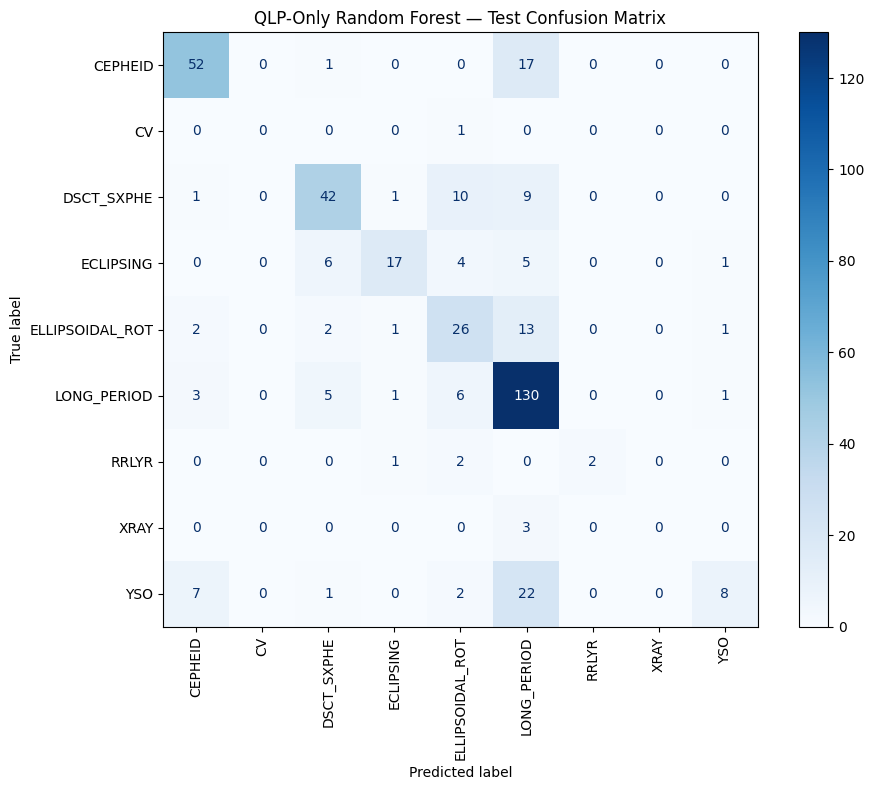

TESSCut-only Random Forest — test classification report:
                 precision    recall  f1-score   support

        CEPHEID       0.29      0.33      0.31       199
             CV       0.05      0.01      0.01       120
     DSCT_SXPHE       0.17      0.15      0.16       212
      ECLIPSING       0.22      0.24      0.23       250
ELLIPSOIDAL_ROT       0.26      0.29      0.27       241
    LONG_PERIOD       0.50      0.29      0.37       106
          RRLYR       0.20      0.28      0.23       269
           XRAY       0.00      0.00      0.00         6
            YSO       0.77      0.72      0.74       223

       accuracy                           0.30      1626
      macro avg       0.27      0.26      0.26      1626
   weighted avg       0.30      0.30      0.30      1626



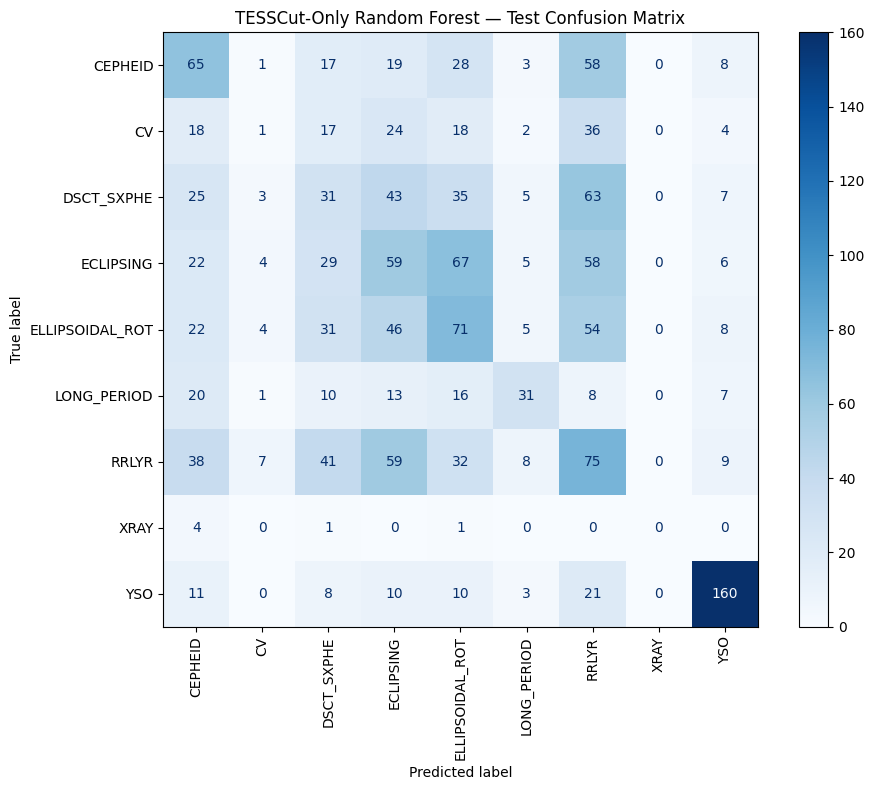

Per-family test metrics by provenance:


,Provenance,Family,Precision,Recall,F1Score,Support
0,SPOC,CEPHEID,0.875,0.737,0.800,19
1,SPOC,CV,0.718,0.824,0.767,34
2,SPOC,DSCT_SXPHE,0.778,0.933,0.848,15
3,SPOC,ECLIPSING,1.000,0.250,0.400,4
4,SPOC,ELLIPSOIDAL_ROT,1.000,0.111,0.200,9
5,SPOC,LONG_PERIOD,0.750,0.917,0.825,36
6,SPOC,RRLYR,0.500,0.500,0.500,2
7,SPOC,XRAY,0.000,0.000,0.000,6
8,SPOC,YSO,0.645,0.714,0.678,28
9,QLP,CEPHEID,0.800,0.743,0.770,70


In [28]:
# ============================================================
# Provenance-specific test confusion matrices
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ProvenanceConfusionInputs = [
    ("SPOC", SpocResults["y_test"], SpocResults["test_pred"]),
    ("QLP", QlpResults["y_test"], QlpResults["test_pred"]),
    ("TESSCut", TessCutResults["y_test"], TessCutResults["test_pred"]),
]

ProvenanceClassificationReportRows = []

for ProvenanceName, yTrueProv, yPredProv in ProvenanceConfusionInputs:
    LabelsProv = sorted(pd.Series(yTrueProv).dropna().unique())

    print(f"{ProvenanceName}-only Random Forest — test classification report:")
    print(classification_report(
        yTrueProv,
        yPredProv,
        labels=LabelsProv,
        zero_division=0,
    ))

    Fig, Ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay.from_predictions(
        yTrueProv,
        yPredProv,
        labels=LabelsProv,
        xticks_rotation=90,
        cmap="Blues",
        values_format="d",
        ax=Ax,
    )
    Ax.set_title(f"{ProvenanceName}-Only Random Forest — Test Confusion Matrix")
    Fig.tight_layout()
    plt.show()
    plt.close(Fig)

    ReportDict = classification_report(
        yTrueProv,
        yPredProv,
        labels=LabelsProv,
        output_dict=True,
        zero_division=0,
    )

    for FamilyName in LabelsProv:
        FamilyMetrics = ReportDict.get(FamilyName, {})
        ProvenanceClassificationReportRows.append({
            "Provenance": ProvenanceName,
            "Family": FamilyName,
            "Precision": FamilyMetrics.get("precision", np.nan),
            "Recall": FamilyMetrics.get("recall", np.nan),
            "F1Score": FamilyMetrics.get("f1-score", np.nan),
            "Support": FamilyMetrics.get("support", np.nan),
        })

ProvenanceClassificationReportDf = pd.DataFrame(ProvenanceClassificationReportRows)

print("Per-family test metrics by provenance:")
display(
    ProvenanceClassificationReportDf.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1Score": "{:.3f}",
        "Support": "{:.0f}",
    })
)

ProvenanceClassificationReportDf.to_csv(
    OutputDir / "provenance_specific_test_classification_metrics.csv",
    index=False,
)


### Feature Category Comparison

Predictors are grouped into periodicity/Lomb–Scargle structure, phase-folded morphology, amplitude, flux distribution, local variability/stochasticity, and observation quality/cadence. Category totals summarize the types of information contributing to each provenance-specific model while reducing sensitivity to individual correlated-feature rankings.


In [29]:

# ============================================================
# Feature category importance comparison
# ============================================================

def categorize_feature(feature_name):
    """Map a feature name into a broad astrophysical/observational category."""
    f = str(feature_name)

    if f.startswith("Phase"):
        return "Phase-folded morphology"

    if f.startswith("Ls") or "Frequency" in f or "Period" in f or "FalseAlarm" in f:
        return "Periodicity / LS structure"

    if "Amplitude" in f:
        return "Amplitude / extrema"

    if (
        "Skewness" in f or
        "Kurtosis" in f or
        "Tail" in f or
        "P05" in f or
        "P10" in f or
        "P50" in f or
        "P90" in f or
        "P95" in f
    ):
        return "Flux distribution / shape"

    if (
        "EtaVonNeumann" in f or
        "SuccessiveDiff" in f or
        "MaxAbsSlope" in f or
        "Slope" in f or
        "Smoothness" in f
    ):
        return "Local variability / stochasticity"

    if (
        "Cadence" in f or
        "TimeSpan" in f or
        "Quality" in f or
        "Snr" in f or
        "SNR" in f or
        "LowSnr" in f
    ):
        return "Observation quality / cadence"

    if "FluxStd" in f or "Std" in f:
        return "Flux scatter / noise"

    return "Other"


CategoryRfImportanceDf = (
    ProvenanceFeatureImportanceDf
    .assign(Category=lambda df: df["Feature"].apply(categorize_feature))
    .groupby(["Provenance", "Category"], as_index=False)["RFImportance"]
    .sum()
    .sort_values(["Provenance", "RFImportance"], ascending=[True, False])
)

CategoryRfImportancePivotDf = (
    CategoryRfImportanceDf
    .pivot(index="Category", columns="Provenance", values="RFImportance")
    .fillna(0)
)

print("RF built-in importance by feature category:")
display(CategoryRfImportancePivotDf)


CategoryPermutationImportanceDf = (
    ProvenancePermutationImportanceDf
    .assign(Category=lambda df: df["Feature"].apply(categorize_feature))
    .groupby(["Provenance", "Category"], as_index=False)["PermutationImportanceMean"]
    .sum()
    .sort_values(["Provenance", "PermutationImportanceMean"], ascending=[True, False])
)

CategoryPermutationImportancePivotDf = (
    CategoryPermutationImportanceDf
    .pivot(index="Category", columns="Provenance", values="PermutationImportanceMean")
    .fillna(0)
)

print("Permutation importance by feature category:")
display(CategoryPermutationImportancePivotDf)


ProvenanceFeatureImportanceDf.to_csv(OutputDir / "provenance_rf_feature_importance.csv", index=False)
ProvenancePermutationImportanceDf.to_csv(OutputDir / "provenance_permutation_importance.csv", index=False)
CategoryRfImportancePivotDf.to_csv(OutputDir / "provenance_rf_feature_category_importance.csv")
CategoryPermutationImportancePivotDf.to_csv(OutputDir / "provenance_permutation_feature_category_importance.csv")

print("Saved provenance feature-importance comparison outputs to:")
print(OutputDir)


RF built-in importance by feature category:


Provenance,QLP,SPOC,TESSCut
Category,,,
Amplitude / extrema,0.045476,0.051095,0.068006
Flux distribution / shape,0.241629,0.183370,0.203282
Flux scatter / noise,0.082382,0.129140,0.095418
Local variability / stochasticity,0.080780,0.119668,0.112260
Observation quality / cadence,0.050051,0.053614,0.070520
Other,0.059497,0.074035,0.058324
Periodicity / LS structure,0.345421,0.326372,0.276184
Phase-folded morphology,0.094764,0.062706,0.116006


Permutation importance by feature category:


Provenance,QLP,SPOC,TESSCut
Category,,,
Amplitude / extrema,0.003809,-0.004384,-0.001987
Flux distribution / shape,0.050412,-0.009478,-0.010411
Flux scatter / noise,0.023011,0.055409,0.000134
Local variability / stochasticity,0.041191,0.016143,-0.000426
Observation quality / cadence,0.006620,0.005291,0.000593
Other,0.018358,0.011864,-0.000695
Periodicity / LS structure,0.040368,-0.036931,-0.055465
Phase-folded morphology,0.011424,0.012940,-0.011253


Saved provenance feature-importance comparison outputs to:
/data/projects/TESS_Research_Publication/results/controlled_analysis


### Provenance-specific feature-importance interpretation

The previous numerical feature-category summaries require replacement after the corrected rerun. Use the new feature-importance tables and category summaries below. Unmatched subsets differ in sample size and family composition, so their differences are not an isolated causal estimate of pipeline effects.


## Matched-star performance and permutation-importance definition

The matched-star experiments compare identical eligible star sets under alternative light-curve provenance while holding labels, the frozen 39 predictors, Random Forest configuration, and star-level train/test assignments fixed. Corrected test accuracy and balanced accuracy are generated below; no previous values are treated as current results.

Permutation importance is computed on held-out test data using balanced accuracy and 50 repeats per feature. Rank correlations quantify model dependence rather than astrophysical causality.


In [30]:

# ============================================================
# Step 19 Diagnostic: OriginalFluxStd and OriginalFluxSnr in SPOC
# ============================================================

DiagnosticFeatures = [
    col for col in ["OriginalFluxStd", "OriginalFluxSnr"]
    if col in globals().get("ProvenanceComparisonDfForTraining", ModelDf).columns
]

if len(DiagnosticFeatures) == 0:
    raise KeyError(
        "Neither OriginalFluxStd nor OriginalFluxSnr exists in the current dataframe."
    )

# Use the final dataframe from Step 18 if available; otherwise fall back to ModelDf.
DiagnosticBaseDf = globals().get("ProvenanceComparisonDfForTraining", ModelDf).copy()

# Identify provenance column robustly.
PossibleProvenanceColumns = ["Provenance", "provenance", "Source", "source"]
DiagnosticProvenanceColumn = None

for CandidateColumn in PossibleProvenanceColumns:
    if CandidateColumn in DiagnosticBaseDf.columns:
        DiagnosticProvenanceColumn = CandidateColumn
        break

if DiagnosticProvenanceColumn is None:
    raise KeyError(
        "Could not find provenance/source column. "
        f"Tried: {PossibleProvenanceColumns}"
    )

SpocDiagnosticDf = DiagnosticBaseDf[
    DiagnosticBaseDf[DiagnosticProvenanceColumn] == "SPOC"
].copy()

print(f"SPOC diagnostic row count: {len(SpocDiagnosticDf)}")
print(f"Using provenance column: {DiagnosticProvenanceColumn}")
print(f"Diagnostic features available: {DiagnosticFeatures}")


# ------------------------------------------------------------
# 1. Distribution of OriginalFluxStd / OriginalFluxSnr by class
# ------------------------------------------------------------

SpocFeatureByClassDf = (
    SpocDiagnosticDf
    .groupby(TargetColumn)[DiagnosticFeatures]
    .agg(["count", "mean", "median", "std"])
)

print("OriginalFluxStd / OriginalFluxSnr by class within SPOC:")
display(SpocFeatureByClassDf)


# ------------------------------------------------------------
# 2. Correct-vs-incorrect diagnostic if SPOC model variables exist
# ------------------------------------------------------------

RequiredSpocObjects = ["SpocRfModel", "XSpocTest", "YSpocTest"]
MissingSpocObjects = [name for name in RequiredSpocObjects if name not in globals()]

if MissingSpocObjects:
    print(
        "Skipping correct-vs-incorrect SPOC prediction diagnostic because "
        f"these objects are missing: {MissingSpocObjects}"
    )
else:
    SpocTestPredictionDf = XSpocTest.copy()
    SpocTestPredictionDf[TargetColumn] = YSpocTest
    SpocTestPredictionDf["Prediction"] = SpocRfModel.predict(XSpocTest)
    SpocTestPredictionDf["Correct"] = (
        SpocTestPredictionDf[TargetColumn] == SpocTestPredictionDf["Prediction"]
    )

    CorrectComparisonFeatures = [
        col for col in DiagnosticFeatures
        if col in SpocTestPredictionDf.columns
    ]

    if CorrectComparisonFeatures:
        SpocCorrectVsIncorrectDf = (
            SpocTestPredictionDf
            .groupby("Correct")[CorrectComparisonFeatures]
            .agg(["count", "mean", "median", "std"])
        )

        print("SPOC test set: OriginalFluxStd / OriginalFluxSnr for correct vs incorrect predictions:")
        display(SpocCorrectVsIncorrectDf)
    else:
        print("Diagnostic features are not present in XSpocTest; skipping correct-vs-incorrect comparison.")


# ------------------------------------------------------------
# 3. Correlation with related amplitude / quality / variability features
# ------------------------------------------------------------

CandidateCorrelationFeatures = [
    "OriginalFluxStd",
    "OriginalFluxSnr",
    "FluxAmplitude",
    "FluxPercentAmplitude95To5",
    "PhaseAmplitude95To5",
    "EtaVonNeumann",
    "MedianAbsSuccessiveDiff",
    "LsMaxPower",
    "LsFalseAlarmProbability",
    "CadenceCount",
    "TimeSpanDays",
]

AvailableCorrelationFeatures = [
    col for col in CandidateCorrelationFeatures
    if col in SpocDiagnosticDf.columns
]

if len(AvailableCorrelationFeatures) >= 2:
    SpocCorrelationDf = SpocDiagnosticDf[AvailableCorrelationFeatures].corr(
        method="spearman"
    )

    print("Spearman correlation among SPOC diagnostic / variability / quality features:")
    display(SpocCorrelationDf)

    ImportantCorrelationRows = [
        col for col in ["OriginalFluxStd", "OriginalFluxSnr"]
        if col in SpocCorrelationDf.index
    ]

    if ImportantCorrelationRows:
        print("Correlations involving OriginalFluxStd / OriginalFluxSnr:")
        display(
            SpocCorrelationDf
            .loc[ImportantCorrelationRows]
            .T
            .sort_values(ImportantCorrelationRows[0], ascending=False)
        )
else:
    print("Not enough related features available for correlation analysis.")


# ------------------------------------------------------------
# 4. Class-level median diagnostic features and sample counts
# ------------------------------------------------------------

SpocClassSupportDf = (
    SpocDiagnosticDf[TargetColumn]
    .value_counts()
    .rename_axis(TargetColumn)
    .reset_index(name="SpocSampleCount")
)

SpocClassFeatureSummaryDf = (
    SpocDiagnosticDf
    .groupby(TargetColumn)[DiagnosticFeatures]
    .median()
    .reset_index()
    .merge(SpocClassSupportDf, on=TargetColumn, how="left")
    .sort_values("SpocSampleCount", ascending=False)
)

print("SPOC class-level median diagnostic features and sample count:")
display(SpocClassFeatureSummaryDf)


SPOC diagnostic row count: 509
Using provenance column: Provenance
Diagnostic features available: ['OriginalFluxStd', 'OriginalFluxSnr']
OriginalFluxStd / OriginalFluxSnr by class within SPOC:


OriginalFluxStd                                    OriginalFluxSnr                                    
                          count        mean    median          std           count        mean      median         std
family                                                                                                                
CEPHEID                      64    0.160111  0.115152     0.137338              64    9.372311    8.684484    5.681071
CV                          114    2.540550  1.042355     3.354267             114    2.714477    0.959382    6.603575
DSCT_SXPHE                   51    9.668307  0.004345    68.892891              51  367.758739  230.141286  451.123337
ECLIPSING                    14    0.058100  0.050688     0.031964              14   26.953484   19.766606   25.090322
ELLIPSOIDAL_ROT              29    0.016846  0.007028     0.024907              29  230.632152  142.290168  245.157974
LONG_PERIOD                 118  134.731638  0.006865  1463.456553             118  269.748308  145.669910  323.780232
RRLYR                         5    0.139091  0.104370     0.061278               5    8.233980    9.581260    3.010721
XRAY                         20    1.384162  0.119527     2.213825              20  212.366208   15.009396  587.537013
YSO                          94    0.154511  0.069745     0.299179              94   44.434194   14.340045   84.238184

SPOC test set: OriginalFluxStd / OriginalFluxSnr for correct vs incorrect predictions:


OriginalFluxStd                               
                  count      mean    median        std
Correct                                               
False                41  0.384689  0.048818   1.167056
True                112  4.962229  0.053755  46.460053

Spearman correlation among SPOC diagnostic / variability / quality features:


,OriginalFluxStd,OriginalFluxSnr,FluxAmplitude,FluxPercentAmplitude95To5,EtaVonNeumann,MedianAbsSuccessiveDiff,LsMaxPower,LsFalseAlarmProbability,CadenceCount,TimeSpanDays
OriginalFluxStd,1.000000,-0.987397,0.018630,0.030878,0.341719,0.370550,-0.263734,0.396378,-0.115231,-0.339954
OriginalFluxSnr,-0.987397,1.000000,-0.029672,-0.033179,-0.352724,-0.379196,0.271988,-0.402583,0.102589,0.327790
FluxAmplitude,0.018630,-0.029672,1.000000,-0.099970,0.577105,0.450479,-0.644727,0.207050,0.452189,0.270614
FluxPercentAmplitude95To5,0.030878,-0.033179,-0.099970,1.000000,0.124801,0.144506,-0.207791,0.172542,-0.007282,-0.007078
EtaVonNeumann,0.341719,-0.352724,0.577105,0.124801,1.000000,0.932520,-0.777819,0.665223,0.069049,-0.160467
MedianAbsSuccessiveDiff,0.370550,-0.379196,0.450479,0.144506,0.932520,1.000000,-0.716935,0.667466,-0.084224,-0.301406
LsMaxPower,-0.263734,0.271988,-0.644727,-0.207791,-0.777819,-0.716935,1.000000,-0.710170,-0.177281,0.007002
LsFalseAlarmProbability,0.396378,-0.402583,0.207050,0.172542,0.665223,0.667466,-0.710170,1.000000,-0.195532,-0.228411
CadenceCount,-0.115231,0.102589,0.452189,-0.007282,0.069049,-0.084224,-0.177281,-0.195532,1.000000,0.678793
TimeSpanDays,-0.339954,0.327790,0.270614,-0.007078,-0.160467,-0.301406,0.007002,-0.228411,0.678793,1.000000


Correlations involving OriginalFluxStd / OriginalFluxSnr:


,OriginalFluxStd,OriginalFluxSnr
OriginalFluxStd,1.000000,-0.987397
LsFalseAlarmProbability,0.396378,-0.402583
MedianAbsSuccessiveDiff,0.370550,-0.379196
EtaVonNeumann,0.341719,-0.352724
FluxPercentAmplitude95To5,0.030878,-0.033179
FluxAmplitude,0.018630,-0.029672
CadenceCount,-0.115231,0.102589
LsMaxPower,-0.263734,0.271988
TimeSpanDays,-0.339954,0.327790
OriginalFluxSnr,-0.987397,1.000000


SPOC class-level median diagnostic features and sample count:


,family,OriginalFluxStd,OriginalFluxSnr,SpocSampleCount
5,LONG_PERIOD,0.006865,145.669910,118
1,CV,1.042355,0.959382,114
8,YSO,0.069745,14.340045,94
0,CEPHEID,0.115152,8.684484,64
2,DSCT_SXPHE,0.004345,230.141286,51
4,ELLIPSOIDAL_ROT,0.007028,142.290168,29
7,XRAY,0.119527,15.009396,20
3,ECLIPSING,0.050688,19.766606,14
6,RRLYR,0.104370,9.581260,5


### SPOC `OriginalFluxStd` / `OriginalFluxSnr` diagnostic

The established 39-feature schema includes `OriginalFluxStd` and excludes `OriginalFluxSnr`. The correlation and family-level medians are recomputed below as diagnostics and do not reselect predictors during this correction.

`OriginalFluxStd` can combine intrinsic variability and observational scatter; it is not an independent measurement-noise estimate. Interpret its current relationship to `OriginalFluxSnr` from the corrected diagnostic outputs.


### Origin of `OriginalFluxStd` and `OriginalFluxSnr`

The upstream feature-generation logic defines `fluxSnr = abs(fluxMedian) / fluxStd`. `OriginalFluxSnr` is therefore mathematically linked to flux scatter and is not independent of `OriginalFluxStd`.

The current analysis removes `OriginalFluxSnr` through the Step 4 correlation filter and retains `OriginalFluxStd`; the provenance-specific model therefore does not double-count the two quantities. `OriginalFluxStd` is interpreted as a combined variability/scatter descriptor that can contain both intrinsic and observational contributions.


### Interpreting `OriginalFluxStd` / `OriginalFluxSnr` redundancy

The frozen predictor schema retains `OriginalFluxStd` and excludes `OriginalFluxSnr`, preserving the established experimental configuration. The current Spearman relationship is reported by the diagnostic cells. Assess provenance differences from the complete corrected performance and importance patterns rather than the precise rank of one predictor.


In [31]:

# ============================================================
# Step 20.1 — Spearman Correlation of Provenance-Specific
#              Random Forest Feature Importance
# ============================================================
#
# Goal:
# Quantify how similarly the SPOC-only, QLP-only, and TESSCut-only
# Random Forest models rank the same features.
#
# Spearman correlation is appropriate because the scientific question is
# primarily about feature-ranking agreement rather than absolute importance
# magnitudes.
#
# This uses the RF built-in feature-importance table created in Step 19:
#     ProvenanceFeatureImportanceDf
#
# No models are retrained here.

RequiredColumns = {"Provenance", "Feature", "RFImportance"}

if "ProvenanceFeatureImportanceDf" not in globals():
    raise NameError(
        "ProvenanceFeatureImportanceDf is not available. "
        "Run the provenance-specific feature-importance analysis in Step 19 first."
    )

MissingColumns = RequiredColumns - set(ProvenanceFeatureImportanceDf.columns)
if MissingColumns:
    raise KeyError(
        "ProvenanceFeatureImportanceDf is missing required columns: "
        f"{sorted(MissingColumns)}"
    )

# Put each provenance-specific importance vector in one column,
# aligned by feature name.
ProvenanceImportanceWideDf = (
    ProvenanceFeatureImportanceDf
    .pivot_table(
        index="Feature",
        columns="Provenance",
        values="RFImportance",
        aggfunc="first"
    )
)

ExpectedProvenances = ["SPOC", "QLP", "TESSCut"]
AvailableProvenances = [
    ProvenanceName
    for ProvenanceName in ExpectedProvenances
    if ProvenanceName in ProvenanceImportanceWideDf.columns
]

if len(AvailableProvenances) < 2:
    raise ValueError(
        "At least two provenance-specific importance vectors are required. "
        f"Available provenance columns: {list(ProvenanceImportanceWideDf.columns)}"
    )

# Restrict comparison to features present for every provenance being compared.
CommonFeatureImportanceDf = (
    ProvenanceImportanceWideDf[AvailableProvenances]
    .dropna(axis=0, how="any")
)

print(
    "Number of common features used for provenance feature-importance "
    f"rank correlation: {len(CommonFeatureImportanceDf)}"
)

# Spearman rank-correlation matrix.
ProvenanceFeatureImportanceSpearmanDf = (
    CommonFeatureImportanceDf
    .corr(method="spearman")
)

print(
    "Spearman rank correlation of RF built-in feature importance "
    "across provenance-specific models:"
)
display(ProvenanceFeatureImportanceSpearmanDf)

# Also provide the three unique pairwise correlations in a compact table.
PairwiseRows = []
for i, ProvenanceA in enumerate(AvailableProvenances):
    for ProvenanceB in AvailableProvenances[i + 1:]:
        PairwiseRows.append({
            "ProvenanceA": ProvenanceA,
            "ProvenanceB": ProvenanceB,
            "SpearmanRho": ProvenanceFeatureImportanceSpearmanDf.loc[
                ProvenanceA, ProvenanceB
            ],
            "CommonFeatureCount": len(CommonFeatureImportanceDf),
        })

ProvenanceFeatureImportanceSpearmanPairsDf = pd.DataFrame(PairwiseRows)

print("Unique provenance-pair Spearman correlations:")
display(ProvenanceFeatureImportanceSpearmanPairsDf)

# Save for paper/report use.
if "OutputDir" in globals():
    ProvenanceFeatureImportanceSpearmanDf.to_csv(
        OutputDir / "provenance_rf_feature_importance_spearman_matrix.csv"
    )
    ProvenanceFeatureImportanceSpearmanPairsDf.to_csv(
        OutputDir / "provenance_rf_feature_importance_spearman_pairs.csv",
        index=False
    )


Number of common features used for provenance feature-importance rank correlation: 39
Spearman rank correlation of RF built-in feature importance across provenance-specific models:


Provenance,SPOC,QLP,TESSCut
Provenance,,,
SPOC,1.000000,0.728119,0.596923
QLP,0.728119,1.000000,0.387952
TESSCut,0.596923,0.387952,1.000000


Unique provenance-pair Spearman correlations:


,ProvenanceA,ProvenanceB,SpearmanRho,CommonFeatureCount
0,SPOC,QLP,0.728119,39
1,SPOC,TESSCut,0.596923,39
2,QLP,TESSCut,0.387952,39


## Step 21 — Matched SPOC vs TESSCut Random Forest comparison

This experiment reads `data/SPOC_TESSCutCache/SPOC_TESSCut_features_QC.parquet` under `Project_Root`. Both sides must have `FeatureStatus == "ok"` and finite `CadenceCount >= 100` before pair formation. Retained pairs have exactly one row per provenance, nonmissing matching family labels, and unique `VSXId` values. Identical star-level train/test assignments, the frozen 39 predictors, imputation, Random Forest configuration, and importance methods are used.

This controls star identity and sample composition within the matched pair. Exclusions are audited; cohort sizes and performance are computed rather than forced to match old values.


### Permutation-importance stability

Permutation importance is evaluated on held-out test data using balanced accuracy and 50 permutations per feature. The repeated permutations reduce Monte Carlo variability in mean importance estimates. The rankings quantify model dependence rather than astrophysical causality.


In [32]:
from sklearn.metrics import confusion_matrix
# ============================================================
# Shared helper for matched official-product vs TESSCut RF comparisons
# ============================================================

from scipy.stats import spearmanr

SPOC_TESSCUT_COMPARISON_OUTPUT_QC = Project_Root / "data" / "SPOC_TESSCutCache" / "SPOC_TESSCut_features_QC.parquet"

QLP_TESSCUT_COMPARISON_OUTPUT_QC = Project_Root / "data" / "QLP_TESSCutCache" / "QLP_TESSCut_features_QC.parquet"


def _resolve_comparison_provenance_column(df):
    for col in ["Provenance", "provenance", "Source", "source"]:
        if col in df.columns:
            return col
    raise KeyError(
        "Could not find a provenance/source column in matched comparison feature table."
    )


def _prepare_matched_pair_dataframe(
    feature_file,
    official_provenance,
    target_column,
):
    """Validate and return exactly one official and one TESSCut row per matched VSXId."""
    df = trv.read_corrected_features(feature_file).copy()

    if "VSXId" not in df.columns:
        raise KeyError("Matched comparison feature table is missing VSXId.")
    if target_column not in df.columns:
        raise KeyError(f"Matched comparison feature table is missing {target_column}.")

    provenance_col = _resolve_comparison_provenance_column(df)
    df["_ProvenanceNormalized"] = df[provenance_col].map(normalize_provenance_label)

    wanted = {official_provenance, "TESSCut"}
    df = df[df["_ProvenanceNormalized"].isin(wanted)].copy()
    InputRequestedRows = len(df)
    RequiredEligibilityColumns = {"FeatureStatus", "CadenceCount"}
    MissingEligibilityColumns = sorted(RequiredEligibilityColumns - set(df.columns))
    if MissingEligibilityColumns:
        raise KeyError(f"Matched table is missing eligibility metadata: {MissingEligibilityColumns}")
    CadenceCounts = pd.to_numeric(df["CadenceCount"], errors="coerce")
    EligibleMask = (
        df["FeatureStatus"].eq("ok")
        & np.isfinite(CadenceCounts)
        & CadenceCounts.ge(100)
        & df["VSXId"].notna()
        & df["VSXId"].astype(str).str.strip().ne("")
        & df[target_column].notna()
        & df[target_column].astype(str).str.strip().ne("")
    )
    RowExclusions = df.loc[~EligibleMask].copy()
    RowExclusions["ExclusionRule"] = "status not ok, cadence not finite/<100, or missing ID/family"
    RowExclusions.to_csv(
        OutputDir / f"matched_{official_provenance.lower()}_tesscut_row_exclusions.csv", index=False
    )
    df = trv.eligible_rows(df.loc[EligibleMask]).copy()
    df["VSXId"] = df["VSXId"].astype(str)

    pair_counts = (
        df.groupby(["VSXId", "_ProvenanceNormalized"])
        .size()
        .unstack(fill_value=0)
    )

    for required_col in [official_provenance, "TESSCut"]:
        if required_col not in pair_counts.columns:
            pair_counts[required_col] = 0

    valid_ids = pair_counts.index[
        (pair_counts[official_provenance] == 1)
        & (pair_counts["TESSCut"] == 1)
    ]

    matched = df[df["VSXId"].isin(valid_ids)].copy()

    official_df = (
        matched[matched["_ProvenanceNormalized"] == official_provenance]
        .set_index("VSXId", drop=False)
        .sort_index()
    )
    tesscut_df = (
        matched[matched["_ProvenanceNormalized"] == "TESSCut"]
        .set_index("VSXId", drop=False)
        .sort_index()
    )

    common_ids = official_df.index.intersection(tesscut_df.index)
    official_df = official_df.loc[common_ids].copy()
    tesscut_df = tesscut_df.loc[common_ids].copy()

    if official_df.empty:
        raise ValueError(f"No eligible one-to-one {official_provenance}/TESSCut pairs remain.")
    if not official_df.index.is_unique or not tesscut_df.index.is_unique:
        raise ValueError("Matched VSXIds must be unique on each side.")
    trv.assert_eligible(official_df)
    trv.assert_eligible(tesscut_df)
    pd.DataFrame([{
        "OfficialProvenance": official_provenance,
        "InputRequestedRows": InputRequestedRows,
        "ExcludedIneligibleRows": len(RowExclusions),
        "EligibleRowsBeforePairing": len(df),
        "EligibleIdsBeforePairing": int(df["VSXId"].nunique()),
        "ExcludedUnpairedOrDuplicateIds": int(len(pair_counts) - len(valid_ids)),
        "RetainedMatchedStars": len(official_df),
        "MinimumCadences": 100,
        "RequiredFeatureStatus": "ok",
    }]).to_csv(OutputDir / f"matched_{official_provenance.lower()}_tesscut_eligibility_audit.csv", index=False)

    family_mismatch = (
        official_df[target_column].astype(str)
        != tesscut_df[target_column].astype(str)
    )
    if family_mismatch.any():
        bad_ids = official_df.index[family_mismatch].tolist()
        raise ValueError(
            f"{official_provenance} vs TESSCut has family-label mismatches for "
            f"{len(bad_ids)} matched VSXIds; examples: {bad_ids[:10]}"
        )

    return official_df, tesscut_df, provenance_col


def _train_matched_rf(
    source_df,
    feature_columns,
    target_column,
    train_ids,
    test_ids,
    provenance_name,
    random_state=42,
):
    """Train RF using a preassigned VSXId split shared across provenance products."""
    train_df = source_df.loc[train_ids].copy()
    test_df = source_df.loc[test_ids].copy()

    x_train = train_df[feature_columns]
    y_train = train_df[target_column]
    x_test = test_df[feature_columns]
    y_test = test_df[target_column]

    model = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=500,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=random_state,
            )),
        ]
    )

    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred = model.predict(x_test)

    performance = pd.DataFrame([
        {
            "Provenance": provenance_name,
            "split": "train",
            "accuracy": accuracy_score(y_train, train_pred),
            "balanced_accuracy": balanced_accuracy_score(y_train, train_pred),
            "sample_count": len(y_train),
        },
        {
            "Provenance": provenance_name,
            "split": "test",
            "accuracy": accuracy_score(y_test, test_pred),
            "balanced_accuracy": balanced_accuracy_score(y_test, test_pred),
            "sample_count": len(y_test),
        },
    ])

    return {
        "model": model,
        "x_train": x_train,
        "x_test": x_test,
        "y_train": y_train,
        "y_test": y_test,
        "test_pred": test_pred,
        "performance": performance,
    }


def run_matched_provenance_comparison(
    feature_file,
    official_provenance,
    feature_columns,
    target_column,
    output_prefix,
    random_state=42,
    test_size=0.30,
):
    """
    Run a controlled official-product vs TESSCut comparison using identical VSXIds
    in train and test for both provenance-specific Random Forest models.
    """
    official_df, tesscut_df, provenance_col = _prepare_matched_pair_dataframe(
        feature_file=feature_file,
        official_provenance=official_provenance,
        target_column=target_column,
    )

    common_ids = official_df.index.to_numpy()
    pair_labels = official_df.loc[common_ids, target_column]

    class_counts = pair_labels.value_counts()
    keep_classes = class_counts[class_counts >= 2].index
    dropped_classes = class_counts[class_counts < 2]

    if len(dropped_classes) > 0:
        print(
            f"{official_provenance} vs TESSCut: dropping classes with fewer than "
            "2 matched VSXIds before stratified split:"
        )
        display(dropped_classes)

    keep_ids = official_df.index[
        official_df[target_column].isin(keep_classes)
    ].to_numpy()

    official_df = official_df.loc[keep_ids].copy()
    tesscut_df = tesscut_df.loc[keep_ids].copy()

    id_labels = official_df.loc[keep_ids, target_column]

    train_ids, test_ids = train_test_split(
        keep_ids,
        test_size=test_size,
        stratify=id_labels,
        random_state=random_state,
    )

    # Preserve deterministic ordering for easy cross-checking.
    train_ids = sorted(train_ids)
    test_ids = sorted(test_ids)

    if set(train_ids).intersection(test_ids):
        raise ValueError("Matched train/test star identities overlap.")
    pd.DataFrame({
        "VSXId": train_ids + test_ids,
        "Split": ["train"] * len(train_ids) + ["test"] * len(test_ids),
        "Family": official_df.loc[train_ids + test_ids, target_column].tolist(),
    }).to_csv(OutputDir / f"{output_prefix}_membership.csv", index=False)

    # Use the common frozen FeatureColumns set.
    missing_official = sorted(set(feature_columns) - set(official_df.columns))
    missing_tesscut = sorted(set(feature_columns) - set(tesscut_df.columns))
    if missing_official or missing_tesscut:
        raise ValueError(
            "Matched comparison feature schema is incompatible with current "
            f"FeatureColumns. Missing official={missing_official}; "
            f"missing TESSCut={missing_tesscut}"
        )

    official_results = _train_matched_rf(
        source_df=official_df,
        feature_columns=feature_columns,
        target_column=target_column,
        train_ids=train_ids,
        test_ids=test_ids,
        provenance_name=official_provenance,
        random_state=random_state,
    )

    tesscut_results = _train_matched_rf(
        source_df=tesscut_df,
        feature_columns=feature_columns,
        target_column=target_column,
        train_ids=train_ids,
        test_ids=test_ids,
        provenance_name="TESSCut",
        random_state=random_state,
    )

    # Controlled row-normalized test confusion matrices.
    # Both matrices in a provenance pair use identical test stars and class order.
    matched_labels = sorted(
        pd.Series(official_results["y_test"]).dropna().unique()
    )
    official_confusion_matrix = confusion_matrix(
        official_results["y_test"],
        official_results["test_pred"],
        labels=matched_labels,
        normalize="true",
    )
    tesscut_confusion_matrix = confusion_matrix(
        tesscut_results["y_test"],
        tesscut_results["test_pred"],
        labels=matched_labels,
        normalize="true",
    )

    performance_df = pd.concat(
        [official_results["performance"], tesscut_results["performance"]],
        ignore_index=True,
    )

    official_rf_imp = build_rf_feature_importance_df(
        official_results["model"],
        feature_columns,
        official_provenance,
    )
    tesscut_rf_imp = build_rf_feature_importance_df(
        tesscut_results["model"],
        feature_columns,
        "TESSCut",
    )

    official_perm_imp = build_permutation_importance_df(
        official_results["model"],
        official_results["x_test"],
        official_results["y_test"],
        feature_columns,
        official_provenance,
        scoring="balanced_accuracy",
        n_repeats=50,
        random_state=random_state,
    )
    tesscut_perm_imp = build_permutation_importance_df(
        tesscut_results["model"],
        tesscut_results["x_test"],
        tesscut_results["y_test"],
        feature_columns,
        "TESSCut",
        scoring="balanced_accuracy",
        n_repeats=50,
        random_state=random_state,
    )

    rf_rank = (
        official_rf_imp[["Feature", "RFImportance"]]
        .rename(columns={"RFImportance": f"{official_provenance}RFImportance"})
        .merge(
            tesscut_rf_imp[["Feature", "RFImportance"]]
            .rename(columns={"RFImportance": "TESSCutRFImportance"}),
            on="Feature",
            how="inner",
        )
    )
    rf_rank[f"{official_provenance}Rank"] = (
        rf_rank[f"{official_provenance}RFImportance"]
        .rank(method="min", ascending=False)
    )
    rf_rank["TESSCutRank"] = (
        rf_rank["TESSCutRFImportance"]
        .rank(method="min", ascending=False)
    )
    rf_rank["AbsRankChange"] = (
        rf_rank[f"{official_provenance}Rank"] - rf_rank["TESSCutRank"]
    ).abs()
    rf_rank = rf_rank.sort_values(
        ["AbsRankChange", f"{official_provenance}RFImportance"],
        ascending=[False, False],
    ).reset_index(drop=True)

    perm_rank = (
        official_perm_imp[["Feature", "PermutationImportanceMean"]]
        .rename(columns={
            "PermutationImportanceMean":
            f"{official_provenance}PermutationImportance"
        })
        .merge(
            tesscut_perm_imp[["Feature", "PermutationImportanceMean"]]
            .rename(columns={
                "PermutationImportanceMean": "TESSCutPermutationImportance"
            }),
            on="Feature",
            how="inner",
        )
    )
    perm_rank[f"{official_provenance}Rank"] = (
        perm_rank[f"{official_provenance}PermutationImportance"]
        .rank(method="min", ascending=False)
    )
    perm_rank["TESSCutRank"] = (
        perm_rank["TESSCutPermutationImportance"]
        .rank(method="min", ascending=False)
    )
    perm_rank["AbsRankChange"] = (
        perm_rank[f"{official_provenance}Rank"] - perm_rank["TESSCutRank"]
    ).abs()
    perm_rank = perm_rank.sort_values(
        ["AbsRankChange", f"{official_provenance}PermutationImportance"],
        ascending=[False, False],
    ).reset_index(drop=True)

    rf_spearman = spearmanr(
        rf_rank[f"{official_provenance}RFImportance"],
        rf_rank["TESSCutRFImportance"],
        nan_policy="omit",
    )
    perm_spearman = spearmanr(
        perm_rank[f"{official_provenance}PermutationImportance"],
        perm_rank["TESSCutPermutationImportance"],
        nan_policy="omit",
    )

    # Per-family held-out metrics.
    report_rows = []
    for provenance_name, results in [
        (official_provenance, official_results),
        ("TESSCut", tesscut_results),
    ]:
        report = classification_report(
            results["y_test"],
            results["test_pred"],
            output_dict=True,
            zero_division=0,
        )
        for family_name in sorted(results["y_test"].unique()):
            metrics = report.get(family_name, {})
            report_rows.append({
                "Provenance": provenance_name,
                "Family": family_name,
                "Precision": metrics.get("precision", np.nan),
                "Recall": metrics.get("recall", np.nan),
                "F1Score": metrics.get("f1-score", np.nan),
                "Support": metrics.get("support", np.nan),
            })
    family_metrics_df = pd.DataFrame(report_rows)

    # Save outputs.
    performance_df.to_csv(
        OutputDir / f"{output_prefix}_performance.csv",
        index=False,
    )
    rf_rank.to_csv(
        OutputDir / f"{output_prefix}_rf_importance_rank_comparison.csv",
        index=False,
    )
    perm_rank.to_csv(
        OutputDir / f"{output_prefix}_permutation_importance_rank_comparison.csv",
        index=False,
    )
    family_metrics_df.to_csv(
        OutputDir / f"{output_prefix}_family_test_metrics.csv",
        index=False,
    )
    pd.DataFrame(
        official_confusion_matrix,
        index=matched_labels,
        columns=matched_labels,
    ).to_csv(
        OutputDir / f"{output_prefix}_{official_provenance.lower()}_confusion_matrix_normalized.csv"
    )
    pd.DataFrame(
        tesscut_confusion_matrix,
        index=matched_labels,
        columns=matched_labels,
    ).to_csv(
        OutputDir / f"{output_prefix}_tesscut_confusion_matrix_normalized.csv"
    )

    # A standalone figure export must prove that both matrices came from this
    # corrected feature file and controlled configuration, not an earlier run.
    MatrixPaths = [
        OutputDir / f"{output_prefix}_{official_provenance.lower()}_confusion_matrix_normalized.csv",
        OutputDir / f"{output_prefix}_tesscut_confusion_matrix_normalized.csv",
    ]
    trv.write_run_manifest(
        OutputDir / f"{output_prefix}_confusion_source.science_fix_run.json",
        inputs=[feature_file],
        config={
            "analysis": "matched_confusion",
            "official_provenance": official_provenance,
            "features": list(feature_columns),
            "random_state": int(random_state),
            "test_size": float(test_size),
            "eligibility": {"FeatureStatus": "ok", "minimum_cadences": 100},
        },
        outputs=MatrixPaths,
    )

    print("=" * 80)
    print(f"MATCHED {official_provenance} vs TESSCut COMPARISON")
    print("=" * 80)
    print(f"Input feature file: {feature_file}")
    print(f"Matched VSXIds used: {len(keep_ids):,}")
    print(f"Shared training VSXIds: {len(train_ids):,}")
    print(f"Shared test VSXIds: {len(test_ids):,}")
    print()

    print("Model performance:")
    display(performance_df)

    print("Top 15 RF built-in importances:")
    display(
        pd.concat([official_rf_imp.head(15), tesscut_rf_imp.head(15)])
        .reset_index(drop=True)
    )

    print("Top 15 permutation importances:")
    display(
        pd.concat([official_perm_imp.head(15), tesscut_perm_imp.head(15)])
        .reset_index(drop=True)
    )

    print(
        f"RF built-in importance Spearman correlation "
        f"({official_provenance} vs TESSCut): "
        f"rho={rf_spearman.statistic:.3f}, p={rf_spearman.pvalue:.3g}"
    )
    print(
        f"Permutation importance Spearman correlation "
        f"({official_provenance} vs TESSCut): "
        f"rho={perm_spearman.statistic:.3f}, p={perm_spearman.pvalue:.3g}"
    )

    print("Largest RF built-in importance rank changes:")
    display(rf_rank.head(15))

    print("Largest permutation-importance rank changes:")
    display(perm_rank.head(15))

    print("Per-family held-out metrics:")
    display(family_metrics_df)

    return {
        "official_df": official_df,
        "tesscut_df": tesscut_df,
        "train_ids": train_ids,
        "test_ids": test_ids,
        "official_results": official_results,
        "tesscut_results": tesscut_results,
        "performance_df": performance_df,
        "official_rf_importance": official_rf_imp,
        "tesscut_rf_importance": tesscut_rf_imp,
        "official_permutation_importance": official_perm_imp,
        "tesscut_permutation_importance": tesscut_perm_imp,
        "rf_rank_comparison": rf_rank,
        "permutation_rank_comparison": perm_rank,
        "rf_spearman": rf_spearman,
        "permutation_spearman": perm_spearman,
        "family_metrics_df": family_metrics_df,
        "confusion_labels": matched_labels,
        "official_confusion_matrix": official_confusion_matrix,
        "tesscut_confusion_matrix": tesscut_confusion_matrix,
    }


SpocTessCutMatchedResults = run_matched_provenance_comparison(
    feature_file=SPOC_TESSCUT_COMPARISON_OUTPUT_QC,
    official_provenance="SPOC",
    feature_columns=FeatureColumns,
    target_column=TargetColumn,
    output_prefix="matched_spoc_tesscut",
    random_state=RandomState,
)


Permutation importance repeats: 50
Permutation importance repeats: 50
MATCHED SPOC vs TESSCut COMPARISON
Input feature file: /data/projects/TESS_Research_Publication/data/SPOC_TESSCutCache/SPOC_TESSCut_features_QC.parquet
Matched VSXIds used: 506
Shared training VSXIds: 354
Shared test VSXIds: 152

Model performance:


,Provenance,split,accuracy,balanced_accuracy,sample_count
0,SPOC,train,1.000000,1.000000,354
1,SPOC,test,0.763158,0.571473,152
2,TESSCut,train,1.000000,1.000000,354
3,TESSCut,test,0.631579,0.386845,152


Top 15 RF built-in importances:


,Provenance,Feature,RFImportance
0,SPOC,OriginalFluxStd,0.091539
1,SPOC,LsBestPeriod,0.062872
2,SPOC,LsPeriod2,0.060572
3,SPOC,LsPeriod3,0.058347
4,SPOC,FluxMad,0.043070
5,SPOC,MedianAbsSuccessiveDiff,0.042511
6,SPOC,FluxIqr,0.039982
7,SPOC,MaxAbsSlope,0.038162
8,SPOC,EtaVonNeumann,0.036268
9,SPOC,FluxAmplitude,0.035217


Top 15 permutation importances:


,Provenance,Feature,PermutationImportanceMean,PermutationImportanceStd
0,SPOC,OriginalFluxStd,0.106615,0.020398
1,SPOC,FractionBeyond1Std,0.036617,0.011449
2,SPOC,LsBestPeriod,0.034511,0.016152
3,SPOC,FluxSkewness,0.033760,0.008761
4,SPOC,FluxIqr,0.032180,0.010960
5,SPOC,MaxAbsSlope,0.027647,0.021212
6,SPOC,FluxPercentAmplitude95To5,0.025365,0.014591
7,SPOC,FluxMad,0.025176,0.014805
8,SPOC,FluxP90,0.025078,0.011138
9,SPOC,CadenceCount,0.023033,0.010069


... (2 outputs left out)

Largest permutation-importance rank changes:


,Feature,SPOCPermutationImportance,TESSCutPermutationImportance,SPOCRank,TESSCutRank,AbsRankChange
0,OriginalFluxMedian,0.000000,0.008261,32.0,4.0,28.0
1,FluxIqr,0.032180,-0.006337,5.0,32.0,27.0
2,TailAsymmetry,-0.004009,0.001708,39.0,12.0,27.0
3,FractionBeyond1Std,0.036617,-0.002940,2.0,28.0,26.0
4,FluxP90,0.025078,-0.010462,9.0,35.0,26.0
5,QualityScore,-0.000063,0.003640,35.0,9.0,26.0
6,LsBestPeriod,0.034511,-0.002657,3.0,27.0,24.0
7,FluxMad,0.025176,-0.004674,8.0,30.0,22.0
8,FluxKurtosis,0.000908,0.002698,31.0,10.0,21.0
9,OriginalFluxStd,0.106615,-0.000550,1.0,21.0,20.0


Per-family held-out metrics:


,Provenance,Family,Precision,Recall,F1Score,Support
0,SPOC,CEPHEID,0.782609,0.947368,0.857143,19.0
1,SPOC,CV,0.815789,0.911765,0.861111,34.0
2,SPOC,DSCT_SXPHE,0.812500,0.866667,0.838710,15.0
3,SPOC,ECLIPSING,0.666667,0.500000,0.571429,4.0
4,SPOC,ELLIPSOIDAL_ROT,0.666667,0.222222,0.333333,9.0
5,SPOC,LONG_PERIOD,0.837838,0.885714,0.861111,35.0
6,SPOC,RRLYR,0.000000,0.000000,0.000000,2.0
7,SPOC,XRAY,0.250000,0.166667,0.200000,6.0
8,SPOC,YSO,0.642857,0.642857,0.642857,28.0
9,TESSCut,CEPHEID,0.842105,0.842105,0.842105,19.0


## Step 22 — Matched QLP vs TESSCut Random Forest Comparison

This experiment uses `${Project_Root}/data_pipeline/QLP_TESSCutCache/QLP_TESSCut_features_QC.parquet` and applies the same matched-`VSXId` design, identical train/test assignments, predictor set, imputation, Random Forest configuration, metrics, and importance methods as the SPOC–TESSCut comparison.


In [33]:
QlpTessCutMatchedResults = run_matched_provenance_comparison(
    feature_file=QLP_TESSCUT_COMPARISON_OUTPUT_QC,
    official_provenance="QLP",
    feature_columns=FeatureColumns,
    target_column=TargetColumn,
    output_prefix="matched_qlp_tesscut",
    random_state=RandomState,
)


Permutation importance repeats: 50
Permutation importance repeats: 50
MATCHED QLP vs TESSCut COMPARISON
Input feature file: /data/projects/TESS_Research_Publication/data/QLP_TESSCutCache/QLP_TESSCut_features_QC.parquet
Matched VSXIds used: 1,353
Shared training VSXIds: 947
Shared test VSXIds: 406

Model performance:


,Provenance,split,accuracy,balanced_accuracy,sample_count
0,QLP,train,1.000000,1.000000,947
1,QLP,test,0.694581,0.426503,406
2,TESSCut,train,1.000000,1.000000,947
3,TESSCut,test,0.534483,0.279057,406


Top 15 RF built-in importances:


,Provenance,Feature,RFImportance
0,QLP,LsPeriod2,0.062600
1,QLP,LsPeriod3,0.060033
2,QLP,LsBestPeriod,0.059390
3,QLP,TailRatio,0.055051
4,QLP,FluxP90,0.044140
5,QLP,LsMaxPower,0.039640
6,QLP,TailAsymmetry,0.039432
7,QLP,MedianAbsSuccessiveDiff,0.038723
8,QLP,FluxIqr,0.037477
9,QLP,OriginalFluxStd,0.036953


Top 15 permutation importances:


,Provenance,Feature,PermutationImportanceMean,PermutationImportanceStd
0,QLP,LsMaxPower,0.017754,0.006188
1,QLP,MedianAbsSuccessiveDiff,0.016136,0.004911
2,QLP,LsBestPeriod,0.011555,0.006091
3,QLP,LsPeriod2,0.011334,0.006048
4,QLP,OriginalFluxStd,0.010901,0.005040
5,QLP,FluxIqr,0.008875,0.003360
6,QLP,TailRatio,0.008780,0.004639
7,QLP,PhaseCurveStd,0.008355,0.004481
8,QLP,LsPeriod3,0.007757,0.007027
9,QLP,TimeSpanDays,0.007602,0.003605


... (2 outputs left out)

Largest permutation-importance rank changes:


,Feature,QLPPermutationImportance,TESSCutPermutationImportance,QLPRank,TESSCutRank,AbsRankChange
0,LsMaxPower,0.017754,-0.001546,1.0,35.0,34.0
1,MaxAbsSlope,-0.002080,0.009024,38.0,8.0,30.0
2,PhaseCurveStd,0.008355,-0.001999,8.0,37.0,29.0
3,FluxP95,-0.000121,0.009091,35.0,6.0,29.0
4,QualityScore,-0.000095,0.007294,34.0,11.0,23.0
5,LsPowerRatio21,0.004882,-0.005300,16.0,38.0,22.0
6,LsPowerRatio31,-0.001150,0.003501,37.0,18.0,19.0
7,TimeSpanDays,0.007602,0.000946,10.0,28.0,18.0
8,PhasePeakPhase,0.001309,-0.005505,21.0,39.0,18.0
9,FractionBeyond2Std,0.000408,0.009075,25.0,7.0,18.0


Per-family held-out metrics:


,Provenance,Family,Precision,Recall,F1Score,Support
0,QLP,CEPHEID,0.820896,0.785714,0.802920,70.0
1,QLP,CV,0.000000,0.000000,0.000000,1.0
2,QLP,DSCT_SXPHE,0.741379,0.682540,0.710744,63.0
3,QLP,ECLIPSING,0.650000,0.393939,0.490566,33.0
4,QLP,ELLIPSOIDAL_ROT,0.549020,0.622222,0.583333,45.0
5,QLP,LONG_PERIOD,0.670051,0.904110,0.769679,146.0
6,QLP,RRLYR,1.000000,0.200000,0.333333,5.0
7,QLP,XRAY,0.000000,0.000000,0.000000,3.0
8,QLP,YSO,0.833333,0.250000,0.384615,40.0
9,TESSCut,CEPHEID,0.612245,0.428571,0.504202,70.0


### Controlled Matched-Test Confusion Matrices - High-Resolution Manuscript Export

The following cell integrates the supplied high-resolution exporter for manuscript Figures 3 and 5 and replaces the previous plotting-only cell. It reads the four normalized confusion-matrix CSVs saved by the corrected matched comparisons and verifies their source/run manifests against the corrected feature files. It preserves values and class order, applies a common 0-1 colour scale, and exports both panels of each figure at 600 dpi plus vector PDF.

This cell can run by itself in a fresh kernel when the corrected saved CSVs and matching source manifests already exist: no model fitting is performed. It defaults to `Project_Root/results/controlled_analysis/`, reusing `OutputDir` if the configuration cell has run. Outputs go to `results/publication_figures/`, with `Figures_3_5_PNG.zip`, `Figures_3_5_PDF.zip`, and `03_publication_figure_manifest.json`. Upload all four same-named PNGs to Overleaf, including both QLP panels. To use the PDFs instead, change the four corresponding LaTeX image extensions to `.pdf`.


Publication-figure output: /data/projects/TESS_Research_Publication/results/publication_figures
Saved matched_spoc_tesscut_spoc_confusion_matrix_normalized.png: 2100 x 2190 pixels, 600 dpi at 3.5 inches wide.
Saved vector PDF: matched_spoc_tesscut_spoc_confusion_matrix_normalized.pdf


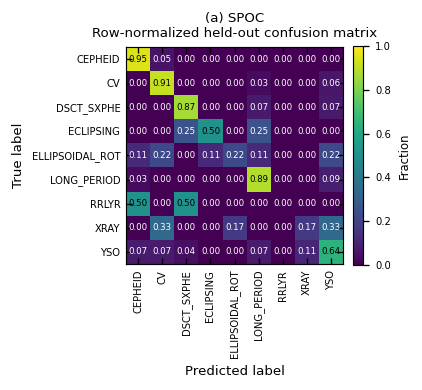

SPOC: loaded 9 x 9 values from matched_spoc_tesscut_spoc_confusion_matrix_normalized.csv
Saved matched_spoc_tesscut_tesscut_confusion_matrix_normalized.png: 2100 x 2190 pixels, 600 dpi at 3.5 inches wide.
Saved vector PDF: matched_spoc_tesscut_tesscut_confusion_matrix_normalized.pdf


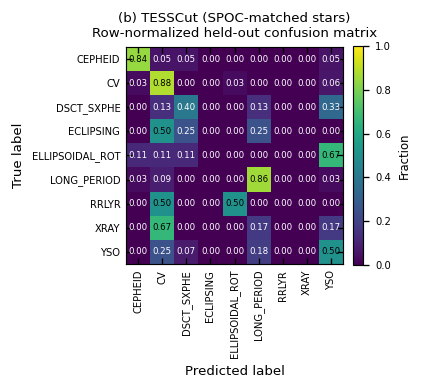

TESSCut: loaded 9 x 9 values from matched_spoc_tesscut_tesscut_confusion_matrix_normalized.csv
Saved matched_qlp_tesscut_qlp_confusion_matrix_normalized.png: 2100 x 2190 pixels, 600 dpi at 3.5 inches wide.
Saved vector PDF: matched_qlp_tesscut_qlp_confusion_matrix_normalized.pdf


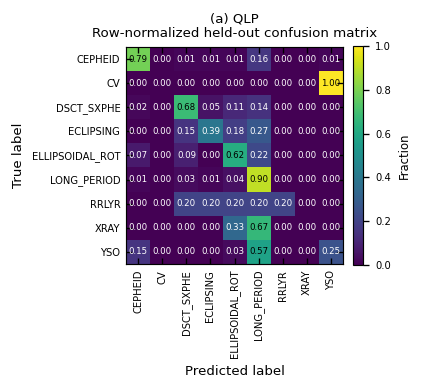

QLP: loaded 9 x 9 values from matched_qlp_tesscut_qlp_confusion_matrix_normalized.csv
Saved matched_qlp_tesscut_tesscut_confusion_matrix_normalized.png: 2100 x 2190 pixels, 600 dpi at 3.5 inches wide.
Saved vector PDF: matched_qlp_tesscut_tesscut_confusion_matrix_normalized.pdf


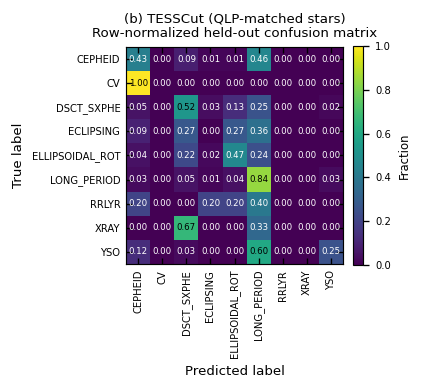

TESSCut: loaded 9 x 9 values from matched_qlp_tesscut_tesscut_confusion_matrix_normalized.csv


,Figure,PNG,Pixels,DPI at export width,Panel labels,Formatting checks
0,3,matched_spoc_tesscut_spoc_confusion_matrix_nor...,2100 x 2190,600,(a),PASS
1,3,matched_spoc_tesscut_tesscut_confusion_matrix_...,2100 x 2190,600,(b),PASS
2,5,matched_qlp_tesscut_qlp_confusion_matrix_norma...,2100 x 2190,600,(a),PASS
3,5,matched_qlp_tesscut_tesscut_confusion_matrix_n...,2100 x 2190,600,(b),PASS


PASS: all four PNGs and four PDFs were created and checked in this kernel session.
PNG replacement package: /data/projects/TESS_Research_Publication/results/publication_figures/Figures_3_5_PNG.zip
Vector PDF package: /data/projects/TESS_Research_Publication/results/publication_figures/Figures_3_5_PDF.zip
Export record: /data/projects/TESS_Research_Publication/results/publication_figures/03_publication_figure_manifest.json
Next: extract the PNG package, replace all four same-named images in Overleaf, and recompile.


In [34]:
def export_matched_confusion_publication_figures(project_root=None, analysis_output_dir=None, output_dir=None, png_dpi=600):
    """Export manuscript Figures 3 and 5 from saved full-precision confusion CSVs without fitting models.

    Helpers and configuration are local to this function; analytical notebook globals are preserved.
    PNGs use the requested DPI (600 by default); PDFs retain vector plot elements.
    """
    import os
    import tess_research_validation as trv
    from pathlib import Path
    import hashlib
    import importlib.metadata
    import json
    import platform
    from zipfile import ZipFile, ZIP_DEFLATED
    from PIL import Image
    from datetime import datetime, timezone
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from IPython.display import display

    PROJECT_DIR = Path(project_root if project_root is not None else
                       os.environ.get('Project_Root', '/data/projects/TESS_Research_Publication')).expanduser()
    OUTPUT_DIR = (Path(output_dir).expanduser() if output_dir is not None else
                  PROJECT_DIR / 'results' / 'publication_figures')
    PNG_DPI = int(png_dpi)
    FULL_WIDTH_INCHES = 7.2
    PANEL_WIDTH_INCHES = 3.5
    SOURCE_RECORDS = {}
    EXPORT_RECORDS = {}
    CHECK_RECORDS = {}
    if PNG_DPI < 400:
        raise ValueError('Use at least 400 dpi; the default is 600 dpi.')

    ANALYSIS_OUTPUT_DIR = (Path(analysis_output_dir).expanduser() if analysis_output_dir is not None else
                           PROJECT_DIR / 'results' / 'controlled_analysis')
    MATRIX_FILES = {
        official: [
            ANALYSIS_OUTPUT_DIR / f'matched_{official.lower()}_tesscut_{official.lower()}_confusion_matrix_normalized.csv',
            ANALYSIS_OUTPUT_DIR / f'matched_{official.lower()}_tesscut_tesscut_confusion_matrix_normalized.csv',
        ]
        for official in ['SPOC', 'QLP']
    }
    REQUIRED_INPUTS = [*MATRIX_FILES['SPOC'], *MATRIX_FILES['QLP']]

    STYLE = {'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7, 'axes.linewidth': 0.7, 'axes.grid': False, 'text.usetex': False, 'pdf.fonttype': 42, 'figure.dpi': 120, 'savefig.facecolor': 'white', 'savefig.bbox': None}
    EXPECTED_EXPORTS = {'matched_spoc_tesscut_spoc_confusion_matrix_normalized': (3, ['(a)']), 'matched_spoc_tesscut_tesscut_confusion_matrix_normalized': (3, ['(b)']), 'matched_qlp_tesscut_qlp_confusion_matrix_normalized': (5, ['(a)']), 'matched_qlp_tesscut_tesscut_confusion_matrix_normalized': (5, ['(b)'])}

    def record_source(path):
        path = Path(path).expanduser()
        if not path.is_file():
            raise FileNotFoundError(
                f'Saved input not found: {path}\n'
                'Check the configuration paths and locate the file from the original run. '
                'This notebook does not recreate missing analysis results.'
            )
        digest = hashlib.sha256()
        with path.open('rb') as stream:
            for block in iter(lambda: stream.read(1024 * 1024), b''):
                digest.update(block)
        SOURCE_RECORDS[str(path.resolve())] = {
            'sha256': digest.hexdigest(), 'bytes': path.stat().st_size,
        }
        return path

    def require_columns(df, columns, path):
        missing = sorted(set(columns) - set(df.columns))
        if missing:
            raise ValueError(f'{path} is missing columns: {missing}')

    def four_sided_axes(ax):
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.7)
        ax.tick_params(axis='both', which='both', direction='in',
                       top=True, bottom=True, left=True, right=True,
                       labeltop=False, labelright=False)

    def validate_figure(fig, stem):
        # Exclude the colour-scale axis: panel labels refer to the scientific plots.
        axes = [ax for ax in fig.axes if ax.get_label() != '<colorbar>']
        expected_labels = EXPECTED_EXPORTS[stem][1]
        expected_axes = 2 if stem == 'vsx_sky_sampling_ra_dec' else 1
        if len(axes) != expected_axes:
            raise ValueError(f'{stem}: expected {expected_axes} plot axes, found {len(axes)}.')
        for ax in axes:
            if not all(ax.spines[side].get_visible() for side in ['top', 'bottom', 'left', 'right']):
                raise ValueError(f'{stem}: a plot border is missing.')
            for axis in [ax.xaxis, ax.yaxis]:
                ticks = axis.get_major_ticks()
                if not ticks or not all(t.tick1line.get_visible() and t.tick2line.get_visible() for t in ticks):
                    raise ValueError(f'{stem}: major ticks must be visible on both sides.')
        for ax, label in zip(axes, expected_labels):
            if not ax.get_title().startswith(label + ' '):
                raise ValueError(f'{stem}: missing panel label {label}.')
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        extent = fig.get_tightbbox(renderer)  # Figure-level bounds are in inches.
        width, height = fig.get_size_inches()
        tolerance = 0.03
        if (extent.x0 < -tolerance or extent.y0 < -tolerance
                or extent.x1 > width + tolerance or extent.y1 > height + tolerance):
            raise ValueError(f'{stem}: text or another plot element extends outside the canvas; review the layout.')
        return {'panel_labels': expected_labels, 'four_sided_axes': True,
                'within_canvas': True}

    def export_and_display(fig, stem, figure_number, source_paths):
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        if stem not in EXPECTED_EXPORTS or EXPECTED_EXPORTS[stem][0] != figure_number:
            raise ValueError(f'Unexpected manuscript export name: {stem}')
        formatting_checks = validate_figure(fig, stem)
        # Fixed canvas size preserves an explicit pixel-size / print-width relation.
        # No raster image is enlarged or converted to pretend it has more detail.
        png_path = OUTPUT_DIR / f'{stem}.png'
        pdf_path = OUTPUT_DIR / f'{stem}.pdf'
        fig.savefig(png_path, dpi=PNG_DPI, bbox_inches=None, facecolor='white')
        fig.savefig(pdf_path, dpi=PNG_DPI, bbox_inches=None, facecolor='white')
        width, height = [float(v) for v in fig.get_size_inches()]
        expected_pixels = [round(width * PNG_DPI), round(height * PNG_DPI)]
        with Image.open(png_path) as saved_png:
            if list(saved_png.size) != expected_pixels:
                raise ValueError(f'{png_path.name}: unexpected saved pixel dimensions.')
            actual_dpi = saved_png.info.get('dpi', (0, 0))
            if not all(abs(value - PNG_DPI) < 0.1 for value in actual_dpi):
                raise ValueError(f'{png_path.name}: unexpected saved DPI metadata.')
        for output_path in [png_path, pdf_path]:
            if not output_path.is_file() or output_path.stat().st_size == 0:
                raise ValueError(f'Missing or empty export: {output_path}')
        EXPORT_RECORDS[stem] = {
            'formatting_checks': formatting_checks,
            'output_sha256': {
                'png': hashlib.sha256(png_path.read_bytes()).hexdigest(),
                'pdf': hashlib.sha256(pdf_path.read_bytes()).hexdigest(),
            },
            'figure': figure_number,
            'png': str(png_path.resolve()), 'pdf': str(pdf_path.resolve()),
            'width_inches': width, 'height_inches': height,
            'png_dpi': int(PNG_DPI),
            'expected_pixels': [round(width * PNG_DPI), round(height * PNG_DPI)],
            'source_files': [str(Path(p).resolve()) for p in source_paths],
        }
        print(f'Saved {png_path.name}: {round(width * PNG_DPI)} x '
              f'{round(height * PNG_DPI)} pixels, {PNG_DPI} dpi at {width:g} inches wide.')
        print('Saved vector PDF:', pdf_path.name)
        plt.show()
        plt.close(fig)

    def read_saved_matrix(path):
        path = record_source(path)
        df = pd.read_csv(path, index_col=0)
        df.index = df.index.astype(str)
        df.columns = df.columns.astype(str)
        if df.empty or df.index.has_duplicates or df.columns.has_duplicates:
            raise ValueError(f'Empty matrix or duplicate class labels: {path}')
        if df.index.tolist() != df.columns.tolist():
            raise ValueError(f'Row/column class order differs: {path}')
        values = df.apply(pd.to_numeric, errors='raise').to_numpy(dtype=float)
        if not np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
            raise ValueError(f'Matrix contains invalid normalized values: {path}')
        if not np.allclose(values.sum(axis=1), 1.0, atol=1e-8, rtol=0):
            raise ValueError(f'Rows do not sum to 1: {path}. Supply the saved normalized matrix.')
        return df, values

    def plot_saved_confusion_pair(official, figure_number):
        paths = MATRIX_FILES[official]
        loaded = [read_saved_matrix(path) for path in paths]
        if loaded[0][0].index.tolist() != loaded[1][0].index.tolist():
            raise ValueError(f'Class ordering differs between the two {official} matched matrices.')
        for provenance, path, (table, values) in zip([official, 'TESSCut'], paths, loaded):
            labels = table.index.tolist()
            n_classes = len(labels)
            title = official if provenance == official else f'TESSCut ({official}-matched stars)'
            with plt.rc_context(STYLE):
                fig, ax = plt.subplots(figsize=(PANEL_WIDTH_INCHES, 3.65))
                # pcolormesh keeps the matrix cells vector-based in the PDF.
                mesh = ax.pcolormesh(np.arange(n_classes + 1), np.arange(n_classes + 1),
                                     values, cmap='viridis', vmin=0, vmax=1,
                                     shading='flat', rasterized=False)
                ax.set_xlim(0, n_classes)
                ax.set_ylim(n_classes, 0)
                ax.set_aspect('equal')
                ax.set_xticks(np.arange(n_classes) + 0.5, labels=labels, rotation=90)
                ax.set_yticks(np.arange(n_classes) + 0.5, labels=labels)
                ax.tick_params(axis='both', labelsize=6)
                ax.set_xlabel('Predicted label')
                ax.set_ylabel('True label')
                panel_label = '(a)' if provenance == official else '(b)'
                ax.set_title(f'{panel_label} {title}\nRow-normalized held-out confusion matrix')
                for row in range(n_classes):
                    for col in range(n_classes):
                        ax.text(col + 0.5, row + 0.5, f'{values[row, col]:.2f}',
                                ha='center', va='center', fontsize=5.2,
                                color='white' if values[row, col] < 0.5 else 'black')
                cbar = fig.colorbar(mesh, ax=ax, fraction=0.046, pad=0.04)
                cbar.ax.tick_params(labelsize=6)
                cbar.set_label('Fraction', fontsize=7)
                if cbar.solids is not None:
                    cbar.solids.set_rasterized(False)
                four_sided_axes(ax)
                fig.tight_layout(pad=0.8)
                export_and_display(fig, path.stem, figure_number, [path])
            print(f'{provenance}: loaded {n_classes} x {n_classes} values from {path.name}')

    # Refuse old matrices even when their numeric format is otherwise valid.
    for official in ["SPOC", "QLP"]:
        feature_path = PROJECT_DIR / "data" / f"{official}_TESSCutCache" / f"{official}_TESSCut_features_QC.parquet"
        trv.read_corrected_features(feature_path)
        source_manifest = ANALYSIS_OUTPUT_DIR / f"matched_{official.lower()}_tesscut_confusion_source.science_fix_run.json"
        source_config = {
            "analysis": "matched_confusion",
            "official_provenance": official,
            "features": list(trv.FEATURE_COLUMNS),
            "random_state": int(globals().get("RandomState", 42)),
            "test_size": 0.30,
            "eligibility": {"FeatureStatus": "ok", "minimum_cadences": 100},
        }
        if not trv.run_cache_is_current(
            source_manifest, inputs=[feature_path], config=source_config,
            outputs=MATRIX_FILES[official],
        ):
            raise RuntimeError(
                f"Missing or stale corrected {official} confusion source manifest. "
                "Rerun the matched models in notebook 03 before exporting Figures 3 and 5."
            )
        record_source(source_manifest)

    # Validate the complete saved-input set before generating any exports.
    for input_path in REQUIRED_INPUTS:
        record_source(input_path)
    print('Publication-figure output:', OUTPUT_DIR)

    plot_saved_confusion_pair('SPOC', figure_number=3)
    plot_saved_confusion_pair('QLP', figure_number=5)

    missing = sorted(set(EXPECTED_EXPORTS) - set(EXPORT_RECORDS))
    if missing:
        raise RuntimeError('The export set is incomplete in this kernel session. Run the missing figure cells: '
                           + ', '.join(missing))

    # Verify that the files being packaged are the ones produced in this session.
    for stem in EXPECTED_EXPORTS:
        record = EXPORT_RECORDS[stem]
        for suffix in ['png', 'pdf']:
            path = Path(record[suffix])
            if not path.is_file():
                raise FileNotFoundError(f'Missing export: {path}')
            if hashlib.sha256(path.read_bytes()).hexdigest() != record['output_sha256'][suffix]:
                raise RuntimeError(f'Export changed after it was generated: {path}')

    versions = {'Python': platform.python_version()}
    for package in ['numpy', 'pandas', 'matplotlib', 'Pillow', 'pyarrow', 'ipython']:
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            versions[package] = 'not installed'

    packages = {}
    for suffix in ['png', 'pdf']:
        archive_path = OUTPUT_DIR / f'Figures_3_5_{suffix.upper()}.zip'
        expected_names = {f'{stem}.{suffix}' for stem in EXPECTED_EXPORTS}
        with ZipFile(archive_path, 'w', compression=ZIP_DEFLATED) as archive:
            for stem in EXPECTED_EXPORTS:
                path = Path(EXPORT_RECORDS[stem][suffix])
                archive.write(path, arcname=path.name)
        with ZipFile(archive_path) as archive:
            if set(archive.namelist()) != expected_names or archive.testzip() is not None:
                raise RuntimeError(f'Export-package validation failed: {archive_path}')
        packages[suffix] = str(archive_path.resolve())

    manifest = {
        'notebook': '03_analyze_comprehensive.ipynb',
        'science_fix_version': trv.SCIENCE_FIX_VERSION,
        'export_time_utc': datetime.now(timezone.utc).isoformat(),
        'source_notebooks': [
            '03_analyze_comprehensive.ipynb',
        ],
        'versions': versions, 'inputs': SOURCE_RECORDS,
        'checks': CHECK_RECORDS, 'exports': EXPORT_RECORDS, 'packages': packages,
    }
    manifest_path = OUTPUT_DIR / '03_publication_figure_manifest.json'
    manifest_path.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
    display(pd.DataFrame([
        {'Figure': item['figure'], 'PNG': Path(item['png']).name,
         'Pixels': ' x '.join(map(str, item['expected_pixels'])),
         'DPI at export width': item['png_dpi'],
         'Panel labels': ', '.join(item['formatting_checks']['panel_labels']) or 'Single panel',
         'Formatting checks': 'PASS'}
        for item in EXPORT_RECORDS.values()
    ]))
    print('PASS: all four PNGs and four PDFs were created and checked in this kernel session.')
    print('PNG replacement package:', packages['png'])
    print('Vector PDF package:', packages['pdf'])
    print('Export record:', manifest_path)
    print('Next: extract the PNG package, replace all four same-named images in Overleaf, and recompile.')

    return manifest


matched_confusion_publication_exports = export_matched_confusion_publication_figures(
    project_root=globals().get('Project_Root'),
    analysis_output_dir=globals().get('OutputDir'),
    png_dpi=600,
)


## Step 23 — Interpretation of the corrected matched comparisons

The matched experiments hold star identities, labels, train/test assignments, predictors, and Random Forest configuration fixed within each eligible pair. Numerical results are pending the corrected rerun and must come from the regenerated performance, confusion-matrix, and importance tables.

Any remaining differences are provenance-associated effects. Photometric extraction, preprocessing, sampling, and noise characteristics are components of provenance and are not individually isolated here. Compare accuracy and balanced accuracy and inspect family-level metrics before updating the manuscript.


## Corrected-results status

No pre-correction headline values are retained as current results. After completing the corrected rerun, update all mixed-provenance, provenance-specific, matched, conditional-detrending, and morphology claims from the regenerated outputs. `ProvenanceScore` remains excluded and the established 39-feature predictor schema remains fixed.


### Terminology note: `fluxSnr`

Earlier versions stored $R_{\mathrm{flux}}=|\operatorname{median}(f)|/\operatorname{std}(f)$ under the historical names `fluxSnr`, `OriginalFluxSnr`, and `LowSnr`. This quantity is **not a formal photometric signal-to-noise ratio** because the light-curve standard deviation includes intrinsic stellar variability, residual systematics, and measurement noise.

The analysis interprets it as an empirical **median-to-scatter ratio**. The historical condition `LowSnr = True`, corresponding to $R_{\mathrm{flux}}<3$, is a **high-relative-scatter flag** rather than direct evidence of poor photometric signal-to-noise.

Historical column names remain unchanged for compatibility; this terminology clarification does not alter stored values or model results.


### Publication summary figures 10 and 11

Run the final cell by itself in a fresh kernel with `tess_research_validation.py` available and `Project_Root` pointing to the project used for the corrected notebook 03 run. The cell reads the saved matched performance, membership and normalized confusion CSVs, the mixed-provenance accuracy CSV, and the provenance-specific family metrics CSV. Keep the corrected feature and split files and their manifests at their recorded paths. The exporter validates those records and checks the plotted values against saved counts and confusion matrices. The two Figure 11 CSVs must come from the corrected notebook 03 run. Their hashes are recorded in the new figure manifest.

The cell uses the saved results without fitting models. It writes `matched_provenance_performance_section7.pdf` and `provenance_accuracy_section6.pdf` to `results/publication_figures`, plus 600 dpi PNGs. Set `png_dpi=None` for PDF-only export. The manifest records the full-precision bar heights, sample counts, and source and figure hashes.


In [1]:
def export_performance_summary_publication_figures(
    project_root=None, analysis_output_dir=None, output_dir=None, png_dpi=600,
):
    """Export Figures 10 and 11 from the saved corrected notebook 03 results."""
    import json
    import os
    from pathlib import Path
    from tempfile import TemporaryDirectory

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import tess_research_validation as trv

    root = Path(project_root or os.environ.get(
        "Project_Root", "/data/projects/TESS_Research_Publication"
    )).expanduser()
    analysis = Path(analysis_output_dir or root / "results" / "controlled_analysis").expanduser()
    target = Path(output_dir or root / "results" / "publication_figures").expanduser()
    if png_dpi is not None and (isinstance(png_dpi, bool) or not isinstance(png_dpi, int) or png_dpi < 400):
        raise ValueError("Set png_dpi to an integer of at least 400, or None for PDF only.")

    sources = []
    features = list(trv.FEATURE_COLUMNS)
    provenances = ["SPOC", "QLP", "TESSCut"]

    def read_table(path, required, **kwargs):
        table = pd.read_csv(path, **kwargs)
        missing = sorted(set(required) - set(table.columns))
        if missing:
            raise ValueError(f"{path.name} is missing columns: {missing}")
        sources.append(path)
        return table

    def require_feature_cache(path):
        if not trv.feature_cache_is_current(path):
            raise ValueError(f"Corrected feature cache is missing or stale: {path}. Rerun notebook 02.")
        sources.extend([path, trv.feature_manifest_path(path)])

    def require_run(manifest, feature_path, config, outputs):
        if not trv.run_cache_is_current(manifest, inputs=[feature_path], config=config, outputs=outputs):
            raise ValueError(f"Corrected run record is missing or stale: {manifest}. Check the saved notebook 03 outputs.")
        sources.extend([manifest, *outputs])

    def whole_numbers(values, name, minimum=0):
        values = np.asarray(values, dtype=float)
        rounded = np.rint(values)
        if (not np.isfinite(values).all() or not np.allclose(values, rounded, atol=1e-8, rtol=0)
                or (rounded < minimum).any()):
            raise ValueError(f"{name} must contain whole numbers of at least {minimum}.")
        return rounded.astype(int)

    def fractions(values, name):
        values = np.asarray(values, dtype=float)
        if not np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
            raise ValueError(f"{name} must contain finite fractions between zero and one.")
        return values

    def test_rows(path, expected, extra=()):
        table = read_table(path, ["Provenance", "split", "accuracy", "sample_count", *extra])
        held_out = table.loc[table["split"].eq("test")].set_index("Provenance")
        if not held_out.index.is_unique or set(held_out.index) != set(expected):
            raise ValueError(f"{path.name} must contain one test row for each of {expected}.")
        held_out = held_out.loc[expected].copy()
        held_out["sample_count"] = whole_numbers(held_out["sample_count"], path.name, minimum=1)
        held_out["accuracy"] = fractions(held_out["accuracy"], path.name)
        return held_out

    # Figure 10: require the corrected matrix manifest for each provenance pair.
    # Reconstruct accuracy and balanced accuracy from its diagonal and test support.
    matched_rows = []
    for official in provenances[:2]:
        pair = f"matched_{official.lower()}_tesscut"
        feature_path = root / "data" / f"{official}_TESSCutCache" / f"{official}_TESSCut_features_QC.parquet"
        matrix_paths = [analysis / f"{pair}_{source.lower()}_confusion_matrix_normalized.csv"
                        for source in (official, "TESSCut")]
        require_feature_cache(feature_path)
        require_run(analysis / f"{pair}_confusion_source.science_fix_run.json", feature_path, {
            "analysis": "matched_confusion", "official_provenance": official,
            "features": features, "random_state": 42, "test_size": 0.30,
            "eligibility": {"FeatureStatus": "ok", "minimum_cadences": 100},
        }, matrix_paths)
        performance = test_rows(analysis / f"{pair}_performance.csv", [official, "TESSCut"],
                                extra=["balanced_accuracy"])
        membership = read_table(analysis / f"{pair}_membership.csv", ["VSXId", "Split", "Family"],
                                dtype=str, keep_default_na=False)
        if (membership["VSXId"].duplicated().any()
                or membership["VSXId"].str.strip().eq("").any()
                or membership["Family"].str.strip().eq("").any()
                or set(membership["Split"]) != {"train", "test"}):
            raise ValueError(f"Invalid star membership for {pair}.")
        support = membership.loc[membership["Split"].eq("test"), "Family"].value_counts()
        for source, path in zip([official, "TESSCut"], matrix_paths):
            matrix = pd.read_csv(path, index_col=0)
            matrix.index = matrix.index.astype(str)
            if (not matrix.index.is_unique or matrix.index.tolist() != matrix.columns.tolist()
                    or set(matrix.index) != set(support.index)):
                raise ValueError(f"Class labels in {path.name} disagree with test membership.")
            scores = fractions(matrix.to_numpy(), path.name)
            if not np.allclose(scores.sum(axis=1), 1, atol=1e-8, rtol=0):
                raise ValueError(f"Rows in {path.name} must sum to one.")
            counts = support.reindex(matrix.index).to_numpy()
            recall = np.diag(scores)
            correct = whole_numbers(recall * counts, path.name)
            accuracy = float(correct.sum() / counts.sum())
            balanced_accuracy = float(np.mean(correct / counts))
            row = performance.loc[source]
            if (int(row["sample_count"]) != int(counts.sum())
                    or not np.allclose([row["accuracy"], float(row["balanced_accuracy"])],
                                       [accuracy, balanced_accuracy], atol=1e-12, rtol=0)):
                raise ValueError(f"Saved performance for {pair}/{source} disagrees with the validated confusion matrix.")
            matched_rows.append({"comparison": official + "–TESSCut", "provenance": source,
                                 "accuracy": accuracy, "balanced_accuracy": balanced_accuracy,
                                 "test_stars": int(counts.sum())})

    # Figure 11: verify the corrected main split record, then read its two result CSVs.
    main_feature_path = root / "data" / "feature_extraction" / "TESS_features.parquet"
    require_feature_cache(main_feature_path)
    membership_path = analysis / "train_validation_test_membership.json"
    membership = json.loads(membership_path.read_text(encoding="utf-8"))
    split_ids = membership.get("ids")
    split_names = ["train", "validation", "test"]
    if (membership.get("science_fix_version") != trv.SCIENCE_FIX_VERSION
            or not isinstance(split_ids, dict) or set(split_ids) != set(split_names)
            or any(not isinstance(split_ids[name], list) or not split_ids[name] for name in split_names)):
        raise ValueError(f"Invalid corrected split membership in {membership_path}.")
    split_paths = [analysis / f"{name}_input.parquet" for name in split_names]
    require_run(analysis / "main_split_refresh.science_fix_run.json", main_feature_path, {
        "feature_schema_policy": "frozen_39_predictors_v1", "features": features,
        "random_state": 42, "ids": split_ids,
    }, [*split_paths, membership_path])

    mixed = test_rows(analysis / "random_forest_accuracy_by_source.csv", provenances)
    if mixed["sample_count"].sum() != len(split_ids["test"]):
        raise ValueError("Mixed-model provenance counts disagree with the validated main test split.")
    mixed_correct = whole_numbers(mixed["accuracy"] * mixed["sample_count"], "Mixed-model correct counts")
    separate = read_table(analysis / "provenance_specific_test_classification_metrics.csv",
                          ["Provenance", "Family", "Recall", "Support"],
                          dtype={"Provenance": str, "Family": str}, keep_default_na=False)
    if (set(separate["Provenance"]) != set(provenances)
            or separate["Family"].str.strip().eq("").any()
            or separate.duplicated(["Provenance", "Family"]).any()):
        raise ValueError("Expected unique family rows for SPOC, QLP and TESSCut in the separate-model report.")
    separate["Support"] = whole_numbers(separate["Support"], "Separate-model family supports", minimum=1)
    recall = fractions(separate["Recall"], "Separate-model family recall")
    separate["Correct"] = whole_numbers(recall * separate["Support"], "Separate-model correct counts")
    separate_totals = separate.groupby("Provenance")[["Support", "Correct"]].sum().loc[provenances]
    exploratory_rows = []
    for index, source in enumerate(provenances):
        mixed_count = int(mixed.loc[source, "sample_count"])
        separate_count = int(separate_totals.loc[source, "Support"])
        exploratory_rows.append({"provenance": source,
                                 "mixed_accuracy": float(mixed_correct[index] / mixed_count),
                                 "mixed_test_stars": mixed_count,
                                 "separate_accuracy": float(separate_totals.loc[source, "Correct"] / separate_count),
                                 "separate_test_stars": separate_count})

    # All inputs have passed validation before either figure is written.
    style = {"font.family": "DejaVu Sans", "font.size": 8, "axes.labelsize": 8,
             "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7,
             "axes.linewidth": 0.7, "pdf.fonttype": 42, "text.usetex": False,
             "figure.dpi": 120, "savefig.facecolor": "white"}
    target.mkdir(parents=True, exist_ok=True)
    stems = ["matched_provenance_performance_section7", "provenance_accuracy_section6"]

    def draw(stage, stem, rows, keys, labels, legend, ylabel, title):
        with plt.rc_context(style):
            fig, ax = plt.subplots(figsize=(3.5, 2.45))
            try:
                x = np.arange(len(labels))
                width = 0.36
                ax.bar(x - width / 2, [row[keys[0]] for row in rows], width, label=legend[0], color="#1f77b4")
                ax.bar(x + width / 2, [row[keys[1]] for row in rows], width, label=legend[1], color="#ff7f0e")
                ax.set_xticks(x, labels)
                ax.set_ylim(0, 1)
                ax.set_ylabel(ylabel)
                ax.set_title(title, fontsize=7.5)
                ax.legend(loc="upper right", frameon=False)
                ax.tick_params(direction="in", top=True, right=True)
                ax.set_axisbelow(True)
                ax.grid(axis="y", alpha=0.25, linewidth=0.5)
                fig.tight_layout(pad=0.7)
                fig.savefig(stage / f"{stem}.pdf")
                if png_dpi is not None:
                    fig.savefig(stage / f"{stem}.png", dpi=png_dpi)
            finally:
                plt.close(fig)

    with TemporaryDirectory(prefix="figures_10_11_", dir=target) as staging:
        stage = Path(staging)
        draw(stage, stems[0], matched_rows, ["accuracy", "balanced_accuracy"],
             ["SPOC", "TESSCut\n(SPOC match)", "QLP", "TESSCut\n(QLP match)"],
             ["Accuracy", "Balanced accuracy"], "Held-out test score",
             "Matched-star controlled provenance comparisons")
        draw(stage, stems[1], exploratory_rows, ["mixed_accuracy", "separate_accuracy"], provenances,
             ["Mixed-provenance RF", "Provenance-specific RF"], "Test accuracy",
             "Classification accuracy by light-curve provenance")
        suffixes = ["pdf"] + (["png"] if png_dpi is not None else [])
        paths = [target / f"{stem}.{suffix}" for stem in stems for suffix in suffixes]
        for path in paths:
            (stage / path.name).replace(path)

    manifest = target / "03_performance_summary_figure_manifest.json"
    trv.write_run_manifest(manifest, inputs=sources, outputs=paths, config={
        "figures": [10, 11], "png_dpi": png_dpi,
        "figure_10_values": matched_rows, "figure_11_values": exploratory_rows,
        "figure_11_provenance": "Both result CSVs must come from the corrected notebook 03 run. "
                               "The upstream main manifest authenticates the split files, and the export "
                               "manifest records the CSV hashes used here.",
    })
    for path in paths:
        print("Saved:", path)
    print("Figure values and source fingerprints:", manifest)
    return {"paths": paths, "manifest": manifest, "matched": matched_rows, "exploratory": exploratory_rows}


performance_summary_publication_exports = export_performance_summary_publication_figures(
    project_root=globals().get("Project_Root"),
    analysis_output_dir=globals().get("OutputDir"),
    png_dpi=600,
)


Saved: /data/projects/TESS_Research_Publication/results/publication_figures/matched_provenance_performance_section7.pdf
Saved: /data/projects/TESS_Research_Publication/results/publication_figures/matched_provenance_performance_section7.png
Saved: /data/projects/TESS_Research_Publication/results/publication_figures/provenance_accuracy_section6.pdf
Saved: /data/projects/TESS_Research_Publication/results/publication_figures/provenance_accuracy_section6.png
Figure values and source fingerprints: /data/projects/TESS_Research_Publication/results/publication_figures/03_performance_summary_figure_manifest.json
